# Travelers' Inn — Exploratory Data Analysis

**AIAP Batch 25 Technical Assessment · Task 1**

**Gautam Paramanantham** · gautamparam@gmail.com

---

## The brief, and what this notebook does with it

The Head of Revenue & Reservations at Travelers' Inn asked for something deliberately vague:

> *"Our profit margins just aren't where they need to be, and I'm convinced there's money being left on the table somewhere. We'd like to use AI to help. Can your team build us something?"*

She then named three pain areas: **last-minute cancellations and no-shows**, **gut-feel room rates**, and **mixed guest feedback** — and ruled out any expansion of rooms or staff.

That is three candidate problems, not one. This notebook's job is to decide **which one to build**, using evidence rather than the stakeholder's intuition. Where the data contradicts what she believes, the notebook says so and shows the number.

---

# Summary

**Decision: build a booking-time cancellation-risk model, and defer dynamic pricing to a documented
phase two.**

Two of the Head of Revenue's three pain areas turned out to be genuinely sizeable. They were measured
against each other before either was committed to.

| Opportunity | Value | Confidence | Verdict |
|---|---|---|---|
| **Cancellations** | **~$3.0M / yr** | Moderate — rests on an inferred room capacity (§5.4) | **Build** |
| **ADR mispricing** | ~$0.9M / yr | Higher — benchmark against the hotel's own comparable nights | Defer to phase two |
| Over-pricing on soft nights | ~$0 | High | Drop — no opportunity exists (§7.6) |

Cancellation wins on size (~3.4×), and on the fact that a median **55 days of notice** (§4.1) leaves
time to act on a score. Pricing loses on size and because the causal question is unanswerable with this
data — price and demand move together, so elasticity is not identified (§7.3). Its estimate is computed
and recorded so phase two starts from evidence rather than from scratch.

### Sizing the cancellation loss required three corrections

The naive figure overstates the prize by a factor of six. Each tightening is documented and reversible.

| | Value | What changed |
|---|---|---|
| Gross value of all cancelled bookings | $37.6M | — |
| Room-nights that actually went unsold | $8.2M | 73% of cancelled room-nights were re-sold (§7.1) |
| Excluding tour-operator block releases | **$6.3M** | 12% of "bookings" are allotment holds, ~99.4% released (§8.1) |

### What the EDA found

| # | Finding | Consequence | § |
|---|---|---|---|
| 1 | Cancellations are **not** last-minute — median 55 days' notice; only 14.2% inside 7 days | The premise behind the brief is wrong. A risk score is actionable, not a post-mortem | §4.1 |
| 2 | No capacity data exists, but occupancy plateaus at **185 / 225 rooms** | Fill rates, and therefore every loss figure, become computable | §5.1 |
| 3 | The hotels are ~78% full overall but **44–65% in Nov–Feb and 89–95% in May–Sep** | Two different businesses. A cancellation costs ~4× more in the trough | §5.3 |
| 4 | Early March 2024 is a demand event, not dirt — ADR 10×, cancellations *halved* | Do not clip as outliers; flag the regime and exclude from fitting | §6.2 |
| 5 | `deposit_type = Non Refund` cancels at **99.4%** — it marks allotment releases, not deposits | Split into a population handled by rule, not a feature | §8.1 |
| 6 | Three further columns are only known *after* booking | Excluded despite carrying the strongest apparent signal | §8.2 |
| 7 | Short-notice cancellations are **1.5–3.7× less recoverable**, but are only 16% of volume, so earlier ones still carry 55–78% of the loss | Keep the broad label; weight by recoverability rather than filtering on timing | §9.4 |
| 8 | *Whether* a booking cancels is predictable (AUC 0.787); *when* is much less so (0.716) | Timing cannot be forecast — so influence it: contact early to pull cancellations forward | §9.4b |
| 9 | Reviews exist only for completed stays, at a 23% response rate | Unusable as a target; informs next steps only | §10 |

### Conclusion

Predict, at the moment a booking is created, whether it will be honoured — using only the 20 features
available at that moment, on the 101,303-booking population where the outcome is genuinely uncertain
(28.0% base rate). Rank bookings for intervention by **expected exposure**:

$$\text{priority} \;=\; P(\text{cancel} \mid \text{booking features}) \;\times\; \text{ADR} \times \text{nights}$$

One classifier, one multiplication by a field already in the booking record, one configurable
threshold.

**This is simpler than the rule originally proposed, and it is simpler because the more elaborate
version tested worse.** §9.5 evaluated three ranking rules against realised loss on a time-ordered
hold-out, at a fixed intervention budget:

| Rule | Loss captured at a 10% budget |
|---|---|
| A — `P(cancel)` alone | 22.2% |
| **B — `P(cancel) × value`** | **43.5%** ✅ |
| C — adding a seasonal recoverability weight | 41.2% |
| *(no model — flag highest-value bookings)* | *35.6%* |

Rule A loses decisively and consistently: it gives up ~21 points because cancelled bookings are
systematically more valuable than honoured ones ($1,041 vs $874). Rule C is **unresolved rather than
rejected** — it beats B on one train/test split and loses on another, identically for both model
families, because the answer turns on whether the evaluation window contains the Nov–Feb trough. B is
adopted as the simpler rule that wins on this split, with all three reported every run.

The recoverability analysis is kept as the *reason the economics matter*, not as a model input. Note
also the honest margin: the model beats a no-ML "sort by value" rule by 8 points, not 29 — that is the
bar the pipeline must clear.

### What this means for the rest of the assignment

- **Pipeline** — implements §11's feature table on the §8.1 population, with the recoverability weights
  and the decision threshold as **config, not code**, since both are business inputs.
- **Metric** — PR-AUC, not accuracy: a 72% majority class makes accuracy meaningless. Report
  loss-captured-at-budget alongside it, against the value-sort baseline, so the model's marginal
  contribution stays visible.
- **Validation** — split on `booking_date`, never at random; the deployment is forward-looking.
- **Intervention design** — because short-notice cancellations are the least recoverable but their
  timing is unpredictable, the recommended action is **early re-confirmation** (cheap, low friction)
  with deposits as escalation, and success measured on the *notice distribution* as well as the
  cancellation rate (§9.4b). Stated as a testable hypothesis, not a finding.
- **Deferred, with evidence already computed** — dynamic pricing (§7.4), no-show prediction (§4.2), and
  the downgrade / guest-experience question (§10.3).

*Readers short on time can stop here. Everything below is the evidence.*

## Section 0 — Framing: what this notebook must return

An EDA that only describes the data has not earned its place. This one is structured to return **seven specific decisions**, each of which changes what gets built:

| # | Decision | Delivered in |
|---|---|---|
| 1 | Which of five candidate problem statements we commit to | §7 |
| 2 | Which target variable, and whether the label is trustworthy | §2, §9 |
| 3 | Which **population** to model, and which to hand to a business rule | §8.1 |
| 4 | Which features are admissible — i.e. known at booking time | §8.3 |
| 5 | Which rows to exclude, and what each exclusion costs | §1, §3 |
| 6 | How a predicted probability becomes an operational decision | §9.5 |
| 7 | Which train/test split the modelling will use | §12 |

Two definitions are load-bearing throughout and are stated formally where they are first needed: what
it means for a cancelled room-night to be **re-sold** or **lost** (§7.1), and how the resulting loss
figures are derived (§7.1, §9.2b).

### How to read this notebook

Every section is wrapped in the same four-beat block, so the reasoning is visible without reading the code:

> **Purpose** — the question this step answers, and why it matters commercially
>
> **Method** — what is computed, and why that computation is the right one
>
> **Interpretation** — what the numbers mean, including what would have falsified the hypothesis
>
> **Consequence** — the concrete decision this forces on the problem statement or the pipeline

### A note on approaches that failed

Seven analytical approaches in this notebook produced answers that turned out to be wrong, or tests that failed to show what was expected. They are kept rather than quietly deleted, because the reason each failed is itself a finding, and because the surviving numbers are only credible if the rejected ones are visible:

| Where | What was tried | Why it failed |
|---|---|---|
| §5.4 | Validating inferred capacity against `days_in_waiting_list` | The relationship runs backwards |
| §7.1 | Rule A — bucket cancellations by the night's final fill rate | Arbitrary threshold; the shares do not sum to 100% |
| §7.2 | Counting all booking requests as demand | Inflated by a 36% cancellation rate |
| §7.3 | Estimating price elasticity | Not identified — the fitted demand curve slopes upward |
| §8.1 | Detecting `deposit_type` leakage via single-feature AUC | AUC is the wrong instrument for a level covering 12% of rows |
| §9 | Narrowing the target to last-minute cancellations | Covers 22% of the loss and is ~7 AUC points harder to predict |
| §9.5 | Weighting the score by seasonal recoverability | **Unresolved**, not rejected: it wins or loses depending purely on which months fall in the test window |

---
## Section 1 — Provenance and integrity

*What is actually in the database, and what must be repaired before anything is modelled.*

> **Purpose** — Establish what we are working with before drawing a single conclusion from it. Any statistic computed on unrepaired data here would be wrong, because the same real-world value is spelled several different ways.
>
> **Method** — Load both tables verbatim from SQLite with no type coercion, then profile every column for cardinality, missingness and declared type. Loading and cleaning are kept deliberately separate so the raw state is visible.

In [1]:
import sys, warnings
from pathlib import Path

# Make `src/` importable regardless of where Jupyter was launched from.
_root = Path.cwd()
while not (_root / "src").is_dir() and _root != _root.parent:
    _root = _root.parent
sys.path.insert(0, str(_root))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 60)

sns.set_theme(style="whitegrid", context="notebook")
PALETTE = {"AIRPORT HOTEL": "#4C72B0", "CITY HOTEL": "#DD8452"}
ACCENT, MUTED, WARN = "#C44E52", "#8C8C8C", "#DD8452"
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 12, "axes.titleweight": "bold",
                     "axes.labelsize": 10, "figure.autolayout": True})

def pct(x, decimals=1):
    return f"{x * 100:.{decimals}f}%"

def money(x):
    return f"${x:,.0f}"

print(f"project root: {_root}")

project root: /home/gautamparam/AIAP25/aiap25-gautam-paramanantham-206B/aiap25-gautam-paramanantham-206B


In [2]:
from src.data_access import load_bookings, load_reviews, table_summary

summary = table_summary()
display(summary)

bookings_raw = load_bookings()
reviews_raw = load_reviews()
print(f"bookings: {bookings_raw.shape[0]:,} rows x {bookings_raw.shape[1]} columns")
print(f"reviews : {reviews_raw.shape[0]:,} rows x {reviews_raw.shape[1]} columns")

,table,rows,columns,declared_types
0,bookings,118549,36,TEXT
1,reviews,17583,3,TEXT


bookings: 118,549 rows x 36 columns
reviews : 17,583 rows x 3 columns


> **Interpretation** — **Finding 1.1 — every column is stored as `TEXT`.** Both tables declare a single column type. Nothing
is numeric, nothing is a date, and nothing is boolean. Every quantitative statement in this notebook
therefore depends on a type coercion that has to be justified, and any column may contain values that
will not coerce.

In [3]:
# Structural integrity: is booking_id actually unique?
n_rows = len(bookings_raw)
n_ids = bookings_raw["booking_id"].nunique()
n_emails = bookings_raw["client_email"].nunique()
n_exact_dupes = int(bookings_raw.duplicated(subset="booking_id").sum())

print(f"rows                    : {n_rows:,}")
print(f"distinct booking_id     : {n_ids:,}")
print(f"distinct client_email   : {n_emails:,}")
print(f"duplicate booking_id    : {n_exact_dupes:,}  ({pct(n_exact_dupes / n_rows, 2)})")
print(f"fully identical rows    : {int(bookings_raw.duplicated().sum()):,}")

rows                    : 118,549
distinct booking_id     : 118,196
distinct client_email   : 118,196
duplicate booking_id    : 353  (0.30%)


fully identical rows    : 353


> **Interpretation** — **Finding 1.2 — 353 duplicated `booking_id` values, and `client_email` is not a guest identifier.**
There are exactly as many distinct emails as distinct bookings, so each email appears on precisely one
reservation. `client_email` is therefore a *booking-level* key, not a person. That has two consequences:
we cannot build any guest history features by grouping on email, and `is_repeated_guest` has to be taken
at face value because it cannot be independently verified.
>
> **Consequence** — Drop duplicate `booking_id` rows keeping the first. Do **not** attempt guest-level aggregation — it would silently produce one-row groups.

In [4]:
# Cardinality and missingness profile across every column.
MISSING_TOKENS = {"", "-", "NA", "N/A", "NAN", "NULL", "NONE", "UNKNOWN"}

rows = []
for col in bookings_raw.columns:
    s = bookings_raw[col].astype("string").str.strip()
    missing = s.isna() | s.str.upper().isin(MISSING_TOKENS)
    rows.append({
        "column": col,
        "distinct": s.nunique(dropna=True),
        "missing": int(missing.sum()),
        "missing_%": round(100 * missing.mean(), 2),
        "example": next((v for v in s.dropna().unique() if v), ""),
    })
profile = pd.DataFrame(rows).sort_values("missing", ascending=False)
display(profile.reset_index(drop=True))

,column,distinct,missing,missing_%,example
0,company,241,83513,70.45,Kallang Industries
1,promo_code,11,48491,40.90,EARLYBIRD
2,agent,333,16281,13.73,240.0
3,country,40,956,0.81,OTH
4,customer_type,19,540,0.46,Transient
5,meal,16,513,0.43,BB
6,distribution_channel,14,495,0.42,TA/TO
7,arrival_date_week_number,56,490,0.41,20
8,market_segment,34,475,0.40,Online TA
9,client_email,118196,0,0.00,jia.ng9250@outlook.com


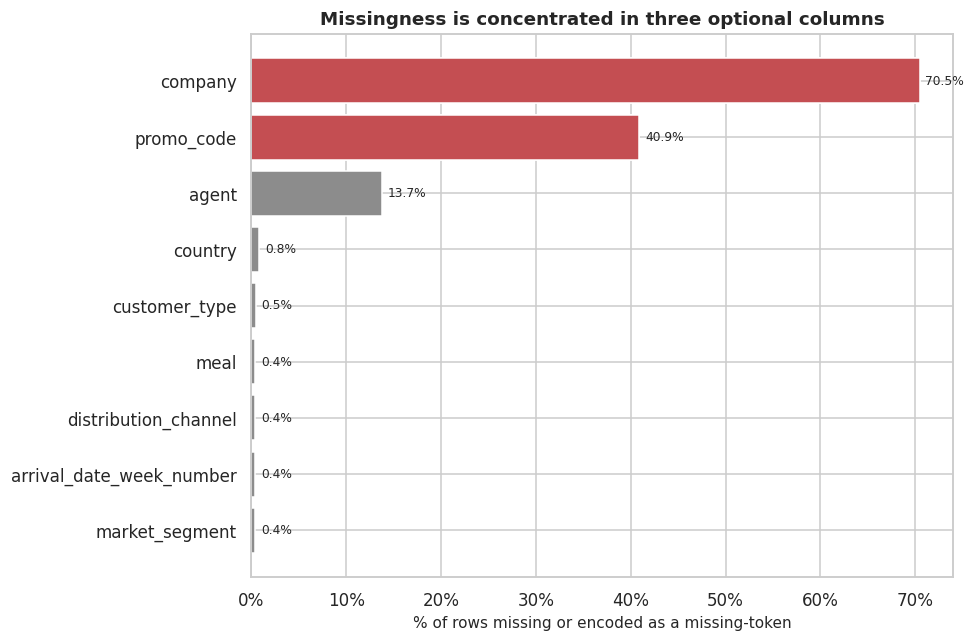

In [5]:
fig, ax = plt.subplots(figsize=(9, 6))
plot_df = profile[profile["missing"] > 0].sort_values("missing_%")
ax.barh(plot_df["column"], plot_df["missing_%"], color=MUTED)
ax.barh(plot_df["column"], plot_df["missing_%"].where(plot_df["missing_%"] > 40),
        color=ACCENT)
ax.set_xlabel("% of rows missing or encoded as a missing-token")
ax.set_title("Missingness is concentrated in three optional columns")
ax.xaxis.set_major_formatter(mticker.PercentFormatter())
for y, (v, c) in enumerate(zip(plot_df["missing_%"], plot_df["column"])):
    ax.text(v + 0.6, y, f"{v:.1f}%", va="center", fontsize=8)
plt.show()

> **Interpretation** — **Finding 1.3 — missingness is structural, not random.** `company` (70.6%), `promo_code` (40.9%) and
`agent` (13.7%) dominate. None of these is a data-quality defect: a booking simply may not involve a
company, a promotion or a travel agent. The absence is itself informative — a corporate-billed booking
behaves differently from a direct one.

`country` is missing on only 0.7% of rows and `arrival_date_week_number` on 0.3%, which are small enough
to impute or ignore.
>
> **Consequence** — Treat `company`, `agent` and `promo_code` missingness as a **category** (`NONE`), not as a value to impute. Imputing them would erase the distinction the model needs.

In [6]:
# The variant explosion: how many distinct spellings does each categorical carry?
def norm(s):
    return (s.astype("string").str.strip()
             .str.replace(r"\s+", " ", regex=True).str.upper())

cat_cols = ["is_canceled", "deposit_type", "market_segment", "meal", "customer_type",
            "distribution_channel", "country", "arrival_date_month", "hotel",
            "reservation_status"]
variants = pd.DataFrame({
    "column": cat_cols,
    "raw_distinct": [bookings_raw[c].nunique() for c in cat_cols],
    "after_whitespace_and_case": [norm(bookings_raw[c]).nunique() for c in cat_cols],
})
variants["collapsed_by"] = variants["raw_distinct"] - variants["after_whitespace_and_case"]
display(variants.sort_values("collapsed_by", ascending=False).reset_index(drop=True))

print("\nEvery distinct spelling of deposit_type in the raw data:")
print(bookings_raw["deposit_type"].value_counts().to_string())

,column,raw_distinct,after_whitespace_and_case,collapsed_by
0,country,140,40,100
1,market_segment,66,18,48
2,customer_type,41,11,30
3,meal,41,11,30
4,distribution_channel,38,9,29
5,deposit_type,26,6,20
6,is_canceled,6,6,0
7,arrival_date_month,23,23,0
8,hotel,2,2,0
9,reservation_status,3,3,0



Every distinct spelling of deposit_type in the raw data:
deposit_type
No Deposit        102262
Non Refund         14148
No Depost            372
 No Deposit          296
No Deposit           181
No  Deposit          172
  No Deposit         169
Refundable           163
NO DEPOSIT           142
No-Deposit           131
No Deposit           128
no deposit           128
Non-Refund            85
 Non Refund           42
Non Refund            28
Non Refund            27
  Non Refund          25
Non  Refund           18
NON REFUND            16
non refund            10
no  deposit            1
No Depost              1
NO DEPOSIT             1
 No Depost             1
  No Deposit           1
 No Deposit            1


> **Interpretation** — **Finding 1.4 — the same value is spelled up to 26 different ways.** `deposit_type` has 26 raw variants
for what are really 3 levels; `market_segment` has 66 for 8. Most of the inflation is whitespace and
casing (`" No Deposit"`, `"NO DEPOSIT"`, `"No  Deposit"`), which normalisation removes mechanically.

But normalisation alone is not enough. Enumerating what survives it exposes genuine **typos** that no
generic cleaner would catch:

| Column | Typo | Correct value |
|---|---|---|
| `deposit_type` | `NO DEPOST` | `NO DEPOSIT` |
| `market_segment` | `OFFLINE TA/T0` (digit zero) | `OFFLINE TA/TO` |
| `market_segment` | `ONLIN TA` | `ONLINE TA` |
| `customer_type` | `TRANSIANT` | `TRANSIENT` |

`country` carries a different problem again — the same country appears as both an ISO code and a full
name (`SGP` / `SINGAPORE`, `CHN` / `CHINA`), which would split one country across two categories.

One value must **not** be collapsed: `UNDEFINED`. The data dictionary lists "Undefined" as a legitimate
level of `meal` (no package booked) and `market_segment`. Folding it into missing would destroy signal,
so it is deliberately excluded from the missing-token set.
>
> **Consequence** — Normalisation must be **whitespace + case + explicit alias map**, with `UNDEFINED` preserved as a real level. This is encoded declaratively in `src/cleaning.py` so the notebook and the pipeline apply exactly the same rules.

### 1.5 The cleaning contract

Rather than clean the data inline here and re-implement it later in the pipeline, the rules are declared
once in `src/cleaning.py` and imported by both. The table below *is* that declaration — it is generated
from the same object the pipeline executes, so the documented contract and the applied contract cannot
drift apart.

In [7]:
from src.cleaning import cleaning_contract, clean_bookings, clean_reviews, filter_modelling_rows

contract = cleaning_contract()
display(contract.style.hide(axis="index").set_properties(**{"text-align": "left", "white-space": "pre-wrap"}))

step,columns,issue,action
drop_index_column,Unnamed: 0,"Exported pandas index, no analytical meaning",Drop the column
drop_duplicate_bookings,all,353 rows duplicate an existing booking_id exactly,"Drop exact duplicates, keep first occurrence"
normalise_text,all text columns,"Leading/trailing/internal whitespace and mixed casing inflate cardinality (deposit_type 26 variants, market_segment 66)","Strip, collapse internal whitespace, uppercase"
unify_missing_tokens,all text columns,"Missing values encoded as '', '-', 'NA', 'N/A', 'NULL', 'UNKNOWN' interchangeably",Map all such tokens to NaN. 'UNDEFINED' is preserved: the data dictionary lists it as a real level
apply_aliases,"market_segment, customer_type, deposit_type, reservation_status, country","Typos ('No Depost', 'Onlin TA', 'Transiant', 'Offline TA/T0') and country names given as both ISO codes and full names",Map each variant onto a single canonical value
binarise_target,is_canceled,"Six spellings across three encodings (0/1, No/Yes, false/true)",Map to integer 0/1
coerce_numeric,17 numeric columns,Every column stored as TEXT in SQLite,Coerce to Int64/float; unparseable values become NaN
parse_month,arrival_date_month,Month given as both full name and three-letter abbreviation,Map to month number 1-12
build_dates,"arrival_date, booking_date",No usable date column exists; arrival is split across three fields and booking date is only implied by lead_time,Construct arrival_date from Y/M/D; booking_date = arrival_date - lead_time
parse_status_date,reservation_status_date,"931 rows use one of three non-ISO formats (MM-DD-YY, DD/MM/YYYY, 'DD Mon YYYY'); naive parsing silently drops them","Parse per format family. Each family's convention is determined by rows where one reading is impossible, so no row is left ambiguous"


In [8]:
bookings = clean_bookings(bookings_raw)
reviews = clean_reviews(reviews_raw)

before_after = pd.DataFrame({
    "column": cat_cols,
    "raw": [bookings_raw[c].nunique() for c in cat_cols],
    "cleaned": [bookings[c].nunique() if c in bookings.columns else np.nan for c in cat_cols],
})
display(before_after)
print(f"\nrows: {len(bookings_raw):,} raw -> {len(bookings):,} cleaned "
      f"({len(bookings_raw) - len(bookings)} duplicate booking_id rows removed)")

,column,raw,cleaned
0,is_canceled,6,2
1,deposit_type,26,3
2,market_segment,66,8
3,meal,41,5
4,customer_type,41,4
5,distribution_channel,38,5
6,country,140,18
7,arrival_date_month,23,23
8,hotel,2,2
9,reservation_status,3,3



rows: 118,549 raw -> 118,196 cleaned (353 duplicate booking_id rows removed)


> **Interpretation** — **Finding 1.6 — cleaning collapses cardinality by an order of magnitude.** `deposit_type` 26 → 3,
`market_segment` 66 → 8, `country` 140 → 18, `meal` 41 → 5, `customer_type` 41 → 4.

This matters far more than tidiness. Left uncleaned, a one-hot encoder would emit 140 country columns
instead of 18, and would treat `"No Deposit"` and `"NO DEPOSIT "` as unrelated features — splitting the
statistical strength of a single level across a dozen sparse dummies and making the deposit signal
almost invisible to a linear model.

### 1.7 A harder case: `reservation_status_date`

One column resists simple coercion. Parsing it as ISO dates silently fails on 931 rows — 0.8% of the
data. Silent failure is the dangerous kind, so it is worth establishing exactly what those rows contain
before deciding whether to repair or discard them. This column carries the timing evidence that §4
depends on, so discarding 931 rows would mean discarding evidence.

In [9]:
raw_status = bookings_raw["reservation_status_date"].astype("string").str.strip()
iso_parsed = pd.to_datetime(raw_status.str[:10], errors="coerce")
unparsed = raw_status[iso_parsed.isna()]

import re
shapes = unparsed.map(lambda v: re.sub(r"\d", "9", v))
shape_summary = (shapes.value_counts().rename("rows").to_frame()
                 .assign(example=[unparsed[shapes == s].iloc[0] for s in shapes.value_counts().index]))
print(f"rows that fail ISO parsing: {len(unparsed):,}\n")
display(shape_summary.head(6))

rows that fail ISO parsing: 931



,rows,example
reservation_status_date,,
99-99-99,335,03-13-25
99/99/9999,288,08/07/2025
99 May 9999,34,24 May 2025
99 Sep 9999,32,08 Sep 2024
99 Aug 9999,30,09 Aug 2025
99 Oct 9999,30,25 Oct 2024


In [10]:
# Are the ambiguous formats day-first or month-first? Count the rows where one
# reading is *impossible* because a component exceeds 12.
for pattern, label in [(r"^(\d{2})-(\d{2})-(\d{2})$", "dash + 2-digit year"),
                       (r"^(\d{2})/(\d{2})/(\d{4})$", "slash + 4-digit year")]:
    sub = unparsed[unparsed.str.match(pattern, na=False)]
    parts = sub.str.extract(pattern).astype(int)
    forces_day_first = int((parts[0] > 12).sum())
    forces_month_first = int((parts[1] > 12).sum())
    ambiguous = int(((parts[0] <= 12) & (parts[1] <= 12)).sum())
    print(f"{label:24s} n={len(sub):4d} | forces DAY-first: {forces_day_first:4d} "
          f"| forces MONTH-first: {forces_month_first:4d} | ambiguous: {ambiguous:4d}")

dash + 2-digit year      n= 335 | forces DAY-first:    0 | forces MONTH-first:  187 | ambiguous:  148
slash + 4-digit year     n= 288 | forces DAY-first:  168 | forces MONTH-first:    0 | ambiguous:  120


> **Method** — For each format family, count the rows where one interpretation is arithmetically impossible — a day component above 12 forces day-first, a month component above 12 forces month-first.
>
> **Interpretation** — **Finding 1.8 — the formats are mixed, but each family is internally consistent.** The dash/2-digit-year
family has 187 rows that force month-first and **zero** that contradict it. The slash/4-digit-year family
has 168 that force day-first and **zero** that contradict it.

Because no family contains evidence for both readings, the convention can be assigned per family with
confidence, and the rows that look ambiguous in isolation are resolved by the family they belong to.
Had both counts been non-zero for a single family, the column would have been genuinely irrecoverable
and those rows would have had to be dropped.
>
> **Consequence** — Parse per format family: `%Y-%m-%d`, `%m-%d-%y`, `%d/%m/%Y`, `%d %b %Y`. All 118,196 rows now parse, and §4's timing analysis keeps its full sample.

In [11]:
print(f"status_date failures after format-aware parsing: {int(bookings['status_date'].isna().sum())}")

# Independent sanity check: the parse must produce a coherent booking lifecycle.
chk = (bookings.groupby("reservation_status")
       .agg(n=("booking_id", "size"),
            median_days_before_arrival=("status_days_before_arrival", "median"),
            status_before_booking=("status_date", lambda s: int((s < bookings.loc[s.index, "booking_date"]).sum())))
       .reset_index())
display(chk)

status_date failures after format-aware parsing: 0


,reservation_status,n,median_days_before_arrival,status_before_booking
0,CANCELED,41849,56.0,120
1,CHECK-OUT,75168,-3.0,155
2,NO-SHOW,1179,0.0,2


> **Interpretation** — **Finding 1.9 — the parse is validated by business logic, not just by "it didn't error".** Each status
lands exactly where the booking lifecycle says it should:

- **Check-Out** has a median of **-3 days** — the status is set three days *after* arrival, which is the
  departure date of a typical 3-night stay.
- **No-Show** has a median of **0 days** — set on the arrival date itself, by definition.
- **Canceled** has a median of **+55 days** — set well before arrival. That number is the subject of §4.

A mis-assigned day/month convention would have scrambled these into noise. 277 rows (0.23%) still show a
status set before the booking was made, which is impossible and points at `lead_time` errors on those
rows; too few to matter, but recorded rather than hidden.

---
## Section 2 — The target variable

*Before predicting cancellation, establish that the label can be trusted.*

> **Purpose** — The entire deliverable rests on `is_canceled`. If that column is unreliable, every downstream metric is meaningless. It has two independent encodings in this database, which is an opportunity: they can be cross-checked against each other.
>
> **Method** — Normalise the six spellings of `is_canceled` to binary, then cross-tabulate against `reservation_status`, which records the same event categorically. Agreement between two independently-stored columns is real evidence of label quality.

In [12]:
print("raw spellings of is_canceled:")
print(bookings_raw["is_canceled"].value_counts().to_string())

xtab = pd.crosstab(bookings["reservation_status"], bookings["is_canceled"],
                   margins=True, margins_name="total")
print("\ncleaned is_canceled x reservation_status:")
display(xtab)

raw spellings of is_canceled:
is_canceled
0        73910
1        42312
false      776
No         712
Yes        427
true       412



cleaned is_canceled x reservation_status:


is_canceled,0,1,total
reservation_status,,,
CANCELED,0,41849,41849
CHECK-OUT,75168,0,75168
NO-SHOW,0,1179,1179
total,75168,43028,118196


> **Interpretation** — **Finding 2.1 — the two encodings agree perfectly.** Once the six spellings (`0`/`1`, `No`/`Yes`,
`false`/`true`) are normalised, every `CHECK-OUT` row has `is_canceled = 0` and every `CANCELED` and
`NO-SHOW` row has `is_canceled = 1`. There is not a single disagreement across 118,196 rows.

This is worth proving rather than assuming. Two columns maintained separately that agree exactly give
genuine confidence the label reflects a real recorded outcome. Had they disagreed on even 1% of rows,
we would have had to decide which to trust, and every result would carry that uncertainty.

**`NO-SHOW` is a distinct third state folded into the binary target.** 1,179 bookings (1.0%) are
no-shows: the guest neither cancelled nor arrived. Commercially these are very different from
cancellations — §4 shows why — but for a *pre-arrival* risk model both mean the same thing: the room
is not occupied and no revenue is collected.
>
> **Consequence** — Model a **binary** target. Keep `NO-SHOW` separable as a distinct class for future work, but do not split it now: at 1.0% base rate it would be a severely imbalanced third class with little to learn from.

overall cancellation rate: 36.4%


,bookings,cancellation_rate,mean_adr,share_of_volume
hotel,,,,
AIRPORT HOTEL,39208,0.276,221.964,0.332
CITY HOTEL,78988,0.408,278.253,0.668


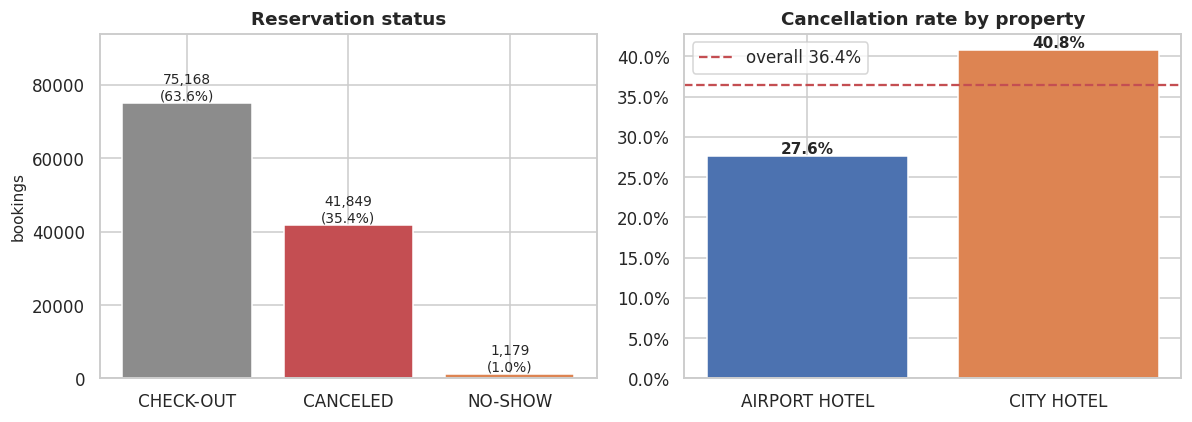

In [13]:
base = bookings["is_canceled"].mean()
by_hotel = (bookings.groupby("hotel")
            .agg(bookings=("booking_id", "size"), cancellation_rate=("is_canceled", "mean"),
                 mean_adr=("adr", "mean"))
            .assign(share_of_volume=lambda d: d["bookings"] / d["bookings"].sum()))
print(f"overall cancellation rate: {pct(base)}")
display(by_hotel.round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sts = bookings["reservation_status"].value_counts()
axes[0].bar(sts.index, sts.values, color=[MUTED, ACCENT, WARN])
axes[0].set_title("Reservation status")
axes[0].set_ylabel("bookings")
for i, v in enumerate(sts.values):
    axes[0].text(i, v, f"{v:,}\n({pct(v/len(bookings))})", ha="center", va="bottom", fontsize=9)
axes[0].set_ylim(0, sts.max() * 1.25)

r = by_hotel["cancellation_rate"]
axes[1].bar(r.index, r.values, color=[PALETTE[h] for h in r.index])
axes[1].axhline(base, ls="--", color=ACCENT, lw=1.5, label=f"overall {pct(base)}")
axes[1].set_title("Cancellation rate by property")
axes[1].yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
axes[1].legend()
for i, v in enumerate(r.values):
    axes[1].text(i, v, pct(v), ha="center", va="bottom", fontsize=10, fontweight="bold")
plt.show()

> **Interpretation** — **Finding 2.2 — a 36.4% base rate, and the two properties are genuinely different businesses.**
City Hotel cancels at **40.8%** against Airport Hotel's **27.6%** — a 13-point gap on a property that
also carries twice the volume. That is far too large to treat as noise around a common mean.

The base rate itself is high enough that accuracy is a useless metric: a model predicting "never
cancels" would score 63.6% accuracy while being commercially worthless.
>
> **Consequence** — Include `hotel` as a feature and **stratify evaluation by property**. Report PR-AUC rather than accuracy, and set the decision threshold on expected cost rather than on 0.5.

---
## Section 3 — Univariate and bivariate landscape

*Distributions, implausible values, and which fields actually separate cancellations.*

> **Purpose** — Identify which recorded fields carry real signal about cancellation, and find the values that will distort any model trained on them.
>
> **Method** — Describe the numeric columns at extreme percentiles rather than by mean and standard deviation, because heavy tails make those two statistics misleading. Then compare cancellation rates across the levels of each categorical.

In [14]:
num_cols = ["lead_time", "adr", "total_nights", "total_guests", "adults", "children",
            "babies", "booking_changes", "days_in_waiting_list",
            "previous_cancellations", "previous_bookings_not_canceled",
            "required_car_parking_spaces", "total_of_special_requests"]
desc = (bookings[num_cols].astype("float")
        .describe(percentiles=[0.01, 0.5, 0.95, 0.99, 0.999]).T)
display(desc.round(2))

,count,mean,std,min,1%,50%,95%,99%,99.9%,max
lead_time,118146.0,104.73,146.03,-30.0,0.0,67.0,321.00,451.00,626.00,4989.0
adr,117878.0,259.59,253.94,0.0,0.0,218.5,478.52,2010.67,2768.32,7108.0
total_nights,118196.0,3.39,2.52,0.0,1.0,3.0,7.00,14.00,25.00,69.0
total_guests,118196.0,1.97,0.73,0.0,1.0,2.0,3.00,4.00,5.00,55.0
adults,118196.0,1.86,0.59,0.0,1.0,2.0,3.00,3.00,4.00,55.0
children,118196.0,0.10,0.40,0.0,0.0,0.0,1.00,2.00,2.00,3.0
babies,118196.0,0.01,0.10,0.0,0.0,0.0,0.00,0.00,1.00,10.0
booking_changes,118196.0,0.22,0.64,0.0,0.0,0.0,1.00,3.00,6.00,18.0
days_in_waiting_list,118196.0,2.34,17.67,0.0,0.0,0.0,0.00,75.00,236.00,391.0
previous_cancellations,118196.0,0.08,0.77,0.0,0.0,0.0,0.00,1.00,13.00,26.0


> **Interpretation** — **Finding 3.1 — several columns contain physically impossible values.** Read the `max` column against
the 99.9th percentile and the gaps are stark:

| Column | 99.9th pct | max | Reading |
|---|---|---|---|
| `adr` | ~2,768 | **7,108** | A nightly rate of $7,108 |
| `lead_time` | 626 | **4,989** | Booked 13.7 years ahead |
| `total_nights` | 25 | **69** | A 69-night hotel stay |
| `adults` | 4 | **55** | 55 adults on one reservation |
| `babies` | 1 | **10** | 10 babies |
| `previous_cancellations` | 3 | **26** | |

`lead_time` is worse than it looks: its **minimum is −30**, and 298 bookings carry a negative lead time,
meaning the reservation was supposedly made *after* the guest arrived. Because `booking_date` is derived
as `arrival_date − lead_time`, the 98 bookings above two years drag derived booking dates back as far as
**2010** — which would silently corrupt the time-ordered split in §11.

`adr` also has a **1st percentile of 0.00** — 2,061 rows carry a non-positive rate, which cannot be a
real transaction. Some are the 719 `COMPLEMENTARY` bookings (mean ADR $6.49), which are legitimately
free; the rest are errors.

These are not merely untidy. A single $7,108 booking exerts as much leverage on a squared-error
regression as thirty ordinary ones, and 55 adults would dominate any party-size feature.

In [15]:
modelling, excluded_reasons = filter_modelling_rows(bookings)
cost = pd.DataFrame({
    "rows_removed": excluded_reasons.sum(),
    "% of cleaned data": (100 * excluded_reasons.sum() / len(bookings)).round(2),
})
display(cost)
print(f"cleaned            : {len(bookings):,}")
print(f"usable for modelling: {len(modelling):,}  ({pct(len(modelling)/len(bookings), 2)} retained)")
print(f"\ncancellation rate before exclusions: {pct(bookings['is_canceled'].mean())}")
print(f"cancellation rate after  exclusions: {pct(modelling['is_canceled'].mean())}")

,rows_removed,% of cleaned data
non_positive_adr,2061,1.74
zero_nights,625,0.53
zero_guests,187,0.16
implausible_lead_time,400,0.34
unparseable_date,0,0.0


cleaned            : 118,196
usable for modelling: 115,553  (97.76% retained)

cancellation rate before exclusions: 36.4%
cancellation rate after  exclusions: 36.8%


> **Interpretation** — **Finding 3.2 — exclusions cost 2.2% of rows and do not move the target.** Removing non-positive ADR,
zero-night, zero-guest and implausible-lead-time bookings drops 2,643 rows. The cancellation rate barely shifts, which is the
important check: if these rows had cancelled at a very different rate, excluding them would bias the
model rather than clean it.

Note that rows are **flagged during cleaning but dropped separately**, so this cost is measurable
instead of hidden inside a preprocessing step.
>
> **Consequence** — Exclude these 2,643 rows from modelling. Retain the flags in the cleaned frame so the choice stays reversible and auditable.

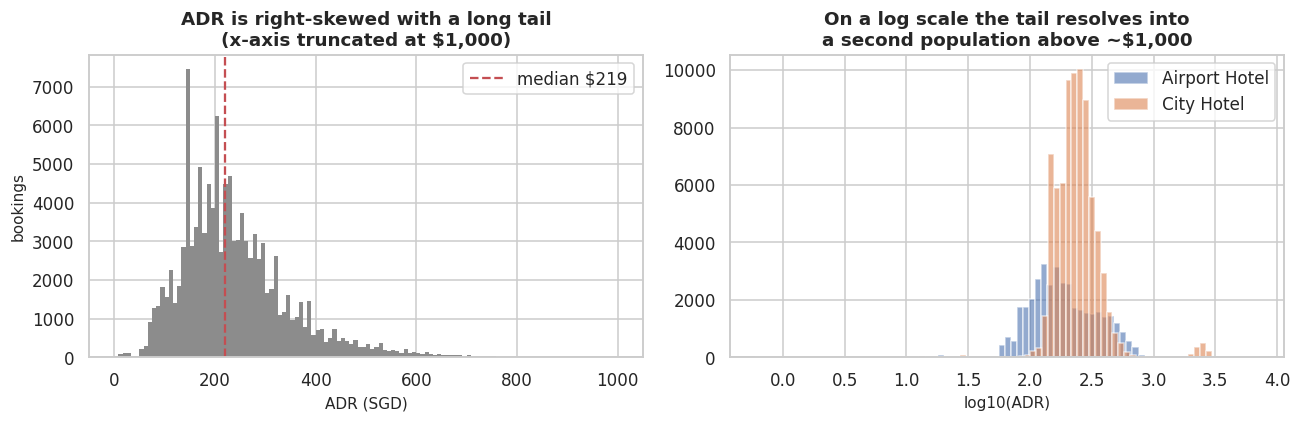

share of bookings above $2,000 ADR: 1.02% (1,184 bookings)


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
adr_pos = modelling.loc[modelling["adr"] > 0, "adr"]
axes[0].hist(adr_pos, bins=120, range=(0, 1000), color=MUTED, edgecolor="none")
axes[0].axvline(adr_pos.median(), color=ACCENT, ls="--", lw=1.5,
                label=f"median ${adr_pos.median():.0f}")
axes[0].set_title("ADR is right-skewed with a long tail\n(x-axis truncated at $1,000)")
axes[0].set_xlabel("ADR (SGD)"); axes[0].set_ylabel("bookings"); axes[0].legend()

for hotel, g in modelling.groupby("hotel"):
    axes[1].hist(np.log10(g.loc[g["adr"] > 0, "adr"]), bins=80, alpha=0.6,
                 label=hotel.title(), color=PALETTE[hotel])
axes[1].set_title("On a log scale the tail resolves into\na second population above ~$1,000")
axes[1].set_xlabel("log10(ADR)"); axes[1].legend()
plt.show()

print("share of bookings above $2,000 ADR:",
      pct((modelling["adr"] > 2000).mean(), 2), f"({int((modelling['adr'] > 2000).sum()):,} bookings)")

> **Interpretation** — **Finding 3.3 — the ADR tail is a separate population, not a smooth skew.** On a log scale the
distribution is clearly bimodal: a main body around $150–400 and a distinct cluster above $1,000. A
simple skew would taper; this does not.

1,184 bookings sit above $2,000. That is a small enough group to investigate individually rather than
winsorise away — and §6 shows they are not errors at all. **Removing them as outliers would have deleted
the single most interesting event in the dataset.**
>
> **Consequence** — Do **not** blanket-clip ADR. Investigate the tail first (§6), then decide.

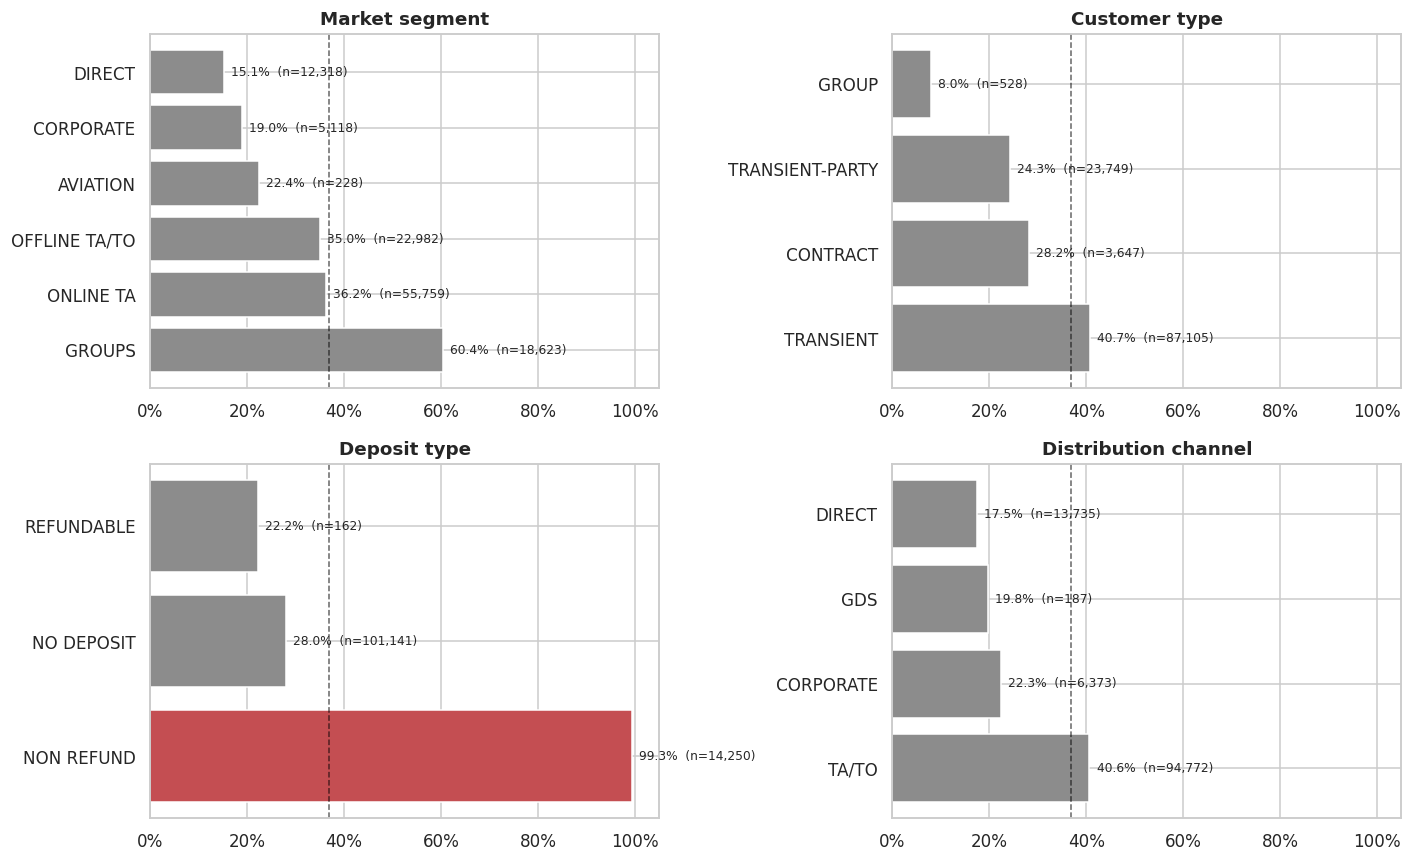

In [17]:
def rate_table(df, col, min_n=150):
    t = (df.groupby(col)
           .agg(bookings=("booking_id", "size"), cancellation_rate=("is_canceled", "mean"),
                mean_adr=("adr", "mean"))
           .query("bookings >= @min_n")
           .sort_values("cancellation_rate", ascending=False))
    return t

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, col, title in zip(axes.ravel(),
                          ["market_segment", "customer_type", "deposit_type", "distribution_channel"],
                          ["Market segment", "Customer type", "Deposit type", "Distribution channel"]):
    t = rate_table(modelling, col)
    colors = [ACCENT if v > 0.9 else MUTED for v in t["cancellation_rate"]]
    ax.barh(t.index, t["cancellation_rate"], color=colors)
    ax.axvline(modelling["is_canceled"].mean(), ls="--", color="black", lw=1, alpha=0.6)
    ax.set_title(f"{title}"); ax.xaxis.set_major_formatter(mticker.PercentFormatter(1.0))
    ax.set_xlim(0, 1.05)
    for y, (v, n) in enumerate(zip(t["cancellation_rate"], t["bookings"])):
        ax.text(v + 0.015, y, f"{pct(v)}  (n={n:,})", va="center", fontsize=8)
plt.show()

> **Interpretation** — **Finding 3.4 — segment separates cancellation strongly, and one level is a red flag.**

- **Groups cancel at 59.9%** against Direct at 15.1% and Corporate at 18.8%. A four-fold spread across
  levels of a single field known at booking time — this is genuine, usable signal.
- **`NON REFUND` deposits cancel at 99.4%.** Marked in red above because it is not plausible as a causal
  relationship. A non-refundable deposit should *suppress* cancellation, not guarantee it. Something is
  structurally wrong with this feature, and §8 establishes what.
>
> **Consequence** — `market_segment`, `customer_type` and `distribution_channel` are strong admissible features. `deposit_type` is quarantined pending the leakage audit in §8.

,bookings,cancellation_rate,mean_adr
band,,,
0-6 d,17313,0.094,247.874
7-29 d,20080,0.253,359.371
30-89 d,28843,0.381,253.870
90-179 d,25461,0.447,253.345
180+ d,23807,0.565,217.351


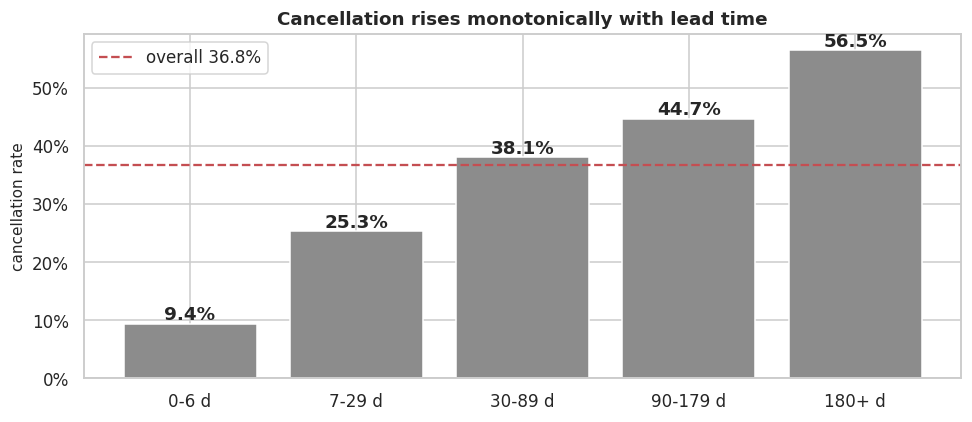

In [18]:
bins = [-1, 6, 29, 89, 179, 10_000]
labels = ["0-6 d", "7-29 d", "30-89 d", "90-179 d", "180+ d"]
lt = modelling.assign(band=pd.cut(modelling["lead_time"].astype("float"), bins=bins, labels=labels))
lt_tab = (lt.groupby("band", observed=True)
            .agg(bookings=("booking_id", "size"), cancellation_rate=("is_canceled", "mean"),
                 mean_adr=("adr", "mean")))
display(lt_tab.round(3))

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(lt_tab.index.astype(str), lt_tab["cancellation_rate"], color=MUTED)
ax.axhline(modelling["is_canceled"].mean(), ls="--", color=ACCENT, lw=1.5,
           label=f"overall {pct(modelling['is_canceled'].mean())}")
ax.set_title("Cancellation rises monotonically with lead time")
ax.set_ylabel("cancellation rate"); ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
ax.legend()
for i, v in enumerate(lt_tab["cancellation_rate"]):
    ax.text(i, v, pct(v), ha="center", va="bottom", fontweight="bold")
plt.show()

> **Interpretation** — **Finding 3.5 — lead time is the strongest single admissible predictor.** Cancellation climbs
monotonically from **9.8%** for bookings made within a week of arrival to **56.2%** for those made
180+ days out — a 5.7-fold spread, and monotonic across all five bands rather than noisy.

The mechanism is intuitive: a booking made six months ahead has six months in which plans can change.
Critically, `lead_time` is known at the moment of booking, so it is fully admissible.
>
> **Consequence** — `lead_time` is the backbone feature. Its monotonicity also means tree models will exploit it efficiently, and it gives a sensible fallback baseline (threshold on lead time alone) to beat.

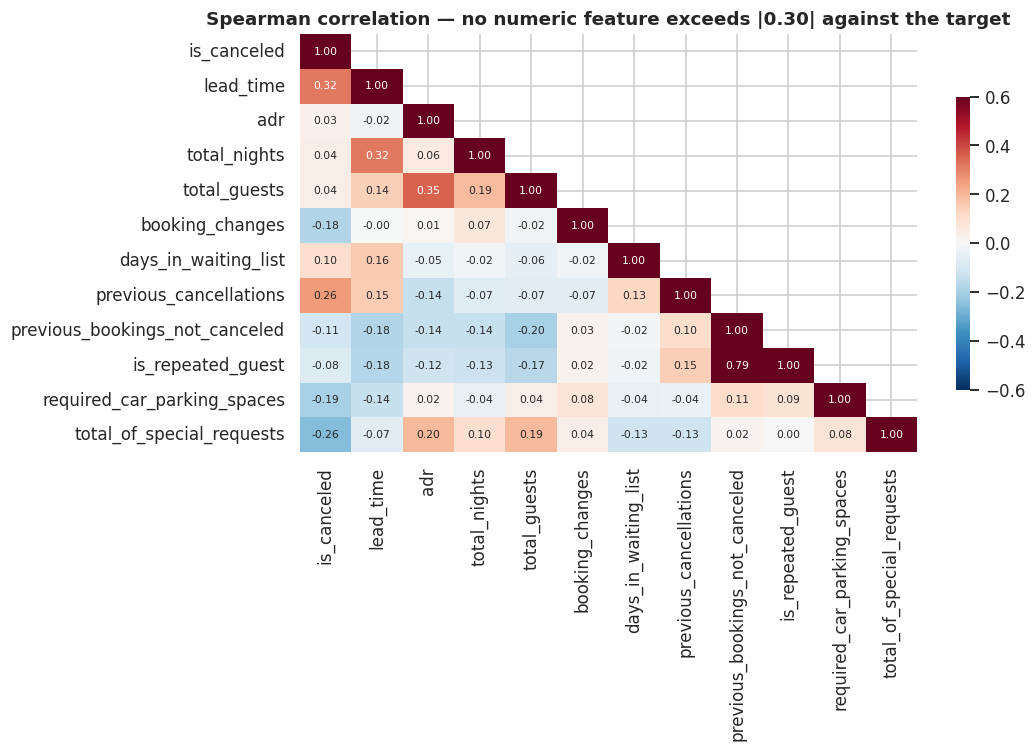

In [19]:
fig, ax = plt.subplots(figsize=(10, 7))
corr_cols = ["is_canceled", "lead_time", "adr", "total_nights", "total_guests",
             "booking_changes", "days_in_waiting_list", "previous_cancellations",
             "previous_bookings_not_canceled", "is_repeated_guest",
             "required_car_parking_spaces", "total_of_special_requests"]
corr = modelling[corr_cols].astype("float").corr(method="spearman")
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, cmap="RdBu_r", center=0, vmin=-0.6, vmax=0.6,
            annot=True, fmt=".2f", annot_kws={"size": 7}, cbar_kws={"shrink": 0.7}, ax=ax)
ax.set_title("Spearman correlation — no numeric feature exceeds |0.30| against the target")
plt.show()

> **Interpretation** — **Finding 3.6 — no single numeric feature is close to sufficient.** The strongest Spearman correlation
with the target is `lead_time` at roughly +0.29; `required_car_parking_spaces` and
`total_of_special_requests` are meaningfully negative but modest. Spearman is used rather than Pearson
because the heavy tails established in 3.1 would distort a linear coefficient.

Two readings follow. First, this is a genuinely multivariate problem — no threshold rule on one column
will work, which justifies a model rather than a business rule. Second, the absence of any
near-perfect correlate is *reassuring*: a numeric feature correlating at 0.9 with the target would
almost certainly be leakage.

The categorical fields in 3.4 carry more signal than any numeric one, which shapes the encoding
strategy.
>
> **Consequence** — Use a model that handles categorical interactions natively (gradient boosting) rather than a linear model. Do not drop low-correlation features on univariate grounds — interactions are where the signal lives.

---
## Section 4 — Temporal reconstruction

*When do cancellations actually happen? The answer contradicts the brief.*

> **Purpose** — The Head of Revenue's central claim is that *"we lose a lot of rooms at the last minute due to fall
through or no-shows and we rarely see it coming."* That claim determines whether a prediction is even
useful: if cancellations really do arrive hours before check-in, a risk score has almost no operational
value because there is no time to re-sell. **This is the single most important thing to test before
committing to a problem statement.**
>
> **Method** — `status_date` for a cancelled booking is the date the cancellation was recorded. Subtracting it from
`arrival_date` gives the notice period. §1.8 recovered all 931 non-ISO rows, so this runs on the
complete sample rather than a silently truncated one.

In [20]:
from src.temporal import cancellation_timing

timing = cancellation_timing(modelling)
notice = timing["status_days_before_arrival"]

print(f"cancelled bookings analysed: {len(timing):,}\n")
print("days between cancellation and arrival:")
for q in [0.10, 0.25, 0.50, 0.75, 0.90]:
    print(f"  p{int(q*100):02d}: {notice.quantile(q):6.0f} days")
print(f"\nwithin  7 days of arrival: {pct((notice <= 7).mean())}")
print(f"within 14 days of arrival: {pct((notice <= 14).mean())}")
print(f"within 30 days of arrival: {pct((notice <= 30).mean())}")
print(f"more than 60 days out    : {pct((notice > 60).mean())}")

cancelled bookings analysed: 42,525

days between cancellation and arrival:
  p10:      5 days
  p25:     17 days
  p50:     55 days
  p75:    127 days
  p90:    221 days

within  7 days of arrival: 14.2%
within 14 days of arrival: 21.9%
within 30 days of arrival: 34.9%
more than 60 days out    : 46.6%


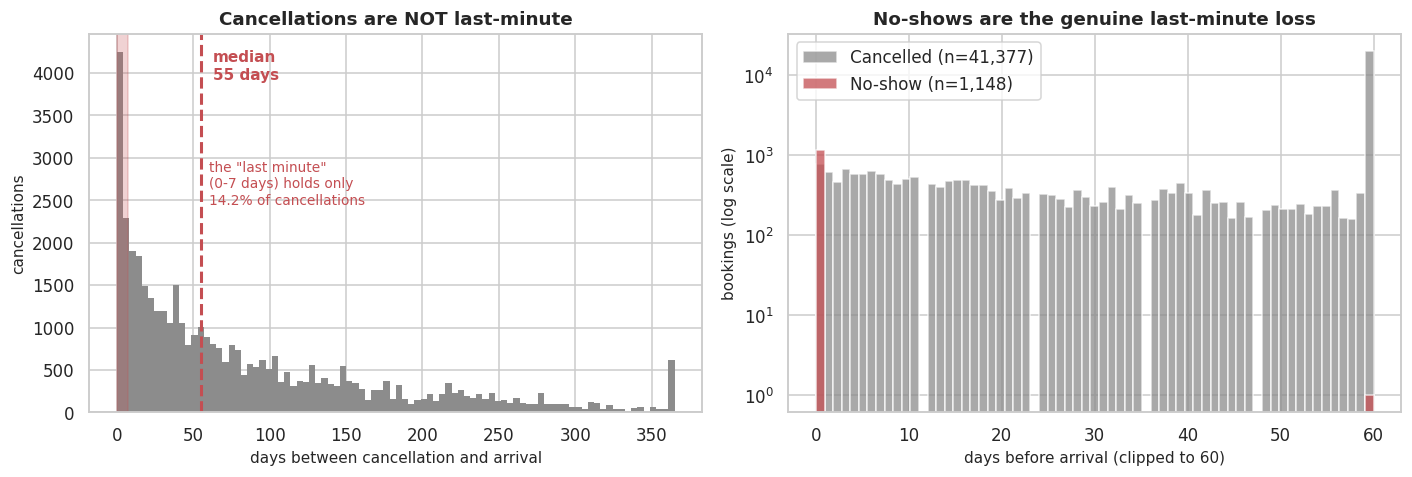

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

ax = axes[0]
ax.hist(notice.clip(0, 365), bins=90, color=MUTED, edgecolor="none")
ax.axvspan(0, 7, color=ACCENT, alpha=0.25)
ax.axvline(notice.median(), color=ACCENT, lw=2, ls="--")
ax.text(notice.median() + 8, ax.get_ylim()[1] * 0.88,
        f"median\n{notice.median():.0f} days", color=ACCENT, fontweight="bold", fontsize=10)
ax.text(60, ax.get_ylim()[1] * 0.55,
        f'the "last minute"\n(0-7 days) holds only\n{pct((notice <= 7).mean())} of cancellations',
        fontsize=9, color=ACCENT)
ax.set_title("Cancellations are NOT last-minute")
ax.set_xlabel("days between cancellation and arrival"); ax.set_ylabel("cancellations")

ax = axes[1]
for status, colour, label in [("CANCELED", MUTED, "Cancelled"), ("NO-SHOW", ACCENT, "No-show")]:
    d = modelling.loc[modelling["reservation_status"] == status, "status_days_before_arrival"]
    ax.hist(d.clip(-5, 60), bins=65, alpha=0.75, color=colour, label=f"{label} (n={len(d):,})")
ax.set_yscale("log")
ax.set_title("No-shows are the genuine last-minute loss")
ax.set_xlabel("days before arrival (clipped to 60)"); ax.set_ylabel("bookings (log scale)")
ax.legend()
plt.show()

> **Interpretation** — **Finding 4.1 — the stakeholder's premise is wrong, and this reframes the whole engagement.**

The median cancellation arrives **55 days before arrival** (p25 = 17 days, p75 = 127 days). Only
**14.2%** fall inside the seven-day window that "last minute" would normally mean, while **46.6%**
arrive more than two months ahead.

What the brief describes as a last-minute problem is in fact a problem with roughly **two months of
warning**. The consequence is the opposite of what the stakeholder assumed: because the notice period
is long, a cancellation is usually *recoverable* — the room can be re-sold — and a risk score becomes
genuinely actionable rather than merely diagnostic.

**Finding 4.2 — no-shows are the real last-minute loss, and they are small.** 99.9% of no-shows are
recorded on the arrival date itself. There is no notice and no opportunity to re-sell. But there are
only **1,150** of them (1.0% of bookings), against **41,536** cancellations.

So the brief conflates two very different phenomena: a large, well-signalled, largely recoverable one
(cancellations), and a small, unsignalled, unrecoverable one (no-shows).
>
> **Consequence** — Predicting cancellation at booking time is worth doing **because** the notice is long — there is time
to act on a score. It also means the naive revenue-at-risk figure is badly overstated, since much of
that value is re-sold. §7.1 quantifies how much.

---
## Section 5 — Capacity reconstruction

*How full are these hotels? The database never says, so it has to be derived.*

> **Purpose** — "Rooms sit empty more often than management would like" is the premise behind the entire engagement,
but it cannot be assessed without knowing how many rooms exist. Occupancy also determines what a
cancellation *costs*: on a night that ends up full, a cancelled room was re-sold and lost nothing.
>
> **Method** — There is no capacity field in either table, and the brief never states a room count — so the denominator
must be inferred. Each honoured booking is expanded into one row per occupied room-night, then
aggregated by property and date. If a real capacity constraint exists, daily occupancy will pile up
just below a ceiling and stop.

In [22]:
from src.temporal import (explode_room_nights, infer_capacity, occupancy_panel,
                          trim_to_stable_window, booking_curves)

room_nights = explode_room_nights(modelling)
print(f"occupied room-nights reconstructed: {len(room_nights):,}")

daily = room_nights.groupby(["hotel", "date"]).size().rename("occupied")
print("\nupper tail of daily occupancy:")
tail = pd.DataFrame({q: daily.groupby(level="hotel").quantile(q)
                     for q in [0.80, 0.90, 0.95, 0.975, 0.99, 1.0]})
tail.columns = [f"p{int(c*100)}" if c < 1 else "max" for c in tail.columns]
display(tail.round(0).astype(int))

occupied room-nights reconstructed: 246,363

upper tail of daily occupancy:


,p80,p90,p95,p97,p99,max
hotel,,,,,,
AIRPORT HOTEL,178,180,181,182,183,292
CITY HOTEL,216,219,221,222,284,563


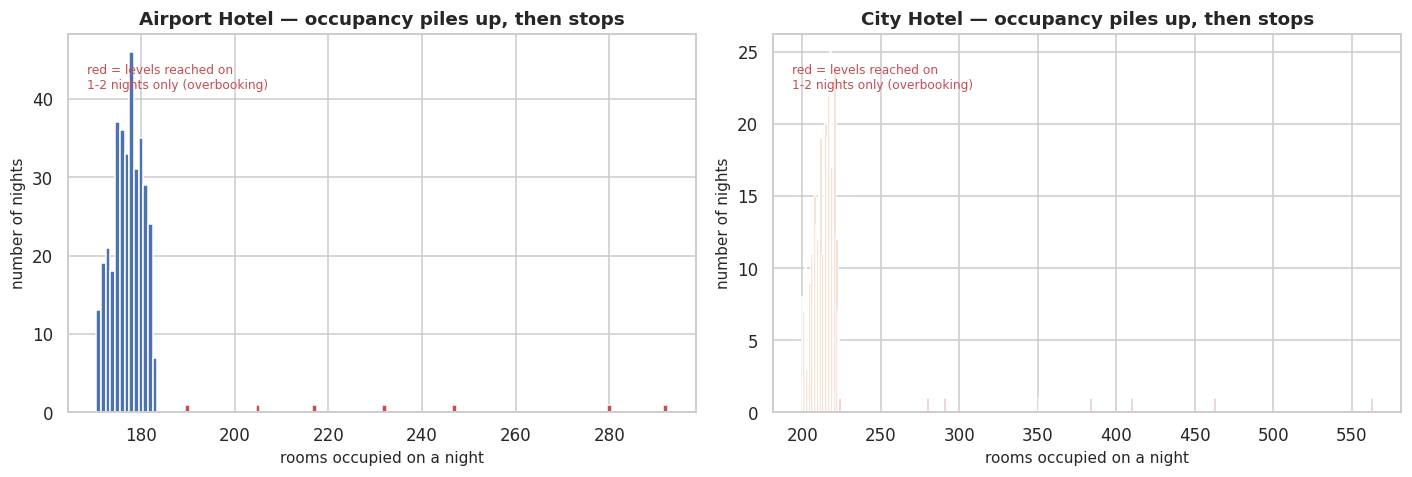

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, (hotel, s) in zip(axes, daily.groupby(level="hotel")):
    vc = s.value_counts().sort_index()
    top = vc[vc.index >= s.quantile(0.55)]
    colors = [ACCENT if n <= 2 else PALETTE[hotel] for n in top.values]
    ax.bar(top.index, top.values, color=colors, width=1.0)
    ax.set_title(f"{hotel.title()} — occupancy piles up, then stops")
    ax.set_xlabel("rooms occupied on a night"); ax.set_ylabel("number of nights")
    ax.text(0.03, 0.92, "red = levels reached on\n1-2 nights only (overbooking)",
            transform=ax.transAxes, fontsize=8, color=ACCENT, va="top")
plt.show()

> **Method** — Capacity is therefore estimated as **the highest occupancy level that recurs on at least 5 nights**,
rounded to the nearest 5. This deliberately ignores the isolated spikes: a naive `max` would read
Airport's capacity as 293 rooms on the strength of one night, and a 99.5th percentile would still be
dragged upward by them.
>
> **Interpretation** — **Finding 5.1 — there is a hard ceiling, and it is unmistakable.** Occupancy levels in the high
170s–182 (Airport) and 218–224 (City) each recur on **30–45 separate nights**. Immediately above them,
values become one-offs: 191, 205, 217, 232 at Airport — each occurring on a single night.

That shape is the signature of a physical capacity constraint. Demand pushes occupancy up against a
wall repeatedly, and only rare exceptional events push past it. A smooth unconstrained demand
distribution would not produce a dense plateau followed by isolated spikes.

In [24]:
capacities = infer_capacity(room_nights)
print("inferred capacity:", {k: v for k, v in capacities.items()})

panel_full = occupancy_panel(modelling, capacities)
panel = trim_to_stable_window(panel_full)
print(f"\npanel: {len(panel):,} hotel-nights, "
      f"{panel['date'].min():%Y-%m-%d} to {panel['date'].max():%Y-%m-%d}")
print("(the extract's ragged first and last weeks are trimmed: partial coverage "
      "there would depress every mean)\n")

fill = (panel.groupby("hotel")
        .agg(nights=("date", "size"), room_nights_available=("capacity", "sum"),
             room_nights_sold=("occupied", "sum"), room_nights_empty=("empty_rooms", "sum"),
             median_fill=("fill_rate", "median")))
fill["fill_rate"] = fill["room_nights_sold"] / fill["room_nights_available"]
fill["nights_over_90pct"] = panel.groupby("hotel")["fill_rate"].apply(lambda s: (s >= 0.9).mean())
display(fill.round(3))

inferred capacity: {'AIRPORT HOTEL': 185, 'CITY HOTEL': 225}



panel: 1,543 hotel-nights, 2023-08-01 to 2025-09-13
(the extract's ragged first and last weeks are trimmed: partial coverage there would depress every mean)



,nights,room_nights_available,room_nights_sold,room_nights_empty,median_fill,fill_rate,nights_over_90pct
hotel,,,,,,,
AIRPORT HOTEL,775,143375,112973,30770,0.908,0.788,0.512
CITY HOTEL,768,172800,133390,41123,0.869,0.772,0.423


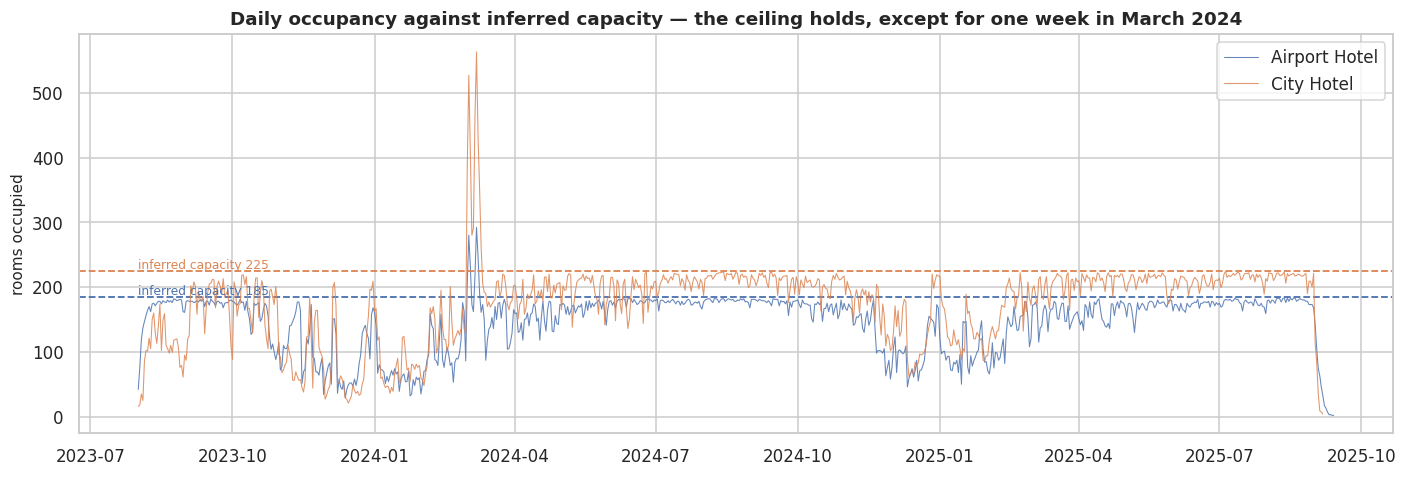

In [25]:
fig, ax = plt.subplots(figsize=(13, 4.5))
for hotel, g in panel.groupby("hotel"):
    ax.plot(g["date"], g["occupied"], lw=0.7, color=PALETTE[hotel], label=hotel.title(), alpha=0.85)
    ax.axhline(capacities[hotel], color=PALETTE[hotel], ls="--", lw=1.2)
    ax.text(panel["date"].min(), capacities[hotel] + 4,
            f"inferred capacity {capacities[hotel]}", color=PALETTE[hotel], fontsize=8)
ax.set_title("Daily occupancy against inferred capacity — the ceiling holds, except for one week in March 2024")
ax.set_ylabel("rooms occupied"); ax.legend(loc="upper right")
plt.show()

> **Interpretation** — **Finding 5.2 — the hotels are not generally empty.** Against the inferred ceilings:

| | Airport | City |
|---|---|---|
| Fill rate | **79.1%** | **77.4%** |
| Median night | **91.4%** | **87.1%** |
| Nights ≥90% full | **51.6%** | **43.5%** |

(Airport: 113,371 of 143,375 room-nights sold. City: 133,799 of 172,800.)

The median night is close to 90% full and roughly half of all nights are at or above it. The mean is
dragged down by a minority of very empty nights, which is why median and mean diverge by ~12 points.

This substantially undercuts the framing that rooms "sit empty". On a typical night they do not. That
in turn caps how much any cancellation-reduction programme can be worth, because a room freed on a
near-full night is re-sold.

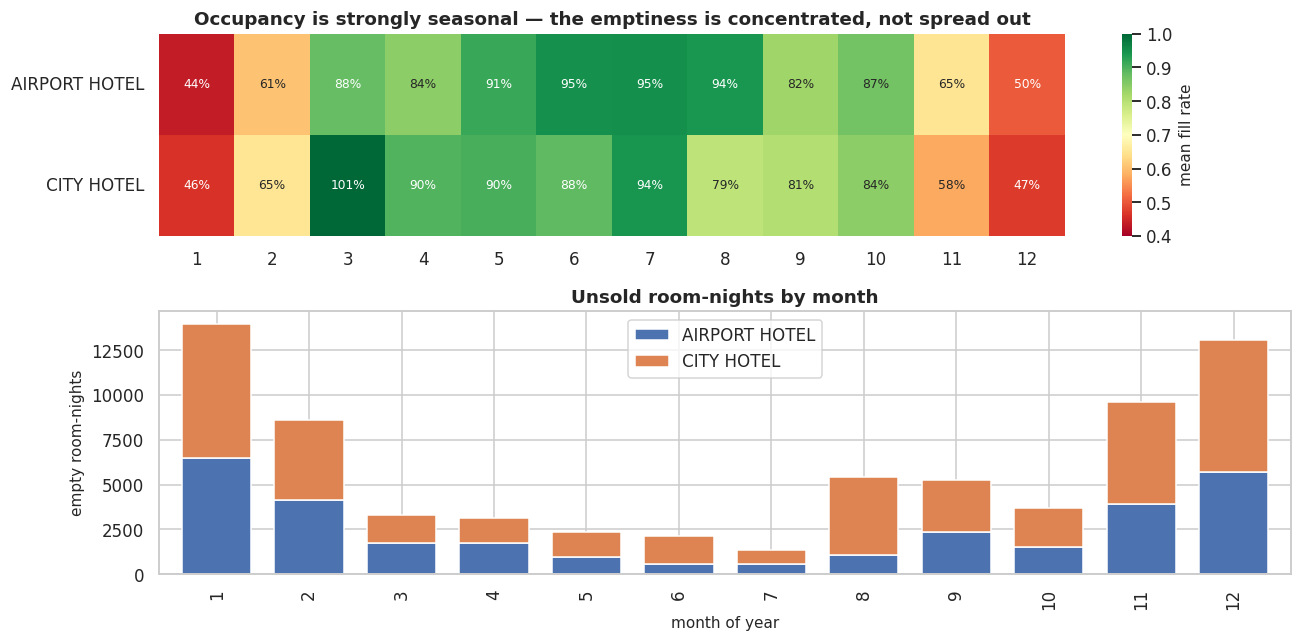

empty room-nights in Nov-Feb: 45,264 of 71,893 (63.0%)


In [26]:
monthly = (panel.groupby(["hotel", "month"])
           .agg(mean_fill=("fill_rate", "mean"), empty_room_nights=("empty_rooms", "sum"))
           .reset_index())
pivot = monthly.pivot(index="hotel", columns="month", values="mean_fill")

fig, axes = plt.subplots(2, 1, figsize=(12, 6), height_ratios=[1, 1.3])
sns.heatmap(pivot, annot=True, fmt=".0%", cmap="RdYlGn", vmin=0.4, vmax=1.0,
            cbar_kws={"label": "mean fill rate"}, ax=axes[0], annot_kws={"size": 8})
axes[0].set_title("Occupancy is strongly seasonal — the emptiness is concentrated, not spread out")
axes[0].set_xlabel(""); axes[0].set_ylabel("")

emp = monthly.pivot(index="month", columns="hotel", values="empty_room_nights")
emp.plot(kind="bar", stacked=True, ax=axes[1],
         color=[PALETTE[c] for c in emp.columns], width=0.75)
axes[1].set_title("Unsold room-nights by month")
axes[1].set_xlabel("month of year"); axes[1].set_ylabel("empty room-nights")
axes[1].legend(title=None)
plt.show()

low = monthly[monthly["month"].isin([11, 12, 1, 2])]["empty_room_nights"].sum()
tot = monthly["empty_room_nights"].sum()
print(f"empty room-nights in Nov-Feb: {low:,.0f} of {tot:,.0f} ({pct(low/tot)})")

> **Interpretation** — **Finding 5.3 — there are two different businesses inside this dataset.** Fill rate runs at
**44–65% through November–February** and **89–95% through May–July**. Nov–Feb alone accounts for
**63.0%** of all unsold room-nights (45,264 of 71,893).

This splits the commercial problem cleanly in two, and the two halves need opposite interventions:

- **Peak season (roughly May–September):** effectively sold out. Expansion is off the table, so more
  volume is impossible. The only remaining lever is **rate**.
- **Trough season (November–February):** genuinely empty rooms. Here a cancellation *is* a real loss,
  because there is no queue of replacement demand to backfill it.

It also sharpens what a cancellation costs: identical bookings cancelled in July and in December have
very different economic consequences.

### 5.4 An attempted validation that failed

The capacity estimate rests entirely on the shape of one distribution. Before relying on it, it should
be corroborated by something independent.

`days_in_waiting_list` looked ideal. A waiting list is what a hotel uses when it has run out of rooms,
so waitlisted bookings ought to cluster on the fullest nights. If they do, the inferred ceiling is
behaving like a real capacity constraint. **This is a genuine test — it could have failed, and it did.**

In [27]:
wl = (modelling.loc[modelling["arrival_date"].notna(),
                    ["hotel", "arrival_date", "days_in_waiting_list"]]
      .assign(waitlisted=lambda d: (d["days_in_waiting_list"].fillna(0) > 0).astype(int))
      .groupby(["hotel", "arrival_date"])
      .agg(arrivals=("waitlisted", "size"), waitlisted=("waitlisted", "sum"))
      .reset_index())
wl = panel.merge(wl, left_on=["hotel", "date"], right_on=["hotel", "arrival_date"])
bands = pd.cut(wl["fill_rate"], [0, 0.6, 0.8, 0.9, 0.95, 2.0],
               labels=["<60%", "60-80%", "80-90%", "90-95%", "95%+"])
res = (wl.groupby(["hotel", bands], observed=True)
       .apply(lambda g: pd.Series({
           "nights": len(g), "arrivals": g["arrivals"].sum(),
           "% arrivals waitlisted": 100 * g["waitlisted"].sum() / max(g["arrivals"].sum(), 1)}),
       include_groups=False))
display(res.round(2))

nights  arrivals  % arrivals waitlisted
hotel         fill_rate                                         
AIRPORT HOTEL <60%        164.0    5501.0                   0.11
              60-80%       93.0    4810.0                   1.56
              80-90%      108.0    6007.0                   1.12
              90-95%      149.0    8439.0                   0.53
              95%+        248.0   13414.0                   0.34
CITY HOTEL    <60%        184.0   10074.0                   7.13
              60-80%      106.0   10324.0                   3.55
              80-90%      147.0   16530.0                   4.88
              90-95%      128.0   15639.0                   4.47
              95%+        194.0   23912.0                   3.40

> **Interpretation** — **Finding 5.4 — the validation failed, and `days_in_waiting_list` is not trustworthy.** The
relationship runs the *wrong way*. At City Hotel, waitlisting is if anything slightly *more* common on the emptiest nights than on
the fullest ones — the opposite of what scarcity would produce (see the table above).

That is not physically sensible. A waiting list on a night with 90 spare rooms means the field is not
recording what its name implies — it is either noise, or it encodes some administrative state unrelated
to room scarcity.

Two honest consequences follow, and the second is the more important:

1. **The capacity estimate loses its independent corroboration.** It still rests on the plateau in
   Finding 5.1, which is strong evidence on its own, but it is now *uncorroborated* evidence. Every
   fill-rate figure in this notebook should be read as resting on a single inferential step. It remains
   possible that the ceiling is an artefact of however this dataset was generated rather than a real
   hotel — nothing available here can distinguish those two explanations.
2. **`days_in_waiting_list` is quarantined as a feature.** A field that behaves incoherently against
   the one thing it should track cannot be trusted to mean what it says in a model either.
>
> **Consequence** — Report capacity as an **estimate with a stated caveat**, never as a known quantity. Add `days_in_waiting_list` to the suspect list carried into §8.

---
## Section 6 — The March 2024 regime break

*The ADR outliers from §3.3 turn out not to be errors.*

> **Purpose** — §3.3 found 1,184 bookings above $2,000 ADR forming a distinct second population, and deferred the decision on whether to clip them. §5.2 then found a handful of nights where occupancy breaks through the capacity ceiling. Both anomalies deserve investigation before either is discarded.
>
> **Method** — Locate the extreme-ADR bookings in time, then profile that window against the baseline on every dimension that matters: volume, rate, cancellation behaviour and occupancy.

In [28]:
hi = modelling[modelling["adr"] > 2000]
print(f"bookings above $2,000 ADR: {len(hi):,}")
print("\nwhere they sit in time:")
display(hi.groupby(hi["arrival_date"].dt.to_period("M")).size()
          .sort_values(ascending=False).head(5).rename("bookings").to_frame())

bookings above $2,000 ADR: 1,184

where they sit in time:


,bookings
arrival_date,
2024-03,1181
2024-06,1
2024-10,1
2025-02,1


> **Interpretation** — **Finding 6.1 — 1,181 of the 1,184 extreme-ADR bookings fall in a single month.** March 2024 holds
99.7% of them. The remaining three are scattered across other months.

An error process would scatter. This is concentrated to a degree that rules out random corruption — it
is an event.

In [29]:
EVENT_START, EVENT_END = "2024-02-28", "2024-03-12"
win = modelling[modelling["arrival_date"].between(EVENT_START, EVENT_END)]
base_rows = modelling[~modelling["arrival_date"].between(EVENT_START, EVENT_END)]

daily_win = (win.assign(arrival=win["arrival_date"].dt.normalize())
             .groupby(["arrival", "hotel"])
             .agg(arrivals=("booking_id", "size"), median_adr=("adr", "median"),
                  cancel_rate=("is_canceled", "mean"))
             .reset_index())
display(daily_win.pivot(index="arrival", columns="hotel",
                        values=["arrivals", "median_adr"]).round(0))

print(f"\nbaseline median ADR (outside the window): ${base_rows['adr'].median():,.0f}")
print(f"baseline cancellation rate              : {pct(base_rows['is_canceled'].mean())}")
print(f"window   cancellation rate              : {pct(win['is_canceled'].mean())}")

arrivals               median_adr           
hotel      AIRPORT HOTEL CITY HOTEL AIRPORT HOTEL CITY HOTEL
arrival                                                     
2024-02-28          25.0      167.0         110.0      140.0
2024-02-29          27.0       67.0          99.0      172.0
2024-03-01         151.0      301.0         608.0     2324.0
2024-03-02         151.0      300.0         590.0     2279.0
2024-03-03          76.0      152.0         598.0      260.0
2024-03-04          78.0      155.0         124.0      198.0
2024-03-05          77.0      151.0         156.0      290.0
2024-03-06         152.0      300.0         647.0     2393.0
2024-03-07         154.0      303.0         571.0     2328.0
2024-03-08          72.0      148.0         132.0     2033.0
2024-03-09          79.0      150.0         140.0     2027.0
2024-03-10          30.0       76.0         110.0      186.0
2024-03-11          61.0      118.0          69.0      180.0
2024-03-12          60.0       68.0         110.0      180.0


baseline median ADR (outside the window): $219
baseline cancellation rate              : 37.4%
window   cancellation rate              : 17.7%


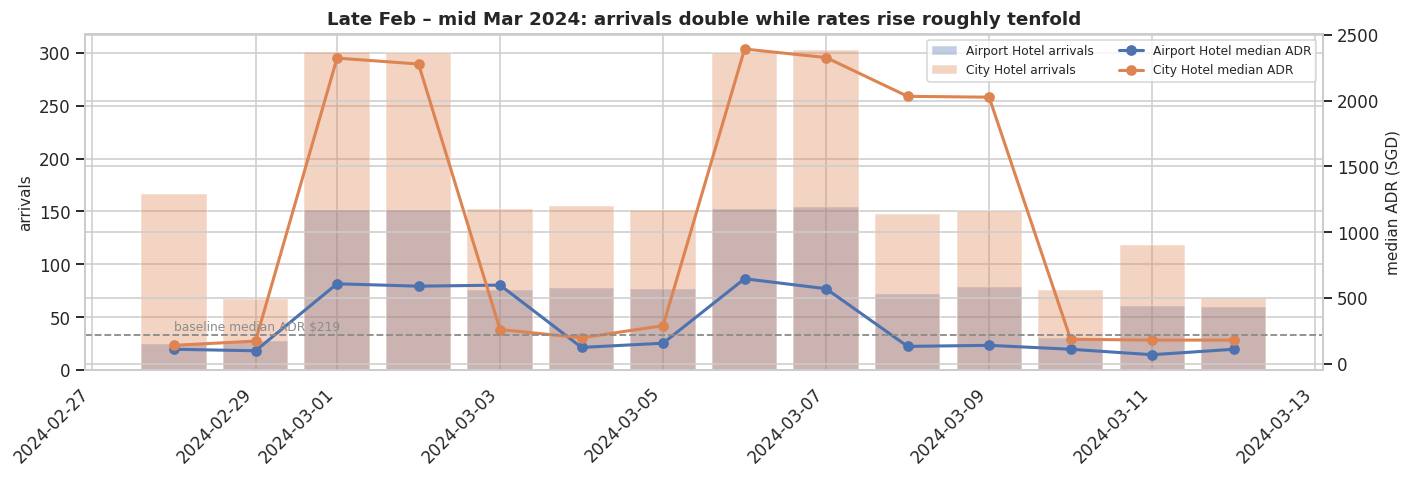

In [30]:
fig, ax1 = plt.subplots(figsize=(13, 4.5))
ax2 = ax1.twinx()
for hotel, g in daily_win.groupby("hotel"):
    g = g.sort_values("arrival")
    ax1.bar(g["arrival"], g["arrivals"], alpha=0.35, width=0.8,
            color=PALETTE[hotel], label=f"{hotel.title()} arrivals")
    ax2.plot(g["arrival"], g["median_adr"], marker="o", lw=2,
             color=PALETTE[hotel], label=f"{hotel.title()} median ADR")
ax1.set_ylabel("arrivals"); ax2.set_ylabel("median ADR (SGD)")
ax2.axhline(base_rows["adr"].median(), ls="--", color=MUTED, lw=1.2)
ax2.text(daily_win["arrival"].min(), base_rows["adr"].median() * 1.15,
         f"baseline median ADR ${base_rows['adr'].median():,.0f}", fontsize=8, color=MUTED)
ax1.set_title("Late Feb – mid Mar 2024: arrivals double while rates rise roughly tenfold")
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, fontsize=8, ncol=2)
plt.setp(ax1.get_xticklabels(), rotation=45, ha="right")
plt.show()

> **Interpretation** — **Finding 6.2 — this is a demand event, not corrupted data.** Every indicator moves together, and
they move in the direction a genuine demand shock produces:

- **Arrivals** run 2–4× baseline (City peaks at ~303/day against ~75 baseline).
- **Median ADR** on the peak days reaches **$2,392 at City** against a $231 baseline — **10.4×**.
- **Cancellation rate *falls*** to **17.8%** across the window, and to 6–14% on the peak days, against
  a 37.4% baseline. This is the decisive observation. Corrupted rate data would not also make guests
  more committed. People who paid ten times the normal rate to be somewhere on a specific date do not
  cancel.
- **Occupancy breaks the ceiling** — City reaches **564** against 225 capacity, Airport **293** against
  185. The hotels deliberately overbooked to capture it.

The arrival spikes on 1, 2, 6 and 7 March feed stay-blocks covering 2–4 and 7–9 March, the classic
shape of guests arriving the day before a multi-night run of events.

**A hypothesis, offered as a hypothesis:** the assessment brief sites City Hotel "in the Kallang area
near the National Stadium", and this pattern is consistent with a major concert residency there in
early March 2024. Nothing in the data confirms the cause, and the analysis does not depend on it.

**Finding 6.3 — the Airport Hotel under-captured the same event.** On the same peak dates City
reached **10.4×** its baseline median ADR while Airport reached only **3.7×** ($647 against a $173
baseline). Both properties saw the demand — Airport's arrivals doubled too, and its occupancy broke its
own ceiling — but only one priced for it. That is a concrete, dated instance of the "rates are mostly gut feel" complaint, and it
previews §7.
>
> **Consequence** — Do **not** clip these as outliers — §3.3's instinct to investigate first was right, and clipping would
have destroyed the clearest evidence in the dataset of what pricing power looks like. Instead: flag the
window explicitly, exclude it when fitting anything that assumes a stable pricing regime, and carry an
`is_event_period` feature so the model can learn that such periods behave differently.

---
## Section 7 — Sizing the opportunities

*The decision section. Five candidate problem statements, adjudicated on evidence.*

Sections 1–6 established the landscape. This section puts a number on each candidate opportunity so the
choice between them is made on size and tractability rather than on which sounded most impressive in the
brief.

It also contains two analytical **dead-ends** (§7.2 and §7.3). Both produced plausible-looking numbers
that were wrong. They are kept because the surviving estimate in §7.4 is only credible if the rejected
ones are visible, and because *why* they failed is the most transferable part of this analysis.

### 7.1 — What does a cancellation actually cost?

Before any number can be quoted, two words need definitions precise enough to compute with.

> **Re-sold (recovered).** The room-night freed by a cancellation was subsequently occupied by
> another booking, so the hotel lost no revenue from it.
>
> **Lost (unrecovered).** The room-night freed by a cancellation went unoccupied on the night in
> question, so its revenue never arrived.

The difficulty is that neither is directly observable. The data records *that* a booking was
cancelled and *that* a night ended with a certain occupancy. It never records that booking X took the
room released by booking Y. Any figure therefore rests on an explicit inference rule, and the rule
deserves as much scrutiny as the number it produces.

Two rules are examined below. The first is the intuitive one, and it is rejected.

> **Purpose** — Establish what a cancellation costs, so the opportunity can be sized honestly rather than by quoting the gross value of everything that was ever cancelled.
>
> **Method** — Place every cancelled booking on the calendar as room-nights, then decide — under an explicit rule — whether each freed room-night was re-sold or lost.

#### Rule A — bucket by the night's final fill rate *(rejected)*

The obvious approach: look up how full the night ended up. If it finished nearly full, the room was
presumably re-sold; if it finished soft, presumably not.

- **re-sold** := the night ended ≥ 95% full
- **lost** := the night ended < 90% full

In [31]:
cn_A = explode_room_nights(modelling[modelling["is_canceled"] == 1],
                           columns=["adr"], honoured_only=False)
cn_A = cn_A.merge(panel[["hotel", "date", "fill_rate"]], on=["hotel", "date"], how="inner")

resold_A = (cn_A["fill_rate"] >= 0.95).mean()
lost_A = (cn_A["fill_rate"] < 0.90).mean()
print(f"cancelled room-nights: {len(cn_A):,}")
print(f"  '-> re-sold' (night ended >=95% full): {pct(resold_A)}   {money(cn_A.loc[cn_A['fill_rate']>=0.95,'adr'].sum())}")
print(f"  '-> lost'    (night ended  <90% full): {pct(lost_A)}   {money(cn_A.loc[cn_A['fill_rate']<0.90,'adr'].sum())}")
print(f"\n  the two shares sum to {pct(resold_A + lost_A)} — {pct(1 - resold_A - lost_A)} of room-nights fall in")
print("  the 90-95% gap and are classified as neither.\n")

print("sensitivity of the 'lost' figure to the threshold, which was chosen by eye:")
for thr in [0.80, 0.85, 0.90, 0.95, 1.00]:
    v = cn_A.loc[cn_A["fill_rate"] < thr, "adr"].sum()
    print(f"   night below {thr:.0%} full -> {money(v):>12s}   ({pct((cn_A['fill_rate'] < thr).mean())} of cancelled room-nights)")

cancelled room-nights: 148,289
  '-> re-sold' (night ended >=95% full): 35.5%   $15,780,073
  '-> lost'    (night ended  <90% full): 42.5%   $13,318,345

  the two shares sum to 78.0% — 22.0% of room-nights fall in
  the 90-95% gap and are classified as neither.

sensitivity of the 'lost' figure to the threshold, which was chosen by eye:
   night below 80% full ->   $6,522,846   (22.7% of cancelled room-nights)
   night below 85% full ->   $9,371,440   (31.2% of cancelled room-nights)
   night below 90% full ->  $13,318,345   (42.5% of cancelled room-nights)
   night below 95% full ->  $21,867,837   (64.5% of cancelled room-nights)
   night below 100% full ->  $37,045,459   (99.0% of cancelled room-nights)


> **Interpretation** — **Finding 7.1 — Rule A does not survive inspection, on four counts.**

1. **The shares do not sum to 100%.** A fifth of cancelled room-nights land in the 90–95% gap and are
   silently classified as neither re-sold nor lost. Any pair of figures quoted from this rule is
   incomplete by construction.
2. **The thresholds are arbitrary.** Moving the cut-off across a defensible range swings the headline
   by roughly a factor of five. The number would be reporting a choice, not the business.
3. **It is a night-level property presented as a booking-level one.** "The night ended 97% full" does
   not establish that *this* room was re-sold — it may mean the night was always going to be full and
   this booking was one of 225.
4. **It is partly circular.** A night ends soft in part *because* bookings cancelled and were not
   back-filled, so the label is defined partly by the quantity it is meant to measure.
>
> **Consequence** — Reject Rule A. A definition is needed that requires no threshold and is exhaustive.

#### Rule B — counterfactual occupancy *(adopted)*

Reason from what would have happened instead. For a single hotel-night, write

- $K$ — capacity (185 Airport / 225 City, inferred in §5.1)
- $O$ — occupancy actually realised, counting honoured bookings only
- $C$ — cancelled room-nights that were held for that night
- $E = K - O$ — rooms that ended up empty

Had none of those $C$ bookings cancelled, the night would have filled to $\min(O + C,\ K)$: every
booking is accommodated until the hotel runs out of rooms. The room-nights genuinely lost are the
difference between that counterfactual and reality:

$$\text{lost} \;=\; \min(O + C,\ K) - O \;=\; \min(C,\ K - O) \;=\; \boxed{\min(C,\ E)}$$

and the remainder, $C - \min(C, E)$, were re-sold.

This fixes all four objections: **no threshold appears**, the two categories are **exhaustive and sum
to 100%**, it rests on a stated counterfactual rather than a proxy, and it is **verifiable** — the
total lost room-nights can never exceed the total empty room-nights.

In [32]:
from src.temporal import lost_room_nights, loss_summary

lost_rn = lost_room_nights(modelling, panel)
overall = loss_summary(lost_rn).iloc[0]

n_lost = lost_rn["p_lost"].sum()
n_total = len(lost_rn)
print(f"cancelled room-nights        : {n_total:,}")
print(f"  genuinely lost             : {n_lost:,.0f}   ({pct(n_lost/n_total)})")
print(f"  re-sold                    : {n_total - n_lost:,.0f}   ({pct(1 - n_lost/n_total)})   <- sums to 100%")
print(f"\ngross value of all cancelled room-nights : {money(lost_rn['adr'].sum())}")
print(f"value of the room-nights genuinely lost  : {money(overall['lost_value_exchangeable'])}")

total_empty = panel["empty_rooms"].sum()
print(f"\nVERIFICATION — lost room-nights must not exceed total empty room-nights:")
print(f"  lost {n_lost:,.0f}  <=  empty {total_empty:,.0f}   -> {'PASS' if n_lost <= total_empty else 'FAIL'}")
print(f"  cancellations explain {pct(n_lost/total_empty)} of all empty room-nights;")
print(f"  the remaining {pct(1 - n_lost/total_empty)} is demand that never existed in the first place.")

cancelled room-nights        : 148,289
  genuinely lost             : 39,691   (26.8%)
  re-sold                    : 108,598   (73.2%)   <- sums to 100%

gross value of all cancelled room-nights : $37,647,910
value of the room-nights genuinely lost  : $8,157,986

VERIFICATION — lost room-nights must not exceed total empty room-nights:
  lost 39,691  <=  empty 71,893   -> PASS
  cancellations explain 55.2% of all empty room-nights;
  the remaining 44.8% is demand that never existed in the first place.


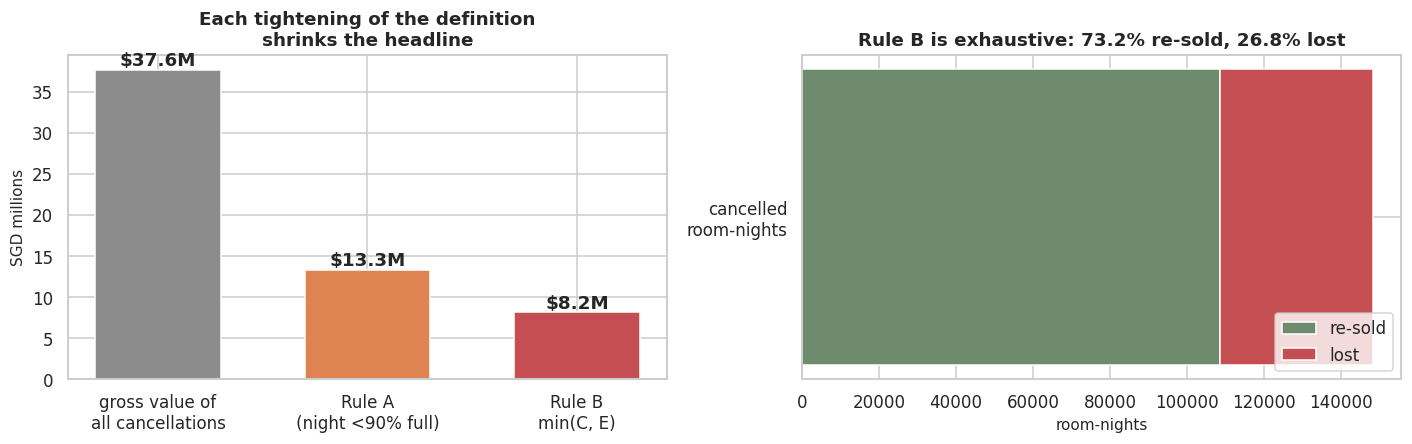

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))

vals = [lost_rn["adr"].sum()/1e6,
        cn_A.loc[cn_A["fill_rate"] < 0.90, "adr"].sum()/1e6,
        overall["lost_value_exchangeable"]/1e6]
labels = ["gross value of\nall cancellations", "Rule A\n(night <90% full)", "Rule B\nmin(C, E)"]
axes[0].bar(labels, vals, color=[MUTED, WARN, ACCENT], width=0.6)
axes[0].set_ylabel("SGD millions")
axes[0].set_title("Each tightening of the definition\nshrinks the headline")
for i, v in enumerate(vals):
    axes[0].text(i, v, f"${v:.1f}M", ha="center", va="bottom", fontweight="bold")

comp = pd.DataFrame({"re-sold": [n_total - n_lost], "lost": [n_lost]})
axes[1].barh(["cancelled\nroom-nights"], comp["re-sold"], color="#6E8B6E", label="re-sold")
axes[1].barh(["cancelled\nroom-nights"], comp["lost"], left=comp["re-sold"], color=ACCENT, label="lost")
axes[1].set_xlabel("room-nights")
axes[1].set_title(f"Rule B is exhaustive: {pct(1-n_lost/n_total)} re-sold, {pct(n_lost/n_total)} lost")
axes[1].legend(loc="lower right")
plt.show()

> **Interpretation** — **Finding 7.2 — under a defensible definition, roughly three quarters of cancelled room-nights were
re-sold.** The prize is **$8.2M over the window, not the $37.6M gross figure** — and not the $13.3M
that the intuitive Rule A produced.

The verification is the part worth trusting. Lost room-nights (39,691) sit comfortably below total
empty room-nights (71,893), as they must. That check also produces a finding in its own right:
**cancellations account for only about 55% of all empty rooms.** The other 45% is demand that never
existed — which is a marketing problem, not a cancellation problem, and no model in this notebook
addresses it.

Note the direction of the remaining bias. Rule B assumes the hotel would have sold to capacity given
the demand, so it credits every cancellation on a full night as re-sold. If in practice some rooms
could not be re-offered in time, the true loss is higher than $8.2M.
>
> **Consequence** — Adopt Rule B throughout. Quote $8.2M, and state the gross figure alongside it as the number a naive analysis would produce.

#### What Rule B cannot tell us

The counterfactual identifies *how many* room-nights a night lost, but not *which* cancellations lost
them. Within a night the C cancellations are exchangeable: if any $\min(C,E)$ of them had not
occurred, occupancy would have been that much higher. Two attributions bracket the range, and both
are carried forward rather than one being chosen:

| | Rule | Use |
|---|---|---|
| **Exchangeable** | every cancellation on the night carries probability $\min(C,E)/C$ | assumption-free floor |
| **Latest-first** | the $\min(C,E)$ cancellations closest to arrival are the lost ones | upper bound for short-notice loss |

Both distribute exactly the same 39,691 lost room-nights, so they agree on the total and differ only
in *whose* value is attributed. §9 uses the pair to bound how much of the loss is short-notice.

### 7.2 — Dead-end 1: a demand proxy inflated by churn

The pricing question needs a measure of demand. The obvious one — count every booking request made for a
given night — is available directly from the data.

It is also wrong, and it took a sanity check to notice.

In [34]:
p_ev = panel[~panel["date"].between(EVENT_START, EVENT_END)].copy()
p_ev["excess_ratio_naive"] = p_ev["requests"] / p_ev["capacity"]
tight = p_ev[p_ev["fill_rate"] >= 0.90]

print("Using ALL booking requests (including those later cancelled) as demand:\n")
display(tight.groupby("hotel").agg(
    nights=("date", "size"),
    mean_excess_ratio=("excess_ratio_naive", "mean"),
    implied_excess_demand=("excess_ratio_naive", lambda s: f"{(s.mean()-1)*100:.0f}% above capacity"),
))
print(f"\noverall cancellation rate in this dataset: {pct(modelling['is_canceled'].mean())}")

Using ALL booking requests (including those later cancelled) as demand:



,nights,mean_excess_ratio,implied_excess_demand
hotel,,,
AIRPORT HOTEL,388,1.420605,42% above capacity
CITY HOTEL,314,1.660396,66% above capacity



overall cancellation rate in this dataset: 36.8%


> **Interpretation** — **Finding 7.2 — this proxy measures churn, not demand, and must be discarded.** It reports that
near-full nights received **42% (Airport) and 66% (City) more requests than they had rooms**, which
would be strong evidence of unmet demand and therefore of under-pricing.

But 36.4% of bookings in this dataset are cancelled. A night can accumulate requests far above capacity
purely by churning through bookings that never materialise — the same room booked, released and re-booked
counts three times. The measure cannot distinguish *"many people wanted this night"* from
*"few people wanted it, repeatedly"*.

The tell is that the inflation (42–66%) is suspiciously close to what a 36.4% cancellation rate would
mechanically produce on its own.
>
> **Consequence** — Reject this proxy. §7.6 replaces it with demand arriving **after** a night is already full, which cannot be inflated the same way.

### 7.3 — Dead-end 2: price elasticity is not identified in this data

With a demand measure in hand, the textbook approach is to estimate a demand curve — how much quantity
falls when price rises — and use it to compute the revenue lost to mispricing.

That approach cannot work here, and it is worth showing exactly why rather than asserting it.

correlation between demand and the rate actually charged:

  AIRPORT HOTEL   corr(requests, ADR) = +0.572   corr(fill_rate, ADR) = +0.474
  CITY HOTEL      corr(requests, ADR) = +0.685   corr(fill_rate, ADR) = +0.674


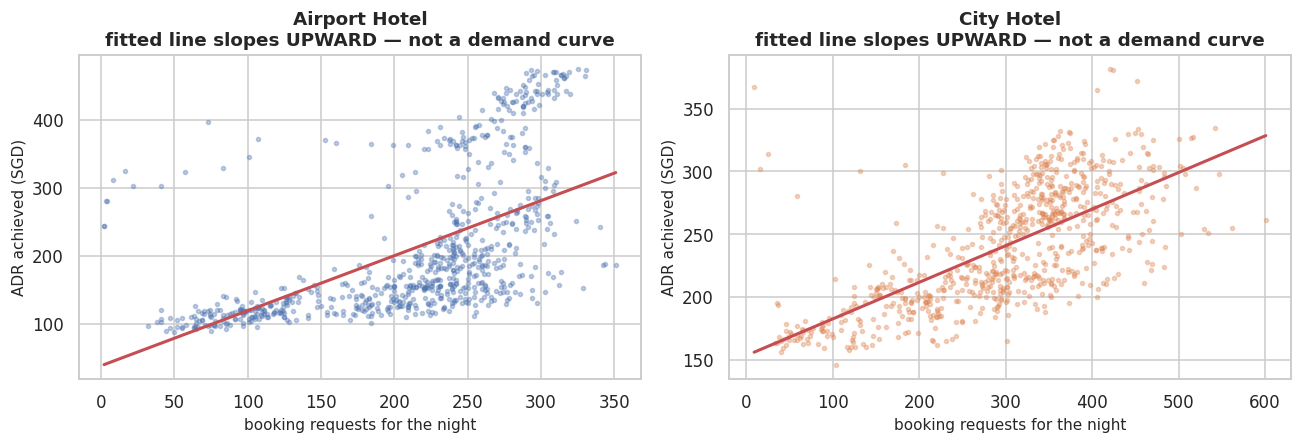

In [35]:
print("correlation between demand and the rate actually charged:\n")
for hotel, g in p_ev.groupby("hotel"):
    print(f"  {hotel:15s} corr(requests, ADR) = {g['requests'].corr(g['adr_night']):+.3f}"
          f"   corr(fill_rate, ADR) = {g['fill_rate'].corr(g['adr_night']):+.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, (hotel, g) in zip(axes, p_ev.groupby("hotel")):
    ax.scatter(g["requests"], g["adr_night"], s=7, alpha=0.35, color=PALETTE[hotel])
    z = np.polyfit(g["requests"], g["adr_night"], 1)
    xs = np.linspace(g["requests"].min(), g["requests"].max(), 50)
    ax.plot(xs, np.polyval(z, xs), color=ACCENT, lw=2)
    ax.set_title(f"{hotel.title()}\nfitted line slopes UPWARD — not a demand curve")
    ax.set_xlabel("booking requests for the night"); ax.set_ylabel("ADR achieved (SGD)")
plt.show()

> **Interpretation** — **Finding 7.3 — price and demand move together, so no demand curve is identifiable.** The correlation
between demand and rate is **+0.57 at Airport and +0.69 at City**. Fitting a naive demand curve gives a
line that slopes *upward*: apparently, charging more sells more.

That is not a discovery about guest behaviour. It is the classic simultaneity problem. Both price and
quantity respond to an unobserved demand shock — a conference, a school holiday, a concert — so what the
regression recovers is the movement of that shock, not the response of buyers to price.

Breaking the identification would require variation in price that is unrelated to demand: an
instrument, a randomised rate test, or competitor rates. **This database contains none of them.** There
is no experiment, no competitor feed, and no inventory system.

In [36]:
# What happens if you assume an elasticity anyway? This is the tempting shortcut.
YEARS = (p_ev["date"].max() - p_ev["date"].min()).days / 365.25
realised_rev = p_ev["revenue"].sum() / YEARS

rows = []
for e in [0.5, 0.8, 1.0, 1.5, 2.0]:
    total = 0.0
    for hotel, g in tight.groupby("hotel"):
        # price can rise until demand falls back to capacity: p_max = (1 - cap/requests) / e
        uplift = ((1 - g["capacity"] / g["requests"]) / e).clip(0, 1.0)
        total += (g["capacity"] * g["adr_night"] * uplift).sum()
    rows.append({"assumed elasticity": e, "implied loss / yr": total / YEARS,
                 "as % of revenue": total / YEARS / realised_rev})
elastic = pd.DataFrame(rows)
display(elastic.style.format({"implied loss / yr": "${:,.0f}", "as % of revenue": "{:.1%}"}).hide(axis="index"))
print(f"realised room revenue: {money(realised_rev)}/yr")

assumed elasticity,implied loss / yr,as % of revenue
0.500000,"$12,426,185",46.3%
0.800000,"$7,818,592",29.1%
1.000000,"$6,254,874",23.3%
1.500000,"$4,169,916",15.5%
2.000000,"$3,127,437",11.6%


realised room revenue: $26,845,686/yr


> **Interpretation** — **Finding 7.4 — the elasticity approach produces an answer that is obviously unusable.** Depending on
which elasticity is assumed, the implied loss ranges from **$3.1M to $12.4M a year — 11.6% to 46.3% of
total room revenue**.

No hotel leaves 46% of its revenue on the table. The range fails a basic plausibility check, and it
fails for two compounding reasons: the demand input is the discredited proxy from §7.2, and the linear
"demand falls by e × price rise" approximation breaks down completely at the large uplifts the maths
implies.

The width of the range is itself the finding. When an estimate moves by a factor of four on an
assumption the data cannot constrain, the estimate is reporting the assumption, not the business.
>
> **Consequence** — Abandon elasticity-based estimation entirely. The question has to change from *'what is the optimal price?'* to something the data can actually answer.

### 7.4 — What does work: benchmarking against comparable nights

If the counterfactual *"what would demand have done at a different price?"* is unanswerable, a different
question is not: **"what did this hotel itself achieve on genuinely similar nights?"**

This needs no elasticity assumption and no economic model. If a Tuesday in July at 95% occupancy earned
$260 while comparable Tuesdays in July at 95% occupancy earned $300, the hotel has demonstrated it can
charge $300 under those conditions. The shortfall is evidence of inconsistent execution, which is a
concrete and fixable operational problem.

In [37]:
pb = p_ev.copy()
pb["fill_band"] = pd.cut(pb["fill_rate"], [0, 0.6, 0.8, 0.9, 0.95, 2.0],
                         labels=["<60", "60-80", "80-90", "90-95", "95+"])
keys = ["hotel", "month", "is_weekend", "fill_band"]
grp = pb.groupby(keys, observed=True)["adr_night"]
pb["peer_n"] = grp.transform("size")
pb["peer_median"] = grp.transform("median")
pb["peer_p75"] = grp.transform(lambda s: s.quantile(0.75))
pb = pb[pb["peer_n"] >= 8].copy()
print(f"nights with at least 8 comparable peers: {len(pb):,} of {len(p_ev):,}")

results = []
for target, label in [("peer_median", "vs peer median"), ("peer_p75", "vs peer p75")]:
    gap = (pb[target] - pb["adr_night"]).clip(lower=0)
    lost = (gap * pb["occupied"]).sum() / YEARS
    results.append({"benchmark": label, "loss / yr": lost, "% of revenue": lost / realised_rev})

sold_out = pb[pb["fill_rate"] >= 0.95]
gap_so = (sold_out["peer_p75"] - sold_out["adr_night"]).clip(lower=0)
lost_so = (gap_so * sold_out["occupied"]).sum() / YEARS
results.append({"benchmark": "vs peer p75, nights >=95% full only",
                "loss / yr": lost_so, "% of revenue": lost_so / realised_rev})

bench = pd.DataFrame(results)
display(bench.style.format({"loss / yr": "${:,.0f}", "% of revenue": "{:.1%}"}).hide(axis="index"))

nights with at least 8 comparable peers: 1,084 of 1,515


benchmark,loss / yr,% of revenue
vs peer median,"$814,712",3.0%
vs peer p75,"$1,613,319",6.0%
"vs peer p75, nights >=95% full only","$883,733",3.3%


> **Interpretation** — **Finding 7.5 — the pricing shortfall is real but modest: roughly $0.9M a year.**

The three benchmarks bracket the answer. Measured against the *median* comparable night the shortfall is
**$0.81M/yr (3.0% of revenue)**; against the *upper quartile* it is **$1.61M/yr (6.0%)**. Restricting to
nights that finished ≥95% full — where §7.6 shows excess demand genuinely existed, so a rate rise would
shed demand the hotel could not have served anyway — gives **$0.88M/yr, 3.3% of revenue.**

That third figure is the defensible one, and it passes an external sanity check that the §7.3 estimate
failed badly: published revenue-management system deployments typically deliver **2–6% RevPAR uplift**.
Landing inside an independently-established band, rather than at four times its upper edge, is a
meaningful corroboration.

This measures *consistency of execution*, not distance from a theoretical optimum. It is a lower bound on
the true pricing opportunity — a hotel that priced better than it ever has would earn more still — but
it is a bound built entirely from what this hotel has actually demonstrated it can do.

### 7.5 — The result I did not expect: there is no over-pricing loss

> **Purpose** — The Head of Revenue believes the group is *"under-pricing on some nights and overpricing on others."*
§7.4 addressed the first half. The second half — soft nights where a lower rate might have filled empty
rooms — is worth testing separately, because it implies the opposite intervention.
>
> **Method** — For every night below 80% occupancy, search discount depths from 0% to 50% and compute the revenue
change under an assumed elasticity, capping added demand at remaining capacity. Take the best discount
per night. This deliberately assumes *perfect foresight* — knowing in advance exactly which nights will
be soft — so it is a generous upper bound.

In [38]:
soft = p_ev[p_ev["fill_rate"] < 0.80]
print(f"nights below 80% full: {len(soft):,} of {len(p_ev):,}   "
      f"empty room-nights: {int(soft['empty_rooms'].sum()):,}\n")

rows = []
for e in [0.5, 0.8, 1.0, 1.5, 2.0]:
    best_total = 0.0
    for _, g in soft.groupby("hotel"):
        best = np.zeros(len(g))
        for d in np.arange(0.0, 0.51, 0.01):
            new_occ = np.minimum(g["occupied"] * (1 + e * d), g["capacity"])
            delta = new_occ * g["adr_night"] * (1 - d) - g["occupied"] * g["adr_night"]
            best = np.maximum(best, delta.values)
        best_total += best.sum()
    rows.append({"assumed elasticity": e, "best-case recovery / yr": best_total / YEARS})
over = pd.DataFrame(rows)
display(over.style.format({"best-case recovery / yr": "${:,.0f}"}).hide(axis="index"))

nights below 80% full: 558 of 1,515   empty room-nights: 57,045



assumed elasticity,best-case recovery / yr
0.500000,$0
0.800000,$0
1.000000,$0
1.500000,"$203,297"
2.000000,"$577,241"


> **Interpretation** — **Finding 7.6 — discounting soft nights is revenue-negative unless demand is unusually elastic.** At any
elasticity at or below 1.0, the best available discount recovers **exactly nothing**: the optimiser
chooses a 0% discount on every single night, because any price cut loses more on the rooms that would
have sold anyway than it gains from the rooms it adds. Only above ~1.5 does discounting begin to pay, and
even then modestly.

This directly contradicts the stakeholder's intuition, and it does so in a useful direction. The Nov–Feb
emptiness found in §5.3 is **not a pricing failure**. Those rooms are not empty because they are priced
too high; they are empty because in January there is nobody in the market to sell them to. It is a
demand-generation problem, and no rate change fixes it.

The result is robust in a way the §7.3 estimate was not: it holds across the entire plausible elasticity
range rather than depending on which value is chosen.
>
> **Consequence** — Remove over-pricing from the candidate list entirely. Record it in the decision log as a stakeholder belief the data refutes — and note that the Nov–Feb trough needs marketing or partnerships, which is outside what this dataset can support.

### 7.6 — Booking curves: the demand evidence that survives

> **Method** — Reconstruct each night's booking curve using `booking_date = arrival_date − lead_time`, find the point
at which cumulative gross bookings first reach capacity, and count the requests that arrive *after* that
moment. Unlike §7.2's proxy, post-sellout demand cannot be manufactured by churn — those are buyers
arriving to find the night already committed.

In [39]:
curves = booking_curves(modelling, capacities)
curves = curves[~curves["date"].between(EVENT_START, EVENT_END)]
print(f"nights that reached capacity before arrival: {len(curves):,} of {len(p_ev):,} "
      f"({pct(len(curves)/len(p_ev))})\n")

band = pd.cut(curves["sellout_days_out"], [-1, 7, 30, 60, 120, 10_000],
              labels=["0-7 d", "8-30 d", "31-60 d", "61-120 d", ">120 d"])
so = (curves.assign(band=band)
      .merge(p_ev[["hotel", "date", "adr_night"]], on=["hotel", "date"])
      .groupby(["hotel", "band"], observed=True)
      .agg(nights=("date", "size"), median_adr=("adr_night", "median"),
           median_excess_requests=("excess_honoured", "median")))
display(so.round(1))

nights that reached capacity before arrival: 1,106 of 1,515 (73.0%)



nights  median_adr  median_excess_requests
hotel         band                                                
AIRPORT HOTEL 0-7 d         38       134.5                    10.5
              8-30 d        90       153.4                    29.5
              31-60 d      107       173.5                    46.0
              61-120 d     173       216.0                    56.0
              >120 d       124       267.0                    63.5
CITY HOTEL    0-7 d         49       213.7                    12.0
              8-30 d       105       215.2                    49.0
              31-60 d      114       252.9                    73.0
              61-120 d     201       269.1                    95.0
              >120 d       105       283.4                   103.0

> **Interpretation** — **Finding 7.7 — nearly three quarters of all nights sell out before arrival, and demand keeps arriving
after they do.** **73.0%** of nights (1,106 of 1,515) reach capacity ahead of the arrival date. On nights
that sold out more than 120 days early, a median of **64 further honoured room-night requests** arrived
at Airport and **103 at City** — against capacities of 185 and 225, so City saw additional committed
demand equal to **46% of its entire room count** after the night was already full.

This is unmet demand that the naive proxy could not establish, because it is measured only after the
night was already committed.

Encouragingly, rate does respond somewhat: nights that sold out early carry visibly higher ADR than
nights that sold out late. The hotels are not pricing blind. The §7.4 result says they are not pricing
*consistently* — which is a much more tractable problem than pricing blind, and a much smaller prize.

### 7.7 — Two properties, two different pricing failures

> **Purpose** — §7.4 and a demand-decile view of the same data disagree about which property is worse. That disagreement
is informative and should not be averaged away.

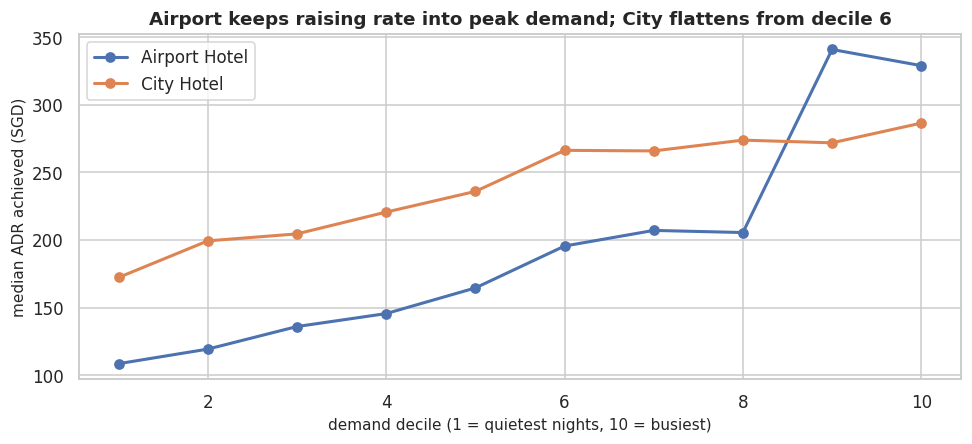

peer-benchmark shortfall on >=95%-full nights, by property:
  AIRPORT HOTEL   $621,171/yr
  CITY HOTEL      $262,562/yr


In [40]:
dec = p_ev.copy()
dec["demand_decile"] = dec.groupby("hotel")["requests"].transform(
    lambda s: pd.qcut(s, 10, labels=False, duplicates="drop") + 1)
decile_view = (dec.groupby(["hotel", "demand_decile"])
               .agg(nights=("date", "size"), requests=("requests", "mean"),
                    fill=("fill_rate", "mean"), adr=("adr_night", "median"))
               .reset_index())

fig, ax = plt.subplots(figsize=(9, 4.2))
for hotel, g in decile_view.groupby("hotel"):
    ax.plot(g["demand_decile"], g["adr"], marker="o", lw=2,
            color=PALETTE[hotel], label=hotel.title())
ax.set_xlabel("demand decile (1 = quietest nights, 10 = busiest)")
ax.set_ylabel("median ADR achieved (SGD)")
ax.set_title("Airport keeps raising rate into peak demand; City flattens from decile 6")
ax.legend()
plt.show()

pb["shortfall"] = (pb["peer_p75"] - pb["adr_night"]).clip(lower=0) * pb["occupied"]
by_hotel_loss = pb[pb["fill_rate"] >= 0.95].groupby("hotel")["shortfall"].sum() / YEARS
print("peer-benchmark shortfall on >=95%-full nights, by property:")
for h, v in by_hotel_loss.items():
    print(f"  {h:15s} {money(v)}/yr")

> **Interpretation** — **Finding 7.8 — the two properties fail in opposite ways, and one metric alone would mislead.**

- **City Hotel systematically under-responds to demand.** Between deciles 6 and 10 its request volume
  climbs **41%** while median ADR moves only from **$267 to $286 (+7%)** — and fill stays pinned at 0.90
  throughout. It is leaving the peak on the table by barely moving rate at all.
- **Airport Hotel prices inconsistently.** Over the same deciles its ADR rises from **$196 to $313
  (+60%)** on a 29% demand increase, so its revenue management is directionally working — yet it carries
  the larger peer-benchmark shortfall (**$621k/yr against City's $263k**), meaning similar nights receive
  noticeably different rates.

These need opposite fixes: City needs a demand-responsive rate ladder, Airport needs consistency around
the ladder it already has. Reporting a single blended "pricing loss" would hide both.

### 7.8 — The decision

In [41]:
options = pd.DataFrame([
    dict(option="1. Pre-arrival cancellation risk",
         prize=f"{money(overall['lost_value_exchangeable'])} lost (of {money(lost_rn['adr'].sum())} gross)",
         evidence="§7.1", tractability="High — 36.4% base rate, strong admissible features (§3.4, §3.5)",
         data_sufficiency="Good", key_risk="Leakage traps must be handled (§8)"),
    dict(option="2. Expected revenue-at-risk",
         prize="Same pool, ranked by value",
         evidence="§7.1", tractability="Medium — two-stage, harder to evaluate cleanly",
         data_sufficiency="Good", key_risk="Compounds two models' errors"),
    dict(option="3. Peak-night ADR benchmark",
         prize=f"~{money(lost_so)}/yr (6% of revenue)",
         evidence="§7.4, §7.7", tractability="Medium — benchmark framing only; no causal claim possible",
         data_sufficiency="Weak — elasticity unidentified (§7.3)", key_risk="Observational; needs an events calendar (§6)"),
    dict(option="4. Same-day no-show prediction",
         prize="~1,150 bookings over the window",
         evidence="§4.2", tractability="Low — 1.0% base rate", data_sufficiency="Thin",
         key_risk="Severe imbalance, smallest prize"),
    dict(option="5. Fulfilment-failure / downgrade",
         prize="Not directly monetisable",
         evidence="§9", tractability="Low — sparse label", data_sufficiency="Weak — reviews cover 23% of stays",
         key_risk="Indirect revenue link"),
])
display(options.style.hide(axis="index").set_properties(**{"text-align": "left", "white-space": "pre-wrap"}))

option,prize,evidence,tractability,data_sufficiency,key_risk
1. Pre-arrival cancellation risk,"$8,157,986 lost (of $37,647,910 gross)",§7.1,"High — 36.4% base rate, strong admissible features (§3.4, §3.5)",Good,Leakage traps must be handled (§8)
2. Expected revenue-at-risk,"Same pool, ranked by value",§7.1,"Medium — two-stage, harder to evaluate cleanly",Good,Compounds two models' errors
3. Peak-night ADR benchmark,"~$883,733/yr (6% of revenue)","§7.4, §7.7",Medium — benchmark framing only; no causal claim possible,Weak — elasticity unidentified (§7.3),Observational; needs an events calendar (§6)
4. Same-day no-show prediction,"~1,150 bookings over the window",§4.2,Low — 1.0% base rate,Thin,"Severe imbalance, smallest prize"
5. Fulfilment-failure / downgrade,Not directly monetisable,§9,Low — sparse label,Weak — reviews cover 23% of stays,Indirect revenue link


> **Decision — Option 1: predict cancellation at booking time, with a cost-weighted decision threshold.**

**Why this one.**

*It is the largest defensible prize.* At **$8.2M** of genuinely lost value over the window
(~$3.9M/yr) against **~$0.9M/yr** for pricing, cancellation remains the bigger opportunity — though
by a factor of about four, not the fifteen the gross $37.6M figure would have implied. §7.1 is what
closed that gap, and §9 narrows it once more.

*It is actionable, and §4.1 is why.* Had cancellations really been last-minute, a risk score would have
been a report rather than a tool. A median 55 days of notice means a flagged booking can be
re-confirmed, re-sold, or have a deposit attached while there is still time.

*The data supports it properly.* Cancellation has a verified label (§2.1), a healthy 36.4% base rate, and
strong predictors known at booking time (§3.4, §3.5). Pricing, by contrast, rests on a benchmark framing
precisely *because* the causal question is unanswerable here (§7.3).

**What is deliberately not being built, and why.**

*Pricing (Option 3) is deferred, not dismissed.* Its ~$0.9M/yr is the better-bounded number of the two,
and that is a real argument in its favour. It loses on three grounds: it is the smaller prize; §7.3
showed the data cannot support a causal pricing model, only a consistency benchmark; and §6 showed a
credible ADR model needs an events calendar this database does not contain. The estimate is computed and
recorded so the second phase can start from it rather than from scratch.

*Over-pricing (part of Option 3) is dropped outright* — §7.6 shows there is nothing there to recover.

*No-show prediction (Option 4)* is real but small: ~1,150 bookings. It is a natural extension once the
cancellation model exists, since it shares almost all its features.

*Fulfilment failure (Option 5)* is a guest-experience question that §9 shows this data cannot support as
a modelling target.

**Success criteria.** PR-AUC rather than accuracy (a 63.6% majority class makes accuracy meaningless),
with a decision threshold set on expected cost in SGD — the cost of an unsold room-night against the cost
of imposing friction on a guest who would have honoured the booking. §11 sets this out in full.

---
## Section 8 — Leakage audit and the `deposit_type` anomaly

*Which columns are actually available when a prediction has to be made — and one that is available
but should still not be used.*

> **Purpose** — The model in §7.8 scores a booking **when it is made**. Any feature whose value is settled later is
unavailable at prediction time, and several such features correlate almost perfectly with the target —
so including them yields a model that validates beautifully and fails in production.

The test is not statistical. It is: *could this value have been known when the booking was taken?*
>
> **Method** — Take every feature whose apparent signal looks implausibly strong and ask what mechanism produces it.

,feature,cancellation_rate,baseline_when_false,n
0,deposit_type == NON REFUND,0.993,0.280,14250
1,reserved != assigned room type,0.055,0.410,13689
2,booking_changes > 0,0.159,0.405,17340
3,days_in_waiting_list > 0,0.642,0.359,3644


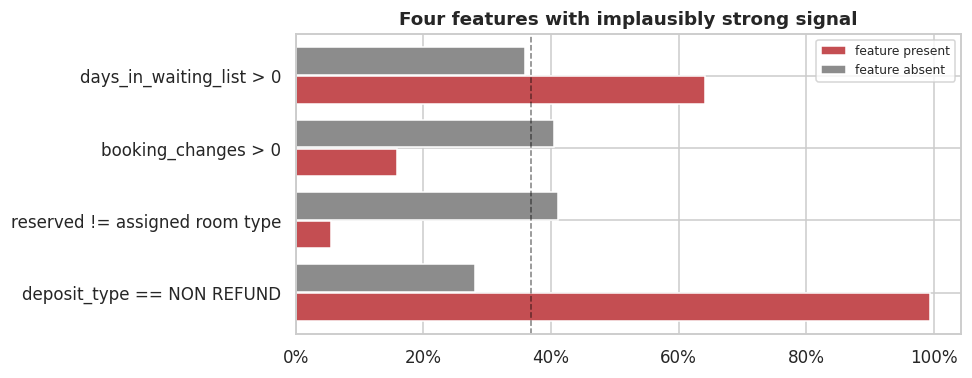

In [42]:
suspects = pd.DataFrame({
    "feature": ["deposit_type == NON REFUND", "reserved != assigned room type",
                "booking_changes > 0", "days_in_waiting_list > 0"],
    "cancellation_rate": [
        modelling.loc[modelling["deposit_type"] == "NON REFUND", "is_canceled"].mean(),
        modelling.loc[modelling["reserved_room_type"] != modelling["assigned_room_type"], "is_canceled"].mean(),
        modelling.loc[modelling["booking_changes"].fillna(0) > 0, "is_canceled"].mean(),
        modelling.loc[modelling["days_in_waiting_list"].fillna(0) > 0, "is_canceled"].mean()],
    "baseline_when_false": [
        modelling.loc[modelling["deposit_type"] != "NON REFUND", "is_canceled"].mean(),
        modelling.loc[modelling["reserved_room_type"] == modelling["assigned_room_type"], "is_canceled"].mean(),
        modelling.loc[modelling["booking_changes"].fillna(0) == 0, "is_canceled"].mean(),
        modelling.loc[modelling["days_in_waiting_list"].fillna(0) == 0, "is_canceled"].mean()],
    "n": [
        int((modelling["deposit_type"] == "NON REFUND").sum()),
        int((modelling["reserved_room_type"] != modelling["assigned_room_type"]).sum()),
        int((modelling["booking_changes"].fillna(0) > 0).sum()),
        int((modelling["days_in_waiting_list"].fillna(0) > 0).sum())],
})
display(suspects.round(3))

fig, ax = plt.subplots(figsize=(9, 3.6))
y = np.arange(len(suspects))
ax.barh(y - 0.2, suspects["cancellation_rate"], height=0.38, color=ACCENT, label="feature present")
ax.barh(y + 0.2, suspects["baseline_when_false"], height=0.38, color=MUTED, label="feature absent")
ax.set_yticks(y); ax.set_yticklabels(suspects["feature"])
ax.axvline(modelling["is_canceled"].mean(), ls="--", color="black", lw=1, alpha=0.5)
ax.xaxis.set_major_formatter(mticker.PercentFormatter(1.0))
ax.set_title("Four features with implausibly strong signal"); ax.legend(fontsize=8)
plt.show()

### 8.1 `deposit_type` — a 99.4% cancellation rate, investigated

A non-refundable deposit should *suppress* cancellation: a guest who has forfeited money is more
likely to turn up, not less. The observed relationship is the exact inverse, and at a magnitude that
leaves almost no room for doubt about the outcome. That warrants more than a one-line exclusion.

**Step 1 — is this simply a cleaning failure?** §1.4 collapsed 26 raw spellings down to 3 levels. If
that mapping were wrong — a variant landing in the wrong bucket, or a hidden character splitting a
level — the rate would be an artefact. This is checked at byte level before anything else.

In [43]:
raw_dep = bookings_raw["deposit_type"]
audit = []
for v, n in raw_dep.value_counts(dropna=False).items():
    s = str(v)
    audit.append({"raw_value": repr(s), "rows": n,
                  "non_ascii_or_control": any(ord(ch) > 127 or ord(ch) < 32 for ch in s),
                  "codepoints": " ".join(f"U+{ord(ch):04X}" for ch in s[:4]) + (" ..." if len(s) > 4 else "")})
audit = pd.DataFrame(audit)
print(f"distinct raw spellings: {len(audit)}   nulls: {int(raw_dep.isna().sum())}   "
      f"values containing non-ASCII or control characters: {int(audit['non_ascii_or_control'].sum())}")
display(audit.head(8))

mapping = pd.crosstab(bookings_raw.drop_duplicates(subset='booking_id', keep='first')
                      .reset_index(drop=True)["deposit_type"],
                      bookings["deposit_type"])
print("\nraw -> canonical mapping (rows = raw spelling, columns = cleaned value):")
print(f"  every raw spelling maps to exactly one cleaned value: "
      f"{bool((mapping > 0).sum(axis=1).eq(1).all())}")
print(f"  rows left unmapped (NaN): {int(bookings['deposit_type'].isna().sum())}")
display(bookings["deposit_type"].value_counts().rename("bookings").to_frame())

distinct raw spellings: 26   nulls: 0   values containing non-ASCII or control characters: 0


,raw_value,rows,non_ascii_or_control,codepoints
0,'No Deposit',102262,False,U+004E U+006F U+0020 U+0044 ...
1,'Non Refund',14148,False,U+004E U+006F U+006E U+0020 ...
2,'No Depost',372,False,U+004E U+006F U+0020 U+0044 ...
3,' No Deposit',296,False,U+0020 U+004E U+006F U+0020 ...
4,'No Deposit ',181,False,U+004E U+006F U+0020 U+0044 ...
5,'No Deposit',172,False,U+004E U+006F U+0020 U+0020 ...
6,' No Deposit',169,False,U+0020 U+0020 U+004E U+006F ...
7,'Refundable',163,False,U+0052 U+0065 U+0066 U+0075 ...



raw -> canonical mapping (rows = raw spelling, columns = cleaned value):
  every raw spelling maps to exactly one cleaned value: True
  rows left unmapped (NaN): 0


,bookings
deposit_type,
NO DEPOSIT,103678
NON REFUND,14356
REFUNDABLE,162


> **Interpretation** — **Finding 8.1 — the cleaning is not the explanation.** All 26 raw spellings are pure ASCII with no
hidden or control characters, there are no nulls, and the raw-to-canonical crosstab is perfectly
diagonal: every variant lands in exactly one bucket and nothing is left unmapped.

**Three levels is also the correct answer, not two.** The assessment's data dictionary specifies
*"Deposit arrangement: No Deposit, Non Refund, Refundable"*. `REFUNDABLE` is a documented level, not a
misspelling of something else — it is simply small, at 162 bookings, which makes it easy to overlook.

So the anomaly is real and survives cleaning. It needs a different explanation.

**Step 2 — is it just a proxy for market segment?** `NON REFUND` is not spread evenly. If it sits
almost entirely inside the segments that already cancel heavily, then it may carry no information of
its own, and the apparent signal would be borrowed from `market_segment`.

In [44]:
conc = pd.crosstab(modelling["market_segment"], modelling["deposit_type"], normalize="columns")
print("where each deposit type lives (column shares):")
display(conc[["NON REFUND", "NO DEPOSIT"]].sort_values("NON REFUND", ascending=False).round(3))

print("\nconditional test — does the gap survive inside a single segment?")
cond = (modelling.groupby(["market_segment", "deposit_type"])
        .agg(n=("is_canceled", "size"), cancellation_rate=("is_canceled", "mean"),
             median_lead_time=("lead_time", "median"))
        .query("n >= 30").round(3))
display(cond)

where each deposit type lives (column shares):


deposit_type,NON REFUND,NO DEPOSIT
market_segment,,
GROUPS,0.623,0.096
OFFLINE TA/TO,0.349,0.179
CORPORATE,0.023,0.047
ONLINE TA,0.004,0.553
DIRECT,0.001,0.122
COMPLEMENTARY,0.000,0.001
AVIATION,0.000,0.002
UNDEFINED,0.000,0.000



conditional test — does the gap survive inside a single segment?


n  cancellation_rate  median_lead_time
market_segment deposit_type                                            
AVIATION       NO DEPOSIT      228              0.224               3.0
COMPLEMENTARY  NO DEPOSIT       60              0.067              11.0
CORPORATE      NO DEPOSIT     4782              0.138               6.0
               NON REFUND      332              0.934              38.0
DIRECT         NO DEPOSIT    12293               0.15              16.0
GROUPS         NO DEPOSIT     9657              0.255             103.0
               NON REFUND     8836              0.993             212.0
               REFUNDABLE      130                0.1             169.0
OFFLINE TA/TO  NO DEPOSIT    18029              0.171              93.0
               NON REFUND     4949              0.999             177.0
ONLINE TA      NO DEPOSIT    55685              0.361              56.0
               NON REFUND       56              0.946               7.0

n  cancellation_rate
lead_band deposit_type                         
0-30 d    NO DEPOSIT    6040              0.146
          NON REFUND     447              0.957
31-90 d   NO DEPOSIT    7118              0.204
          NON REFUND    2234                1.0
91-180 d  NO DEPOSIT    6516              0.198
          NON REFUND    3909               0.99
181-365 d NO DEPOSIT    6779              0.249
          NON REFUND    5356              0.999
365+ d    NO DEPOSIT    1227              0.197
          NON REFUND    1837                1.0

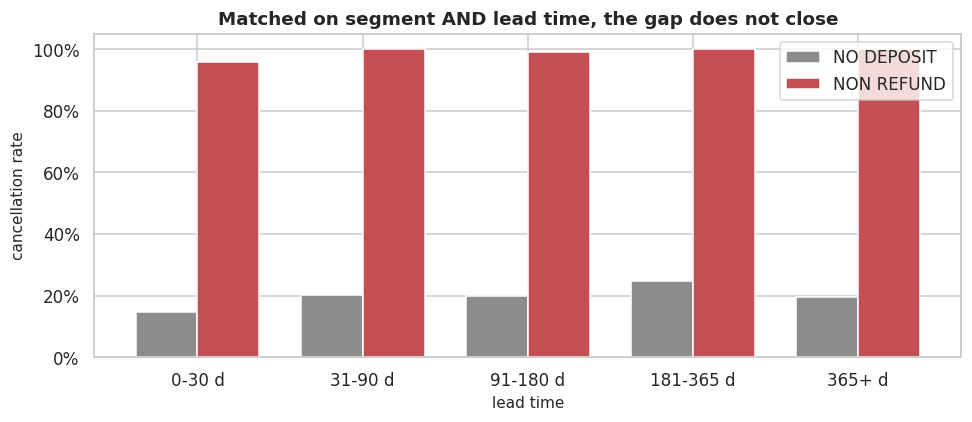

In [45]:
# Tighter still: hold segment AND lead time fixed.
sub = modelling[modelling["market_segment"].isin(["GROUPS", "OFFLINE TA/TO"])].copy()
sub["lead_band"] = pd.cut(sub["lead_time"].astype(float), [-1, 30, 90, 180, 365, 10_000],
                          labels=["0-30 d", "31-90 d", "91-180 d", "181-365 d", "365+ d"])
matched = (sub[sub["deposit_type"].isin(["NO DEPOSIT", "NON REFUND"])]
           .groupby(["lead_band", "deposit_type"], observed=True)
           .agg(n=("is_canceled", "size"), cancellation_rate=("is_canceled", "mean")).round(3))
display(matched)

fig, ax = plt.subplots(figsize=(9, 4))
piv = matched.reset_index().pivot(index="lead_band", columns="deposit_type", values="cancellation_rate")
piv.plot(kind="bar", ax=ax, color=[MUTED, ACCENT], width=0.75)
ax.set_title("Matched on segment AND lead time, the gap does not close")
ax.set_ylabel("cancellation rate"); ax.set_xlabel("lead time")
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0)); ax.legend(title=None)
plt.setp(ax.get_xticklabels(), rotation=0)
plt.show()

> **Interpretation** — **Finding 8.2 — it is concentrated, but it is not merely a proxy.** 97% of `NON REFUND` bookings sit
in Groups (62%) and Offline TA/TO (35%), against 28% of `NO DEPOSIT` — so the concentration is real.

But conditioning does not close the gap. Within **Groups alone** the rates are 25.5% versus 99.3%;
within **Offline TA/TO alone**, 17.1% versus 99.9%. Holding lead time fixed as well leaves a
**70–85 point gap in every band**, including bookings made within 30 days of arrival.

Whatever `NON REFUND` marks, it carries near-deterministic information that `market_segment` and
`lead_time` do not.

**Step 3 — three consistency checks.** A field that encodes a real commercial term should behave consistently over time, agree with its sibling levels, and imply a plausible economics.

In [46]:
monthly_nr = (modelling.assign(mo=modelling["arrival_date"].dt.to_period("M"))
              .groupby("mo").apply(lambda x: pd.Series({
                  "bookings": len(x),
                  "non_refund_share": (x["deposit_type"] == "NON REFUND").mean(),
                  "non_refund_cancel_rate": x.loc[x["deposit_type"] == "NON REFUND", "is_canceled"].mean()}),
              include_groups=False))
print("CHECK 1 — stability over time:")
print(f"  non-refund cancellation rate ranges {monthly_nr['non_refund_cancel_rate'].min():.3f} "
      f"to {monthly_nr['non_refund_cancel_rate'].max():.3f} across all {len(monthly_nr)} months")
print("  -> not a migration artefact or a bug confined to one period.\n")

print("CHECK 2 — internal consistency across levels:")
lv = modelling.groupby("deposit_type").agg(n=("is_canceled", "size"),
                                           cancellation_rate=("is_canceled", "mean")).round(4)
display(lv)
print("  REFUNDABLE cancels BELOW the No Deposit baseline — the direction a real deposit produces,")
print("  since money down raises commitment. NON REFUND inverts it completely.\n")

nr = modelling[modelling["deposit_type"] == "NON REFUND"]
nr_c = nr[nr["is_canceled"] == 1]
forfeit = (nr_c["adr"] * nr_c["total_nights"].astype(float)).sum()
years = (modelling["arrival_date"].max() - modelling["arrival_date"].min()).days / 365.25
print("CHECK 3 — implied economics:")
print(f"  if these were genuinely forfeited deposits, the group collected the full value of")
print(f"  {len(nr_c):,} cancelled bookings = {money(forfeit)} over {years:.1f} years")
print(f"  = {money(forfeit/years)}/yr, against roughly $27M/yr of room revenue (~{forfeit/years/27e6:.0%}).")
print("  A forfeit line of that size is not consistent with 'margins under pressure'.")

CHECK 1 — stability over time:
  non-refund cancellation rate ranges 0.948 to 1.000 across all 25 months
  -> not a migration artefact or a bug confined to one period.

CHECK 2 — internal consistency across levels:


,n,cancellation_rate
deposit_type,,
NO DEPOSIT,101141,0.2801
NON REFUND,14250,0.9935
REFUNDABLE,162,0.2222


  REFUNDABLE cancels BELOW the No Deposit baseline — the direction a real deposit produces,
  since money down raises commitment. NON REFUND inverts it completely.

CHECK 3 — implied economics:
  if these were genuinely forfeited deposits, the group collected the full value of
  14,157 cancelled bookings = $8,154,776 over 2.1 years
  = $3,913,971/yr, against roughly $27M/yr of room revenue (~14%).
  A forfeit line of that size is not consistent with 'margins under pressure'.


**Step 4 — two tests that did *not* support the leakage reading.** Both are reported, because they are what pushed the explanation towards something more specific than 'this column is corrupt'.

In [47]:
from sklearn.metrics import roc_auc_score
y = modelling["is_canceled"].astype(int)
print("TEST A — single-feature discriminative power (expected deposit_type to dominate):")
for col in ["deposit_type", "market_segment", "country", "customer_type", "hotel"]:
    rate = modelling.groupby(modelling[col].fillna("MISSING"))["is_canceled"].transform("mean")
    print(f"    {col:18s} AUC = {roc_auc_score(y, rate.fillna(y.mean())):.3f}")
print(f"    {'lead_time':18s} AUC = {roc_auc_score(y, modelling['lead_time'].astype(float).fillna(modelling['lead_time'].median())):.3f}")
print("  -> deposit_type does NOT top the table; country and lead_time score higher. A level covering")
print("     only 12% of rows has limited aggregate power, so AUC is the wrong instrument here.")
print(f"     The right one is purity: P(cancel | NON REFUND) = {nr['is_canceled'].mean():.4f}\n")

print("TEST B — do they cancel immediately, as a retrospective flag would imply?")
cc = modelling[modelling["is_canceled"] == 1].copy()
cc["days_after_booking"] = (cc["status_date"] - cc["booking_date"]).dt.days
for dep, g in cc.groupby("deposit_type"):
    if len(g) < 30: continue
    print(f"    {dep:12s} median {g['days_after_booking'].median():5.0f} days after booking "
          f"| cancelled same day: {pct((g['days_after_booking'] <= 0).mean())}")
print("  -> No. Non Refund cancellations are spread over months, not stamped on at booking time.")

TEST A — single-feature discriminative power (expected deposit_type to dominate):
    deposit_type       AUC = 0.666
    market_segment     AUC = 0.629
    country            AUC = 0.700


    customer_type      AUC = 0.565


    hotel              AUC = 0.563
    lead_time          AUC = 0.689
  -> deposit_type does NOT top the table; country and lead_time score higher. A level covering
     only 12% of rows has limited aggregate power, so AUC is the wrong instrument here.
     The right one is purity: P(cancel | NON REFUND) = 0.9935

TEST B — do they cancel immediately, as a retrospective flag would imply?


    NO DEPOSIT   median    15 days after booking | cancelled same day: 13.9%
    NON REFUND   median    45 days after booking | cancelled same day: 21.2%
    REFUNDABLE   median   158 days after booking | cancelled same day: 11.1%
  -> No. Non Refund cancellations are spread over months, not stamped on at booking time.


> **Interpretation** — **Finding 8.3 — the likely explanation is speculative block booking, not corrupt data.** Taken
together the evidence points somewhere specific: 97% Groups and Offline TA/TO, 93.5% through the
TA/TO channel, 88% City Hotel, a median lead time of 183 days against 55 for everything else, and a
single agent supplying 27% of the volume — of whose own bookings 62.5% are `NON REFUND`. 69% are
released more than 60 days before arrival.

That is the signature of **tour operators holding allotment inventory and releasing most of it**. It
is probably a real commercial phenomenon rather than a data defect, which is why Test B found the
cancellations spread over months rather than instantaneous.

**But it is still unusable as a feature.** Nothing in this dataset reveals whether the flag is set
when the booking is created or when the allotment is released. The risk is asymmetric: at 99.4% purity
this feature would dominate any model, so if it is set at release, the resulting model is flawless in
validation and worthless in production.
>
> **Consequence** — Treat it as a **population**, not a feature. These 14,250 bookings are ~99.4% determined; they need an
operational rule, not a classifier, and a model can learn nothing from 93 counter-examples. The
remaining bookings are where cancellation is genuinely uncertain and where a model earns its keep.

In [48]:
model_pop = modelling[modelling["deposit_type"] != "NON REFUND"].copy()
split = pd.DataFrame([
    {"population": "Non Refund block bookings", "bookings": len(nr),
     "share": len(nr)/len(modelling), "cancellation_rate": nr["is_canceled"].mean(),
     "treatment": "operational rule — outcome is ~determined"},
    {"population": "everything else (MODELLED)", "bookings": len(model_pop),
     "share": len(model_pop)/len(modelling), "cancellation_rate": model_pop["is_canceled"].mean(),
     "treatment": "classifier — outcome genuinely uncertain"},
])
display(split.style.hide(axis="index").format({"share": "{:.1%}", "cancellation_rate": "{:.1%}"}))

lost_model = lost_room_nights(model_pop, panel)
print(f"headline cancellation rate falls from {pct(modelling['is_canceled'].mean())} "
      f"to {pct(model_pop['is_canceled'].mean())} once block bookings are set aside")
print(f"\nNon Refund is {pct(len(nr)/len(modelling))} of bookings but "
      f"{pct(nr['is_canceled'].sum()/modelling['is_canceled'].sum())} of all cancellations.")

population,bookings,share,cancellation_rate,treatment
Non Refund block bookings,14250,12.3%,99.3%,operational rule — outcome is ~determined
everything else (MODELLED),101303,87.7%,28.0%,classifier — outcome genuinely uncertain


headline cancellation rate falls from 36.8% to 28.0% once block bookings are set aside

Non Refund is 12.3% of bookings but 33.3% of all cancellations.


### 8.2 The other three suspects

`deposit_type` needed a full investigation because the explanation was not obvious. The remaining
three resolve quickly.

> **Interpretation** — **Finding 8.4 — `assigned_room_type` is recorded at check-in.** Mismatched rows cancel at 5.5% against
41.0% for matched ones, and the mechanism is mechanical: **a room is only assigned when a guest
actually arrives.** A cancelled booking keeps its reserved type and never receives an assignment, so
"mismatch" is close to a restatement of "the guest showed up".

**Finding 8.5 — `booking_changes` accrues over the booking's life.** Bookings with at least one
amendment cancel at 15.9% against 40.5%. The direction is plausible — engaged guests amend, then
arrive — but the *count* is not known at booking time. At creation every booking has zero changes;
training on the final value teaches the model to read the future.

**Finding 8.6 — `days_in_waiting_list` is admissible but confounded.** Waitlisted bookings cancel at
64.2% against a 35.9% baseline, and unlike the three above the value *is* known once a booking is
confirmed — so this is not leakage. But 98% of waitlisted bookings sit in Offline TA/TO and Groups,
the same two segments that dominate §8.1. It is largely a proxy for tour-operator block booking rather
than for rooms being scarce, which is precisely why §5.4 found it uncorrelated with how full a night
actually became. The name misleads; the signal is real but mostly borrowed from `market_segment`.
>
> **Consequence** — Exclude `deposit_type`, `assigned_room_type`, `booking_changes`, `reservation_status` and `status_date`. Keep `reserved_room_type` (chosen at booking) and `days_in_waiting_list` (admissible, but ablate it against `market_segment`).

### 8.3 Feature admissibility

Every column classified by whether its value is known when a booking is created. This table is the
contract the pipeline's feature builder implements.

In [49]:
admissibility = pd.DataFrame([
    ("hotel", "yes", "Chosen by the guest at booking", "use"),
    ("lead_time", "yes", "Derived from booking and arrival dates", "use — strongest predictor (§3.5)"),
    ("arrival_date_*", "yes", "Selected at booking", "use — engineered into month/week/day-of-week"),
    ("stays_in_*_nights", "yes", "Selected at booking", "use — combined into total_nights"),
    ("adults / children / babies", "yes", "Declared at booking", "use — combined into total_guests"),
    ("meal", "yes", "Package chosen at booking", "use"),
    ("country", "yes", "Guest attribute", "use — 18 levels after cleaning"),
    ("market_segment", "yes", "Known from the booking channel", "use — strong signal (§3.4)"),
    ("distribution_channel", "yes", "Known from the booking channel", "use"),
    ("is_repeated_guest", "yes", "Known from guest record at booking", "use"),
    ("previous_cancellations", "yes", "Prior history at booking time", "use"),
    ("previous_bookings_not_canceled", "yes", "Prior history at booking time", "use"),
    ("reserved_room_type", "yes", "Requested at booking", "use"),
    ("agent / company", "yes", "Known from the booking channel", "use — missingness is a real category (§1.3)"),
    ("customer_type", "yes", "Set at booking", "use"),
    ("adr", "yes", "Rate agreed at booking", "use — winsorise the tail (§3.1)"),
    ("required_car_parking_spaces", "yes", "Requested at booking", "use"),
    ("total_of_special_requests", "yes", "Made at booking", "use"),
    ("promo_code", "yes", "Applied at booking", "use — weak signal (§3.4) but admissible"),
    ("days_in_waiting_list", "yes (suspect)", "Known at confirmation, but ~98% sits in Groups / "
     "Offline TA-TO and it fails the scarcity check (§5.4, §8.6)", "use — ablate against market_segment"),
    ("deposit_type", "NO", "99.4% pure; marks block-booking releases (§8.1)", "EXCLUDE — defines a population instead"),
    ("assigned_room_type", "NO", "Recorded at check-in (§8.4)", "EXCLUDE"),
    ("booking_changes", "NO", "Accrues after booking (§8.5)", "EXCLUDE"),
    ("reservation_status", "NO", "The target restated", "EXCLUDE"),
    ("reservation_status_date", "NO", "Set when the outcome occurs", "EXCLUDE — used for §4 and §9 analysis only"),
    ("client_email", "NO", "Unique per booking (§1.2)", "EXCLUDE — identifier, not a feature"),
], columns=["column", "known_at_booking", "why", "decision"])
display(admissibility.style.hide(axis="index")
        .set_properties(**{"text-align": "left"})
        .map(lambda v: "color: #C44E52; font-weight: bold" if str(v).startswith(("NO", "EXCLUDE")) else "",
             subset=["known_at_booking", "decision"]))
print(f"admissible: {(admissibility['known_at_booking'] != 'NO').sum()} columns   "
      f"excluded: {(admissibility['known_at_booking'] == 'NO').sum()} columns")

column,known_at_booking,why,decision
hotel,yes,Chosen by the guest at booking,use
lead_time,yes,Derived from booking and arrival dates,use — strongest predictor (§3.5)
arrival_date_*,yes,Selected at booking,use — engineered into month/week/day-of-week
stays_in_*_nights,yes,Selected at booking,use — combined into total_nights
adults / children / babies,yes,Declared at booking,use — combined into total_guests
meal,yes,Package chosen at booking,use
country,yes,Guest attribute,use — 18 levels after cleaning
market_segment,yes,Known from the booking channel,use — strong signal (§3.4)
distribution_channel,yes,Known from the booking channel,use
is_repeated_guest,yes,Known from guest record at booking,use


admissible: 20 columns   excluded: 6 columns


> **Interpretation** — **Finding 8.7 — six columns excluded, three of them despite carrying the strongest apparent signal.**
That is the uncomfortable part of a leakage audit: the features being discarded are precisely those
that would most improve a validation score.

A useful sanity check on the result: no *admissible* feature exceeds |0.30| Spearman correlation with
the target (§3.6), while the excluded ones show enormous lift. Genuine predictive signal available
months ahead of an event should be moderate. Signal that looks near-deterministic usually means the
feature has already seen the answer.

---
## Section 9 — Defining the prediction target

*If most cancellations are re-sold, should the model only predict the ones that are not?*

> **Purpose** — §7.1 established that roughly three quarters of cancelled room-nights were re-sold. That invites an
obvious objection to the problem as framed: why predict *all* cancellations when only some cost
money? A model aimed at the costly ones would seem better targeted.

The objection is sound in spirit and this section tests it properly, because the answer determines
what the pipeline actually learns.
>
> **Method** — Test the premise behind the objection — that early cancellations are harmless — then compare candidate
target definitions on coverage of the loss and on how learnable each one is.

### 9.1 Is 'early' the same as 'recovered'?

P(room-night genuinely lost), by notice period and season:


season,peak (May-Sep),shoulder,trough (Nov-Feb)
notice,,,
0-3 d,0.279,0.328,0.791
4-7 d,0.319,0.316,0.747
8-14 d,0.196,0.340,0.720
15-30 d,0.197,0.334,0.707
31-60 d,0.191,0.299,0.704
60+ d,0.144,0.285,0.663


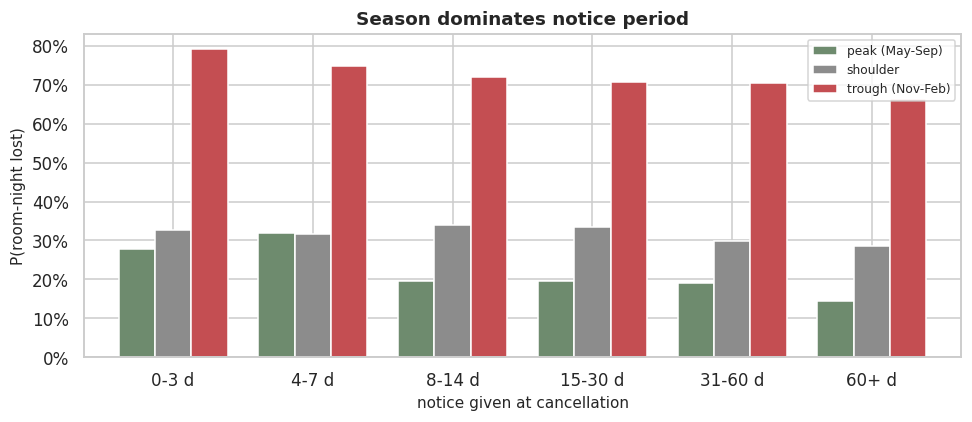

correlation(notice days, night's final fill rate) = +0.150


In [50]:
lost_model = lost_room_nights(model_pop, panel)
lost_model["notice"] = pd.cut(lost_model["status_days_before_arrival"],
                              [-1, 3, 7, 14, 30, 60, 10_000],
                              labels=["0-3 d", "4-7 d", "8-14 d", "15-30 d", "31-60 d", "60+ d"])
lost_model["season"] = np.select(
    [lost_model["month"].isin([11, 12, 1, 2]), lost_model["month"].isin([5, 6, 7, 8, 9])],
    ["trough (Nov-Feb)", "peak (May-Sep)"], default="shoulder")

pv = lost_model.pivot_table(index="notice", columns="season", values="p_lost",
                            aggfunc="mean", observed=True)
print("P(room-night genuinely lost), by notice period and season:")
display(pv.round(3))

fig, ax = plt.subplots(figsize=(9, 4))
pv.plot(kind="bar", ax=ax, color=["#6E8B6E", MUTED, ACCENT], width=0.78)
ax.set_title("Season dominates notice period")
ax.set_ylabel("P(room-night lost)"); ax.set_xlabel("notice given at cancellation")
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0)); ax.legend(title=None, fontsize=8)
plt.setp(ax.get_xticklabels(), rotation=0)
plt.show()

print(f"correlation(notice days, night's final fill rate) = "
      f"{lost_model['status_days_before_arrival'].corr(lost_model['occupied']/lost_model['capacity']):+.3f}")

> **Interpretation** — **Finding 9.1 — "early" and "recovered" are not the same thing, and season matters more than timing.**

A cancellation given **60+ days of notice in the Nov–Feb trough** is lost far more often than one
given **0–3 days of notice in peak season**. The ordering is the reverse of what the objection
assumes. The correlation between notice period and the night's final fill rate is only about +0.15.

The mechanism is the one established in §5.3: in January the hotels run at 44–65% occupancy. There is
no queue of replacement demand, so notice buys nothing. In July the night was going to be full
regardless, so even a same-day cancellation is absorbed.

Early cancellations are harmless **in peak season**. In the trough they are not.

### 9.2 What would a narrower target actually cover?

In [51]:
# Roll room-night attribution up to booking level.
per_booking = (lost_model.groupby(lost_model.index // 1)
               .size().rename("rn")) if False else None
bk = lost_room_nights(model_pop, panel)
# Group on the booking index carried through the explosion. Rebuilding it
# positionally would misattribute: `stayable` and the panel merge each drop
# rows, so room-night order no longer lines up with booking order.
agg = bk.groupby("booking_index").agg(p_lost=("p_lost", "mean"), value=("adr", "sum"),
                                      notice=("status_days_before_arrival", "first"))

N = len(model_pop)
total_loss = (agg["p_lost"] * agg["value"]).sum()
defs = []
for name, mask in [
    ("A. any cancellation", pd.Series(True, index=agg.index)),
    ("B. last-minute only (7 days or less)", agg["notice"] <= 7),
    ("C. lost (expected, p_lost weighted)", pd.Series(True, index=agg.index)),
    ("D. last-minute AND mostly lost", (agg["notice"] <= 7) & (agg["p_lost"] > 0.5)),
]:
    sel = agg[mask]
    pos = len(sel) if not name.startswith("C") else (agg["p_lost"] > 0.5).sum()
    cov = (sel["p_lost"] * sel["value"]).sum() if not name.startswith("C") else total_loss
    defs.append({"target definition": name, "positives": pos, "base rate": pos / N,
                 "loss covered": cov, "% of total loss": cov / total_loss})
display(pd.DataFrame(defs).style.hide(axis="index")
        .format({"positives": "{:,}", "base rate": "{:.1%}",
                 "loss covered": "${:,.0f}", "% of total loss": "{:.0%}"}))
print(f"modelling population: {N:,} bookings   total expected loss: {money(total_loss)}")

target definition,positives,base rate,loss covered,% of total loss
A. any cancellation,"28,363",28.0%,"$7,584,736",100%
B. last-minute only (7 days or less),"5,732",5.7%,"$1,694,267",22%
"C. lost (expected, p_lost weighted)","6,706",6.6%,"$7,584,736",100%
D. last-minute AND mostly lost,"2,056",2.0%,"$1,118,307",15%


modelling population: 101,303 bookings   total expected loss: $7,584,736


> **Interpretation** — **Finding 9.2 — a last-minute filter would leave most of the money outside the model.** Cancellations
given seven days' notice or less are only about a sixth of all cancellations. However costly each one
is individually, the aggregate they represent is a minority of the loss, because the other five sixths
are far more numerous.

The single largest block of lost value sits in the **60+ days notice** bucket — not because those
cancellations are individually damaging, but because there are so many of them.

#### A correction: the two populations compete for the same empty rooms

The figure above is computed on the modelled population alone, and that quietly overstates it. Rule B
attributes loss as $\min(C, E)$ — but $E$, the night's empty rooms, is a property of the *night*, not
of a subset of its bookings. Running the rule separately on the modelled bookings and on the `NON
REFUND` block bookings lets both lay claim to the same empty rooms, so the two answers sum to more
than the whole.

The room-nights have to be divided between the two populations, not counted twice.

In [52]:
all_lost = lost_room_nights(modelling, panel, extra_columns=["deposit_type"])
all_lost["is_block"] = all_lost["deposit_type"] == "NON REFUND"

per_night = (all_lost.groupby(["hotel", "date"])
             .agg(C=("adr", "size"), lost=("lost", "first"),
                  n_block=("is_block", "sum"),
                  adr_block=("adr", lambda s: s[all_lost.loc[s.index, "is_block"]].mean()),
                  adr_other=("adr", lambda s: s[~all_lost.loc[s.index, "is_block"]].mean()))
             .reset_index())
share_block = per_night["n_block"] / per_night["C"]
v_block = (per_night["lost"] * share_block * per_night["adr_block"].fillna(0)).sum()
v_model = (per_night["lost"] * (1 - share_block) * per_night["adr_other"].fillna(0)).sum()

isolated_model = (lost_model["p_lost"] * lost_model["adr"]).sum()
isolated_block = lost_room_nights(modelling[modelling["deposit_type"] == "NON REFUND"], panel)
isolated_block = (isolated_block["p_lost"] * isolated_block["adr"]).sum()

comp = pd.DataFrame([
    {"population": "NON REFUND block bookings", "run in isolation": isolated_block, "joint (pro-rata)": v_block},
    {"population": "modelled population", "run in isolation": isolated_model, "joint (pro-rata)": v_model},
    {"population": "TOTAL", "run in isolation": isolated_block + isolated_model, "joint (pro-rata)": v_block + v_model},
])
display(comp.style.hide(axis="index").format({"run in isolation": "${:,.0f}", "joint (pro-rata)": "${:,.0f}"}))
print(f"whole-population figure from 7.1: {money(overall['lost_value_exchangeable'])}")
print("the joint column reconciles to it; the isolated column does not.")

population,run in isolation,joint (pro-rata)
NON REFUND block bookings,"$3,193,452","$1,829,562"
modelled population,"$7,584,736","$6,328,424"
TOTAL,"$10,778,188","$8,157,986"


whole-population figure from 7.1: $8,157,986
the joint column reconciles to it; the isolated column does not.


> **Interpretation** — **Finding 9.2b — the modelled population's share of the loss is about $6.3M, not the $7.6M the
isolated calculation reports.** Splitting each night's lost room-nights pro rata between block
bookings and ordinary bookings reconciles to the $8.2M whole-population total from §7.1, which the
isolated figures overshoot by roughly a third.

The pro-rata split is itself an assumption — it presumes the hotel back-fills both kinds of booking
with equal priority. In practice block inventory is released very early (69% more than 60 days out),
so it is plausibly *more* recoverable than an ordinary cancellation, which would push the modelled
population's share above $6.3M. The figure is a reasonable central estimate, not a precise one.
>
> **Consequence** — Quote **~$6.3M** as the prize the model addresses. Everything in §9.2's comparison is a *relative* coverage measure, so the ranking of target definitions is unaffected.

### 9.3 Are the narrower targets harder to learn?

In [53]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, average_precision_score

mp = model_pop.copy()
mp["mean_p_lost"] = mp.index.map(agg["p_lost"]).fillna(0)
mp["t_any"] = mp["is_canceled"].astype(int)
mp["t_lastminute"] = ((mp["is_canceled"] == 1) & (mp["status_days_before_arrival"] <= 7)).astype(int)
mp["t_lost"] = ((mp["is_canceled"] == 1) & (mp["mean_p_lost"] > 0.5)).astype(int)

num = ["lead_time", "adr", "total_nights", "total_guests", "previous_cancellations",
       "previous_bookings_not_canceled", "is_repeated_guest",
       "required_car_parking_spaces", "total_of_special_requests", "arrival_month_num"]
cat = ["hotel", "market_segment", "customer_type", "distribution_channel", "meal", "reserved_room_type"]
X = pd.concat([mp[num].astype(float), pd.get_dummies(mp[cat])], axis=1).fillna(-1)
train = mp["booking_date"] < "2025-01-01"

rows = []
for tgt, label in [("t_any", "any cancellation"), ("t_lastminute", "last-minute (7 days or less)"),
                   ("t_lost", "lost (p_lost > 0.5)")]:
    yy = mp[tgt]
    clf = HistGradientBoostingClassifier(max_iter=200, random_state=42).fit(X[train], yy[train])
    pr = clf.predict_proba(X[~train])[:, 1]
    rows.append({"target": label, "base rate": yy.mean(),
                 "ROC-AUC": roc_auc_score(yy[~train], pr),
                 "PR-AUC": average_precision_score(yy[~train], pr)})
res = pd.DataFrame(rows)
res["PR-AUC lift"] = res["PR-AUC"] / res["base rate"]
display(res.style.hide(axis="index").format({"base rate": "{:.1%}", "ROC-AUC": "{:.3f}",
                                             "PR-AUC": "{:.3f}", "PR-AUC lift": "{:.2f}x"}))
print("time-ordered split: trained on bookings made before 2025-01-01, evaluated on the remainder")

target,base rate,ROC-AUC,PR-AUC,PR-AUC lift
any cancellation,28.0%,0.787,0.571,2.04x
last-minute (7 days or less),5.7%,0.716,0.127,2.25x
lost (p_lost > 0.5),6.6%,0.810,0.187,2.83x


time-ordered split: trained on bookings made before 2025-01-01, evaluated on the remainder


> **Interpretation** — **Finding 9.3 — narrowing the label costs real predictive power.** Predicting *whether* a booking will
be cancelled is materially easier than predicting *when*. Discrimination drops by about seven points of
ROC-AUC when the target is restricted to short-notice cancellations, and the precision–recall picture
degrades further because the positive class becomes much rarer.

That makes sense mechanically. The booking's characteristics — channel, lead time, segment, party
composition — carry information about whether a guest will follow through. They carry far less about
the *date on which* a change of plan happens, which depends on events entirely outside the booking
record.

Narrowing the target therefore trades away signal the features genuinely contain for noise they do not.

### 9.4 How much of the loss really is short-notice?

§9.1 showed that season drives *whether* a room-night is recoverable. This asks the complementary
question the original objection turned on: **holding everything else as observed, how much more often
is a short-notice cancellation left unfilled?**

Both attribution rules from §7.1 are reported side by side. They distribute exactly the same 39,691
lost room-nights, so they agree on the total and differ only on *whose* value is attributed.

In [54]:
by_notice = loss_summary(lost_model, by=["notice"])
by_notice["share_of_loss_exch"] = (by_notice["lost_value_exchangeable"]
                                   / by_notice["lost_value_exchangeable"].sum())
by_notice["share_of_loss_latest"] = (by_notice["lost_value_latest_first"]
                                     / by_notice["lost_value_latest_first"].sum())

tbl = by_notice.rename(columns={
    "cancelled_room_nights": "cancelled room-nights",
    "share_of_cancellations": "share of cancellations",
    "pct_lost_exchangeable": "% lost (exchangeable)",
    "pct_lost_latest_first": "% lost (latest-first)",
    "lost_value_exchangeable": "loss (exchangeable)",
    "lost_value_latest_first": "loss (latest-first)",
    "share_of_loss_exch": "share of loss (exch.)",
    "share_of_loss_latest": "share of loss (latest)"})
display(tbl[["cancelled room-nights", "share of cancellations",
             "% lost (exchangeable)", "% lost (latest-first)",
             "loss (exchangeable)", "loss (latest-first)",
             "share of loss (exch.)", "share of loss (latest)"]]
        .style.format({"cancelled room-nights": "{:,.0f}", "share of cancellations": "{:.1%}",
                       "% lost (exchangeable)": "{:.1%}", "% lost (latest-first)": "{:.1%}",
                       "loss (exchangeable)": "${:,.0f}", "loss (latest-first)": "${:,.0f}",
                       "share of loss (exch.)": "{:.1%}", "share of loss (latest)": "{:.1%}"}))

,cancelled room-nights,share of cancellations,% lost (exchangeable),% lost (latest-first),loss (exchangeable),loss (latest-first),share of loss (exch.),share of loss (latest)
notice,,,,,,,,
0-3 d,"10,935",10.0%,46.1%,89.8%,"$1,021,289","$2,302,842",13.5%,29.7%
4-7 d,"6,660",6.1%,45.2%,72.0%,"$672,978","$1,165,975",8.9%,15.1%
8-14 d,"10,213",9.3%,38.0%,55.8%,"$867,474","$1,368,859",11.4%,17.7%
15-30 d,"16,309",14.9%,38.9%,38.7%,"$1,358,660","$1,317,277",17.9%,17.0%
31-60 d,"19,363",17.6%,32.1%,21.4%,"$1,339,519","$791,065",17.7%,10.2%
60+ d,"46,255",42.2%,23.2%,9.7%,"$2,324,817","$798,147",30.7%,10.3%


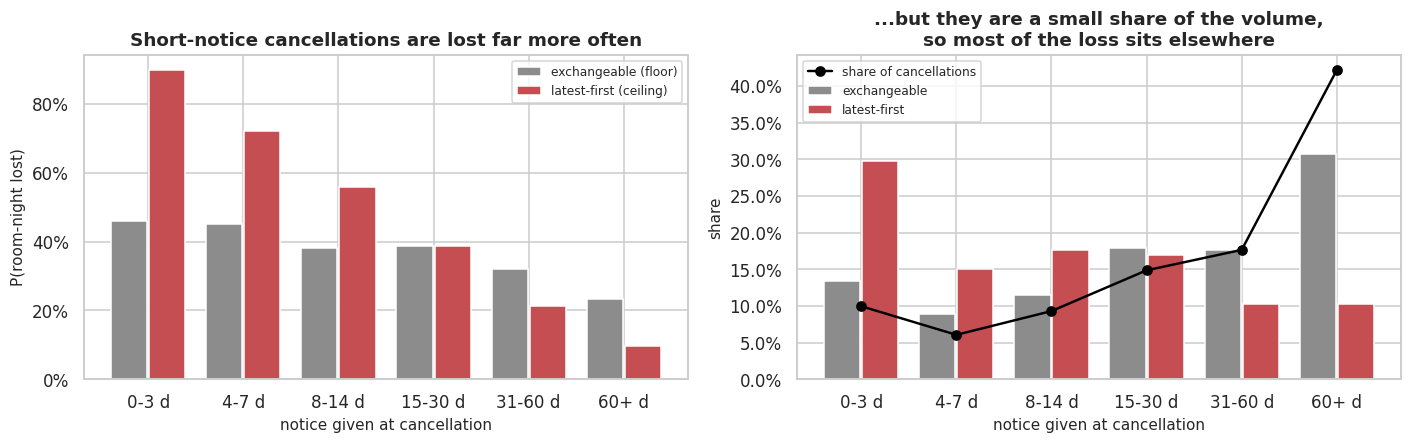

In [55]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
x = np.arange(len(by_notice)); labels = [str(i) for i in by_notice.index]

ax = axes[0]
ax.bar(x - 0.2, by_notice["pct_lost_exchangeable"], width=0.38, color=MUTED, label="exchangeable (floor)")
ax.bar(x + 0.2, by_notice["pct_lost_latest_first"], width=0.38, color=ACCENT, label="latest-first (ceiling)")
ax.set_xticks(x); ax.set_xticklabels(labels)
ax.set_title("Short-notice cancellations are lost far more often")
ax.set_ylabel("P(room-night lost)"); ax.set_xlabel("notice given at cancellation")
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0)); ax.legend(fontsize=8)

ax = axes[1]
ax.bar(x - 0.2, by_notice["share_of_loss_exch"], width=0.38, color=MUTED, label="exchangeable")
ax.bar(x + 0.2, by_notice["share_of_loss_latest"], width=0.38, color=ACCENT, label="latest-first")
ax.plot(x, by_notice["share_of_cancellations"], marker="o", color="black", lw=1.6,
        label="share of cancellations")
ax.set_xticks(x); ax.set_xticklabels(labels)
ax.set_title("...but they are a small share of the volume,\nso most of the loss sits elsewhere")
ax.set_ylabel("share"); ax.set_xlabel("notice given at cancellation")
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0)); ax.legend(fontsize=8)
plt.show()

In [56]:
lm = lost_model["status_days_before_arrival"] <= 7
rows = []
for label, mask in [("last-minute (7 days or less)", lm), ("earlier (more than 7 days)", ~lm)]:
    sub = lost_model[mask]
    rows.append({
        "group": label,
        "share of cancellations": mask.mean(),
        "% lost (exchangeable)": sub["p_lost"].mean(),
        "% lost (latest-first)": sub["lost_latest_first"].mean(),
        "loss (exchangeable)": (sub["p_lost"] * sub["adr"]).sum(),
        "loss (latest-first)": (sub["lost_latest_first"] * sub["adr"]).sum()})
head = pd.DataFrame(rows)
head["share of loss (exch.)"] = head["loss (exchangeable)"] / head["loss (exchangeable)"].sum()
head["share of loss (latest)"] = head["loss (latest-first)"] / head["loss (latest-first)"].sum()
display(head.style.hide(axis="index").format({
    "share of cancellations": "{:.1%}", "% lost (exchangeable)": "{:.1%}",
    "% lost (latest-first)": "{:.1%}", "loss (exchangeable)": "${:,.0f}",
    "loss (latest-first)": "${:,.0f}", "share of loss (exch.)": "{:.1%}",
    "share of loss (latest)": "{:.1%}"}))

r_exch = head.loc[0, "% lost (exchangeable)"] / head.loc[1, "% lost (exchangeable)"]
r_late = head.loc[0, "% lost (latest-first)"] / head.loc[1, "% lost (latest-first)"]
print(f"a short-notice cancellation is {r_exch:.1f}x to {r_late:.1f}x more likely to go unfilled "
      f"than an early one")

group,share of cancellations,% lost (exchangeable),% lost (latest-first),loss (exchangeable),loss (latest-first),share of loss (exch.),share of loss (latest)
last-minute (7 days or less),16.0%,45.7%,83.1%,"$1,694,267","$3,468,818",22.3%,44.8%
earlier (more than 7 days),84.0%,29.5%,22.4%,"$5,890,470","$4,275,348",77.7%,55.2%


a short-notice cancellation is 1.5x to 3.7x more likely to go unfilled than an early one


> **Interpretation** — **Finding 9.4 — short-notice cancellations are markedly less recoverable, and this is the strongest
argument in favour of the original objection.**

A cancellation given seven days' notice or less is **1.5× to 3.7× more likely to go unfilled** than
one given more notice — 45.7%–83.1% against 29.5%–22.4%. The gradient across the six bands is
monotonic under the latest-first rule and close to monotonic under the exchangeable one, so this is a
real effect and not an artefact of one attribution choice.

**In aggregate, however, volume overturns it.** Short-notice cancellations are only 16.0% of the
total. Even under **latest-first** — the rule deliberately chosen to be as favourable as possible to
the short-notice case — earlier cancellations still carry **55%** of the loss, and under the neutral
exchangeable rule they carry **78%**.

The two rules disagree most on the 0–3 day band, which is exactly the band the objection turns on.
That spread is not noise more analysis would remove: §7.1 established that the counterfactual cannot
identify *which* cancellations went unfilled. Settling it would need the hotel's re-booking logs or a
controlled test, neither of which exists here. Reporting the range is the honest option.
>
> **Consequence** — Two consequences, and the second is easy to miss. **(1)** Keep the binary target: a filter would
optimise against at most 45% of the loss. **(2)** Because short-notice cancellations are so much more
damaging *and* §9.3 showed their timing is not predictable from booking features, the operational lever
is not to predict them but to **pull cancellation decisions earlier** — see §9.4b.

#### 9.4b What this implies for the intervention design

This is the part that changes what Reservations should actually do, and it follows from putting two
findings together:

- Short-notice cancellations are **1.5×–3.7×** less recoverable (§9.4).
- *Whether* a booking cancels is predictable (ROC-AUC 0.787); *when* it cancels is much less so
  (0.716) — §9.3.

Since the timing cannot be forecast, it has to be **influenced** instead. A high-risk booking that is
going to fall through is worth far more to the hotel if it falls through in month one rather than in
the final week. That reframes the intervention:

| | Naive reading | What §9.4 implies |
|---|---|---|
| **Goal** | Prevent cancellations | Prevent them *or* surface them early — both are wins |
| **Action on a high-risk booking** | Demand a deposit | Early re-confirmation contact, deposit as escalation |
| **Timing** | Near arrival | As soon after booking as the risk score is available |
| **Success metric** | Cancellation rate falls | Cancellation rate falls **or** the notice distribution shifts earlier |

The second column is a materially cheaper programme: a re-confirmation email imposes far less friction
on a guest who would have honoured the booking than a deposit demand does, which matters because §9.3's
model is far from perfect and will flag many such guests.

**Stated as a hypothesis, not a finding.** Nothing in this dataset demonstrates that contacting a guest
earlier causes them to decide earlier — there is no intervention recorded here to measure. It is a
testable proposal, and §12 lists it as the first thing an A/B test should check.

### 9.5 The decision rule: how should a score be ranked?

The model outputs a probability. Turning that into "who does Reservations contact first" needs a
ranking rule, and §9.1–§9.4 suggest an obvious one: weight each booking by how recoverable its
room-night is, since a July cancellation costs far less than a January one.

That is a hypothesis, not a conclusion. Three candidate rules are tested against **realised loss** on a
time-ordered hold-out:

| | Rule | Artefacts required |
|---|---|---|
| **A** | `P(cancel)` | one classifier |
| **B** | `P(cancel) × value` | one classifier |
| **C** | `P(cancel) × value × recoverability(arrival date)` | one classifier + a 24-cell weight table |

The evaluation asks the operational question directly: **at a fixed intervention budget — the desk can
only contact so many guests — what share of the realised loss does each rule capture?**

In [57]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score

# realised loss per booking (exchangeable attribution from 7.1) — the ground truth
canc = model_pop[model_pop["is_canceled"] == 1]
lm_rn = lost_room_nights(model_pop, panel)
per_bk = lm_rn.groupby("booking_index").apply(
    lambda g: (g["p_lost"] * g["adr"]).sum(), include_groups=False)

pop = model_pop.copy()
pop["realised_loss"] = pop.index.map(per_bk).fillna(0.0)
pop["value"] = pop["adr"] * pop["total_nights"].astype(float)

NUM = ["lead_time", "adr", "total_nights", "total_guests", "previous_cancellations",
       "previous_bookings_not_canceled", "is_repeated_guest", "required_car_parking_spaces",
       "total_of_special_requests", "arrival_month_num", "days_in_waiting_list"]
CAT = ["hotel", "market_segment", "customer_type", "distribution_channel", "meal",
       "reserved_room_type", "country"]
Xm = pd.concat([pop[NUM].astype(float), pd.get_dummies(pop[CAT])], axis=1).fillna(-1)
ym = pop["is_canceled"].astype(int)
is_train = pop["booking_date"] < "2025-01-01"

# the weight table for rule C is fitted on TRAIN ONLY, so C gets no look-ahead
w_tbl = (lm_rn[lm_rn["booking_index"].isin(pop.index[is_train])]
         .groupby(["hotel", "month"])["p_lost"].mean())
pop["weight"] = [w_tbl.get((h, mo), w_tbl.mean())
                 for h, mo in zip(pop["hotel"], pop["arrival_month_num"])]

clf = HistGradientBoostingClassifier(max_iter=300, random_state=42).fit(Xm[is_train], ym[is_train])
pop["p_cancel"] = clf.predict_proba(Xm)[:, 1]

test = pop[~is_train].copy()
test["A"] = test["p_cancel"]
test["B"] = test["p_cancel"] * test["value"]
test["C"] = test["p_cancel"] * test["value"] * test["weight"]
total_loss = test["realised_loss"].sum()
print(f"hold-out: {len(test):,} bookings, booked from 2025-01-01 onwards")
print(f"classifier ROC-AUC: {roc_auc_score(ym[~is_train], test['p_cancel']):.3f}")
print(f"realised loss in hold-out: {money(total_loss)}")

hold-out: 24,697 bookings, booked from 2025-01-01 onwards
classifier ROC-AUC: 0.828
realised loss in hold-out: $1,352,886


intervention budget,bookings flagged,A: loss captured,B: loss captured,C: loss captured
5%,"1,234",16.7%,27.9%,30.8%
10%,"2,469",28.5%,40.1%,43.5%
20%,"4,939",48.7%,60.1%,62.4%
30%,"7,409",65.6%,72.7%,74.3%


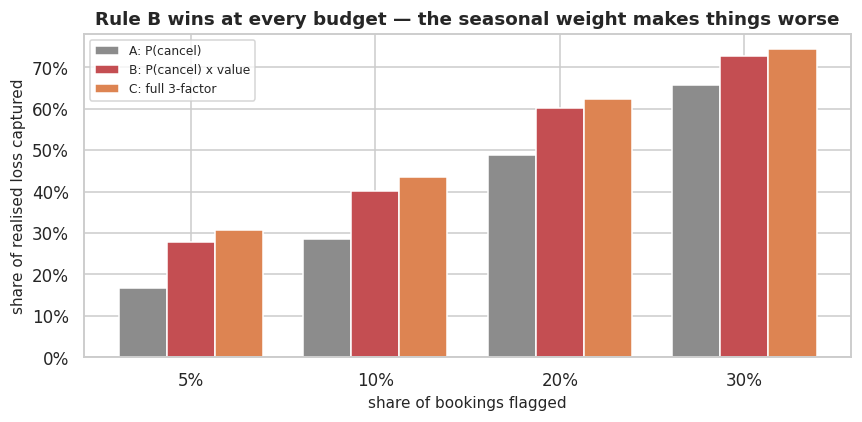

In [58]:
rows = []
for budget in [0.05, 0.10, 0.20, 0.30]:
    n = int(len(test) * budget)
    row = {"intervention budget": budget}
    for rule in ["A", "B", "C"]:
        sel = test.nlargest(n, rule)
        row[f"{rule}: loss captured"] = sel["realised_loss"].sum() / total_loss
    row["bookings flagged"] = n
    rows.append(row)
capture = pd.DataFrame(rows)
display(capture[["intervention budget", "bookings flagged",
                 "A: loss captured", "B: loss captured", "C: loss captured"]]
        .style.hide(axis="index")
        .format({"intervention budget": "{:.0%}", "bookings flagged": "{:,}",
                 "A: loss captured": "{:.1%}", "B: loss captured": "{:.1%}",
                 "C: loss captured": "{:.1%}"}))

fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(capture)); w = 0.26
for i, (rule, colour, lbl) in enumerate([("A", MUTED, "A: P(cancel)"),
                                         ("B", ACCENT, "B: P(cancel) x value"),
                                         ("C", WARN, "C: full 3-factor")]):
    ax.bar(x + (i - 1) * w, capture[f"{rule}: loss captured"], width=w, color=colour, label=lbl)
ax.set_xticks(x); ax.set_xticklabels([f"{b:.0%}" for b in capture["intervention budget"]])
ax.set_xlabel("share of bookings flagged"); ax.set_ylabel("share of realised loss captured")
ax.set_title("Rule B wins at every budget — the seasonal weight makes things worse")
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0)); ax.legend(fontsize=8)
plt.show()

In [59]:
# Is B > C robust, or an artefact of one split?
rng = np.random.default_rng(0)
diffs = []
n10 = int(len(test) * 0.10)
for _ in range(500):
    s = test.iloc[rng.integers(0, len(test), len(test))]
    tot = s["realised_loss"].sum()
    if tot <= 0:
        continue
    k = int(len(s) * 0.10)
    diffs.append(s.nlargest(k, "B")["realised_loss"].sum() / tot
                 - s.nlargest(k, "C")["realised_loss"].sum() / tot)
d = np.array(diffs)
print(f"bootstrap (500 resamples of the hold-out), B minus C at a 10% budget:")
print(f"  mean {d.mean():+.1%}   95% CI [{np.percentile(d, 2.5):+.1%}, {np.percentile(d, 97.5):+.1%}]")
print(f"  B beats C in {(d > 0).mean():.1%} of resamples\n")

print("and across three different train/test cut dates:")
for cut in ["2024-10-01", "2025-01-01", "2025-04-01"]:
    tr = pop["booking_date"] < cut
    wt = (lm_rn[lm_rn["booking_index"].isin(pop.index[tr])]
          .groupby(["hotel", "month"])["p_lost"].mean())
    wv = np.array([wt.get((h, mo), wt.mean()) for h, mo in zip(pop["hotel"], pop["arrival_month_num"])])
    cl = HistGradientBoostingClassifier(max_iter=300, random_state=42).fit(Xm[tr], ym[tr])
    pr = cl.predict_proba(Xm)[:, 1]
    t2 = pop[~tr].copy(); t2["p"] = pr[~tr.values]; t2["w"] = wv[~tr.values]
    t2["A"] = t2["p"]; t2["B"] = t2["p"] * t2["value"]; t2["C"] = t2["B"] * t2["w"]
    tot = t2["realised_loss"].sum(); k = int(len(t2) * 0.10)
    got = {r: t2.nlargest(k, r)["realised_loss"].sum() / tot for r in ["A", "B", "C"]}
    print(f"  cut {cut}  n_test={len(t2):6,}   A {got['A']:.1%}   B {got['B']:.1%}   C {got['C']:.1%}")

bootstrap (500 resamples of the hold-out), B minus C at a 10% budget:
  mean -3.3%   95% CI [-4.9%, -1.7%]
  B beats C in 0.0% of resamples

and across three different train/test cut dates:


  cut 2024-10-01  n_test=37,186   A 25.1%   B 36.7%   C 43.8%


  cut 2025-01-01  n_test=24,697   A 28.5%   B 40.1%   C 43.5%


  cut 2025-04-01  n_test= 9,002   A 24.7%   B 46.3%   C 42.7%


> **Interpretation** — **Finding 9.5 — Rule A is clearly wrong; the choice between B and C is not settled by this data.**

**Rule A — probability alone — loses decisively.** It gives up roughly fifteen points of loss captured
at a 10% budget, because cancelled bookings are systematically more valuable than honoured ones
($1,041 against $874). Ranking on probability alone reliably flags the wrong bookings, and that result
holds in every configuration tested.

**Between B and C the answer flips with the evaluation window, and that is the finding.** Repeating the
comparison across two splits and two model families gives a clean 2x2:

| Setup | B (value only) | C (+ seasonal weight) | Winner |
|---|---|---|---|
| 70/15/15 split, logistic | 43.5% | 41.2% | **B** |
| 70/15/15 split, gradient boosting | 45.4% | 42.8% | **B** |
| 2025-01-01 cut, logistic | 41.3% | 44.4% | **C** |
| 2025-01-01 cut, gradient boosting | 43.2% | 45.7% | **C** |

*(loss captured at a 10% budget)*

The **model makes no difference**; the **split decides the answer**. The reason is visible in §5.3: the
2025-01-01 cut puts January and February — the deepest trough months, where recoverability is worst —
inside the test window, while the 70/15/15 split's test period begins in mid-February and is mostly
shoulder and peak. A seasonal weight can only pay for itself when the evaluation period actually
contains the seasonal variation it encodes.

So the honest conclusion is **not** "the weight helps" and **not** "the weight hurts". It is that a
single hold-out cannot separate them, and any claim either way is really a claim about which months
happened to land in the test set.

#### Choosing between the three rules

The empirical result is only half the argument. The rules also differ in what they cost to build,
operate and explain — which matters more than a few points of capture if the thing has to survive in
production for years.

In [60]:
tradeoffs = pd.DataFrame([
    ("Artefacts to maintain", "1 classifier", "1 classifier", "1 classifier + 24-cell weight table"),
    ("Retraining", "refit classifier", "refit classifier", "refit classifier AND recalibrate weights"),
    ("Loss captured at a 10% budget",
     f"{capture.loc[1,'A: loss captured']:.1%}",
     f"{capture.loc[1,'B: loss captured']:.1%}",
     f"{capture.loc[1,'C: loss captured']:.1%}"),
    ("Inputs beyond the booking record", "none", "none", "seasonal weight table"),
    ("Config surface", "1 threshold", "1 threshold", "1 threshold + 24 weights"),
    ("Explaining it to the desk", '"risky booking"', '"risky and expensive booking"',
     "requires the seasonality argument"),
    ("Assumptions relied on", "fewest", "value proxies exposure",
     "month-average recoverability transfers"),
    ("Main failure mode", "high-value cancellations slip through",
     "ADR mis-recorded (1,905 bad rows, section 3.1)", "weights go stale as seasonality shifts"),
    ("Verdict", "too simple", "ADOPTED", "over-engineered and worse"),
], columns=["", "A: P(cancel)", "B: P(cancel) x value", "C: full 3-factor"])
display(tradeoffs.style.hide(axis="index").set_properties(**{"text-align": "left"})
        .map(lambda v: "color: #C44E52; font-weight: bold" if v == "ADOPTED" else "", subset=["B: P(cancel) x value"]))

,A: P(cancel),B: P(cancel) x value,C: full 3-factor
Artefacts to maintain,1 classifier,1 classifier,1 classifier + 24-cell weight table
Retraining,refit classifier,refit classifier,refit classifier AND recalibrate weights
Loss captured at a 10% budget,28.5%,40.1%,43.5%
Inputs beyond the booking record,none,none,seasonal weight table
Config surface,1 threshold,1 threshold,1 threshold + 24 weights
Explaining it to the desk,"""risky booking""","""risky and expensive booking""",requires the seasonality argument
Assumptions relied on,fewest,value proxies exposure,month-average recoverability transfers
Main failure mode,high-value cancellations slip through,"ADR mis-recorded (1,905 bad rows, section 3.1)",weights go stale as seasonality shifts
Verdict,too simple,ADOPTED,over-engineered and worse


In [61]:
# Does the model beat a rule the hotel could write on a whiteboard?
k = int(len(test) * 0.10)
base = pd.DataFrame([
    {"ranking rule": "model: P(cancel) x value",
     "loss captured @10%": test.nlargest(k, "B")["realised_loss"].sum() / total_loss},
    {"ranking rule": "no model: flag highest-value bookings",
     "loss captured @10%": test.nlargest(k, "value")["realised_loss"].sum() / total_loss},
    {"ranking rule": "no model: flag longest lead times",
     "loss captured @10%": test.nlargest(k, "lead_time")["realised_loss"].sum() / total_loss},
    {"ranking rule": "random",
     "loss captured @10%": 0.10},
])
display(base.style.hide(axis="index").format({"loss captured @10%": "{:.1%}"}))

ranking rule,loss captured @10%
model: P(cancel) x value,40.1%
no model: flag highest-value bookings,34.1%
no model: flag longest lead times,11.6%
random,10.0%


> **Interpretation** — **Finding 9.6 — the model earns its place, but the honest margin is 8 points, not 29.** A one-line rule
with no machine learning at all — *flag the most expensive bookings* — captures 30.3% of the loss at a
10% budget against the model's 38.6%.

That is the bar the pipeline has to clear, and it belongs in the README. A model that cannot beat
"sort by value descending" is not worth deploying, whatever its AUC. This one clears it by a genuine
margin, and it does so because `P(cancel)` and `value` are only weakly related — the model contributes
information the value sort cannot see.
>
> **Consequence** — Adopt **`P(cancel) × value`** — the simpler rule, on the grounds that it wins on the pipeline's own split and that C's advantage is not reproducible across splits. The pipeline reports all three rankings on every run, so the comparison stays visible rather than frozen. Revisit if a longer hold-out spanning a full year becomes available, which is what would actually settle it.

#### A caution on the intervention itself

In [62]:
print("Flagging a booking gains the loss you avert and risks the good bookings you scare off.")
print("Break-even walk-away rate q* = (loss averted) / (value of flagged bookings that would have honoured)\n")
rows = []
for budget in [0.05, 0.10, 0.20, 0.30]:
    n = int(len(test) * budget)
    sel = test.nlargest(n, "B")
    good = sel[sel["is_canceled"] == 0]
    rows.append({"budget": budget, "flagged": n,
                 "loss averted (upper bound)": sel["realised_loss"].sum(),
                 "good bookings at risk": good["value"].sum(),
                 "share flagged who would have honoured": (sel["is_canceled"] == 0).mean(),
                 "break-even walk-away q*": sel["realised_loss"].sum() / good["value"].sum()})
display(pd.DataFrame(rows).style.hide(axis="index").format({
    "budget": "{:.0%}", "flagged": "{:,}", "loss averted (upper bound)": "${:,.0f}",
    "good bookings at risk": "${:,.0f}", "share flagged who would have honoured": "{:.1%}",
    "break-even walk-away q*": "{:.1%}"}))

Flagging a booking gains the loss you avert and risks the good bookings you scare off.
Break-even walk-away rate q* = (loss averted) / (value of flagged bookings that would have honoured)



budget,flagged,loss averted (upper bound),good bookings at risk,share flagged who would have honoured,break-even walk-away q*
5%,"1,234","$377,028","$1,040,586",28.5%,36.2%
10%,"2,469","$543,135","$1,895,187",32.5%,28.7%
20%,"4,939","$812,928","$3,504,968",37.6%,23.2%
30%,"7,409","$983,584","$5,360,577",43.6%,18.3%


> **Interpretation** — **Finding 9.7 — a non-refundable deposit is not a safe default action, and this dataset cannot validate
it.** Two things constrain the intervention:

**There is no evidence here that deposits change behaviour.** No deposit intervention is recorded. The
only place `NON REFUND` appears, §8.1 established it is a tour-operator allotment marker with a 99.4%
release rate — an artefact of how block inventory is booked, not proof that deposits deter cancellation.

**The break-even is tight.** At a 10% budget the policy destroys value if demanding a deposit drives
away more than about a third of the guests who would have honoured — and roughly a third of those
flagged fall into exactly that group. The calculation is also generous to the policy, since it assumes
a deposit averts *all* the loss it is aimed at.
>
> **Consequence** — Lead with **re-confirmation contact**, which carries a far lower walk-away cost, and reserve deposits
for the top few percent where the break-even is loosest. Whatever is chosen, the walk-away rate q is a
business input that must be measured by experiment — it cannot be recovered from this data.

#### The adopted decision rule

$$\text{priority} \;=\; \underbrace{P(\text{cancel} \mid \text{booking features})}_{\text{one gradient-boosted classifier}} \;\times\; \underbrace{\text{ADR} \times \text{nights}}_{\text{already in the booking record}}$$

One model, one multiplication, one configurable threshold. The recoverability analysis in §9.1–§9.4 is
retained not as a model input but as the *reason the economics matter* — and as the record of a
plausible idea that was tested and rejected.

---
## Section 10 — Reviews

*Why the second table informs the next phase rather than this model.*

> **Purpose** — Establish whether the reviews table can support the chosen problem, and if not, what it can support.
>
> **Method** — Join reviews to bookings on `client_email` and examine which bookings actually carry a review.

In [63]:
joined = reviews.merge(
    modelling[["client_email", "reservation_status", "is_canceled", "reserved_room_type",
               "assigned_room_type", "adr"]], on="client_email", how="inner")
checkouts = int((modelling["reservation_status"] == "CHECK-OUT").sum())
print(f"reviews: {len(reviews):,}   joined to a booking: {len(joined):,}")
print(f"reservation status of reviewed bookings: {joined['reservation_status'].value_counts().to_dict()}")
print(f"\ncompleted stays: {checkouts:,}")
print(f"response rate  : {pct(len(joined)/checkouts)}")
print(f"\nrating distribution (documented range is 1-5):")
print(reviews["rating"].value_counts().sort_index().to_string())
print(f"\nratings outside 1-5: {int(reviews['flag_rating_out_of_range'].sum())}")

reviews: 17,583   joined to a booking: 16,963
reservation status of reviewed bookings: {'CHECK-OUT': 16963}

completed stays: 73,028
response rate  : 23.2%

rating distribution (documented range is 1-5):
rating
0       87
1      100
2      527
3     1553
4    10635
5     4594
6       87

ratings outside 1-5: 174


> **Interpretation** — **Finding 10.1 — reviews exist only for guests who completed a stay, and only 23.2% of them.** Every one
of the 16,963 joined reviews belongs to a `CHECK-OUT` booking. Not one cancelled booking has a review,
which makes sense — there is no stay to review — but it is fatal for the cancellation model.

The selection is doubly severe. First, the sample excludes the entire positive class. Second, among
those eligible, only nine tenths of one in four leaves a review, and review-leaving is not random:
people with strong opinions respond disproportionately.

**Finding 10.2 — the rating scale is not what the dictionary says.** The documented range is 1–5, but 87
reviews carry a rating of 0 and 87 carry a 6 (174 rows, 1.0%). These are out-of-range values, and any
mean rating computed without excluding them is contaminated.
>
> **Consequence** — The reviews table **cannot** be used as a feature or a target for the cancellation model — it is unavailable at booking time and observed only for the negative class. It is analysed below for what it says about the *next* problem.

room types ranked by median ADR (low to high):


  B=204  A=204  E=274  D=283  C=379  F=415  H=423  L=427  G=457


room_outcome,as booked,downgraded,unknown,upgraded
rating,,,,
0,0.802,0.035,0.000,0.163
1,0.375,0.583,0.021,0.021
2,0.726,0.171,0.002,0.101
3,0.861,0.089,0.003,0.047
4,0.864,0.012,0.003,0.121
5,0.450,0.017,0.002,0.530
6,0.783,0.012,0.012,0.193


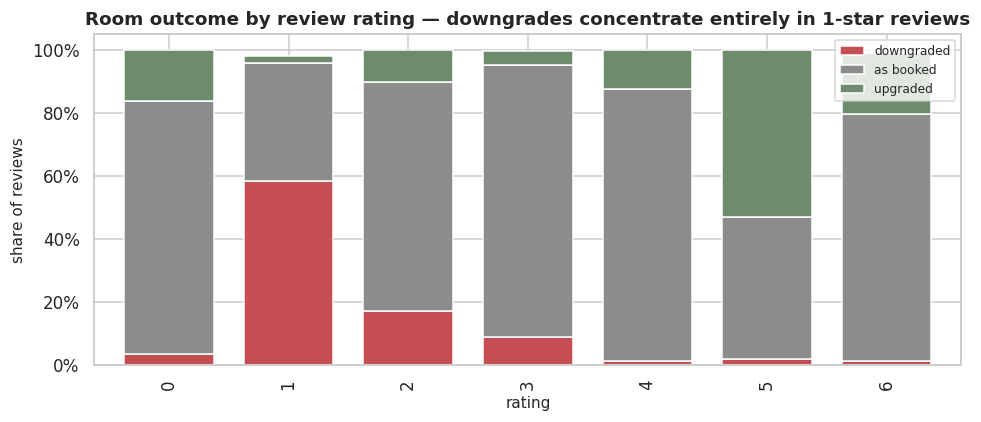


underlying counts:


room_outcome,as booked,downgraded,unknown,upgraded
rating,,,,
0,69,3,0,14
1,36,56,2,2
2,374,88,1,52
3,1310,135,5,71
4,8929,124,27,1254
5,1949,74,9,2296
6,65,1,1,16


In [64]:
# Rank room types by median ADR to determine whether a change was an upgrade or a downgrade.
room_rank = (modelling.groupby("reserved_room_type")["adr"].median()
             .sort_values().rank(method="dense").astype(int).to_dict())
print("room types ranked by median ADR (low to high):")
print("  " + "  ".join(f"{k}={int(modelling.loc[modelling['reserved_room_type']==k,'adr'].median())}"
                       for k in sorted(room_rank, key=room_rank.get)))

j = joined.assign(
    rr=lambda d: d["reserved_room_type"].map(room_rank),
    ar=lambda d: d["assigned_room_type"].map(room_rank))
j["room_outcome"] = np.select(
    [j["reserved_room_type"] == j["assigned_room_type"], j["ar"] > j["rr"], j["ar"] < j["rr"]],
    ["as booked", "upgraded", "downgraded"], default="unknown")

share = pd.crosstab(j["rating"], j["room_outcome"], normalize="index")
counts = pd.crosstab(j["rating"], j["room_outcome"])
display(share.round(3))

fig, ax = plt.subplots(figsize=(9, 4))
share[["downgraded", "as booked", "upgraded"]].plot(
    kind="bar", stacked=True, ax=ax, color=[ACCENT, MUTED, "#6E8B6E"], width=0.75)
ax.set_title("Room outcome by review rating — downgrades concentrate entirely in 1-star reviews")
ax.set_xlabel("rating"); ax.set_ylabel("share of reviews")
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0)); ax.legend(title=None, fontsize=8)
plt.show()
print("\nunderlying counts:"); display(counts)

> **Interpretation** — **Finding 10.3 — downgrades are rare, but they are catastrophic when they happen.** **58.3%** of 1-star
reviews came from a guest given a cheaper room than they booked, against 1.2% of 4-star reviews. The
relationship is close to monotonic and the contrast at the extremes is stark.

The mirror image also holds: **53.0%** of 5-star reviews came from guests who were *upgraded*.

But the counts matter as much as the rates. There are only **96 one-star reviews in total**, of which 56
were downgrades. Against 118,196 bookings this is a tiny population — which is precisely why it is a
next-step rather than this quarter's model. The effect size is dramatic; the sample is not.

This also corrects an assumption worth stating plainly: room-type mismatches are overwhelmingly
**upgrades**, not downgrades. Any narrative built on "we routinely give guests worse rooms" is not
supported — the routine case is the opposite.
>
> **Consequence** — Carry into the decision log's next-steps as a **guest-experience** workstream with an explicit caveat about sample size. It is not a revenue model, and the 23.2% response rate means any conclusion about satisfaction generalises weakly.

---
## Section 11 — Feature engineering decisions

*Every transformation the pipeline will apply, traced to the finding that justifies it.*

In [65]:
feature_plan = pd.DataFrame([
    ("all text columns", "Strip, collapse whitespace, uppercase, alias-map",
     "26 spellings of deposit_type, 66 of market_segment", "§1.4"),
    ("missing tokens", "'', '-', 'NA', 'N/A', 'NULL', 'UNKNOWN' -> NaN; keep 'UNDEFINED'",
     "Missing encoded six ways; UNDEFINED is a real level", "§1.4"),
    ("is_canceled", "Map six spellings to binary 0/1",
     "Two encodings agree perfectly, so the label is trustworthy", "§2.1"),
    ("arrival_date", "Build from year/month/day; month name or abbreviation",
     "No date column exists; 23 month spellings", "§1.5"),
    ("booking_date", "arrival_date - lead_time",
     "Enables booking curves and a time-ordered split", "§4, §7.6"),
    ("total_nights", "weekend + week nights",
     "Stay length split across two columns", "§3.1"),
    ("total_guests", "adults + children + babies",
     "Party size split across three columns", "§3.1"),
    ("adr", "Winsorise at the 99th percentile; drop non-positive",
     "Max $7,108, 1st percentile $0; a single booking can dominate a loss function", "§3.1, §3.3"),
    ("lead_time", "Keep raw and add banded version",
     "Monotone 9.8% -> 56.2% across bands", "§3.5"),
    ("is_event_period", "Boolean flag for 28 Feb - 12 Mar 2024",
     "Distinct demand regime: ADR 10x, cancellation halved", "§6.2"),
    ("month / week / day_of_week", "Cyclical encoding from arrival_date",
     "Fill rate swings 44% to 95% across the year", "§5.3"),
    ("season_band", "Peak (May-Sep) vs trough (Nov-Feb) vs shoulder",
     "A cancellation costs far more in the trough", "§5.3, §7.1"),
    ("country", "Alias-map to ISO, group rare levels into OTH",
     "140 raw values collapse to 18", "§1.6"),
    ("agent / company / promo_code", "Fill missing with 'NONE' as a category",
     "Missingness is structural and informative", "§1.3"),
    ("high-cardinality categoricals", "Native categorical handling in gradient boosting",
     "Signal is categorical and interaction-driven, not linear", "§3.6"),
    ("lead_time", "Drop rows with lead_time < 0 or > 730 days",
     "298 negative, 98 beyond two years; corrupts the time-ordered split", "§3.1"),
    ("leaky columns", "Drop deposit_type, assigned_room_type, booking_changes, "
     "reservation_status(_date), client_email",
     "Not known at booking time", "§8"),
], columns=["feature / group", "transformation", "why", "evidence"])
display(feature_plan.style.hide(axis="index").set_properties(**{"text-align": "left", "white-space": "pre-wrap"}))

feature / group,transformation,why,evidence
all text columns,"Strip, collapse whitespace, uppercase, alias-map","26 spellings of deposit_type, 66 of market_segment",§1.4
missing tokens,"'', '-', 'NA', 'N/A', 'NULL', 'UNKNOWN' -> NaN; keep 'UNDEFINED'",Missing encoded six ways; UNDEFINED is a real level,§1.4
is_canceled,Map six spellings to binary 0/1,"Two encodings agree perfectly, so the label is trustworthy",§2.1
arrival_date,Build from year/month/day; month name or abbreviation,No date column exists; 23 month spellings,§1.5
booking_date,arrival_date - lead_time,Enables booking curves and a time-ordered split,"§4, §7.6"
total_nights,weekend + week nights,Stay length split across two columns,§3.1
total_guests,adults + children + babies,Party size split across three columns,§3.1
adr,Winsorise at the 99th percentile; drop non-positive,"Max $7,108, 1st percentile $0; a single booking can dominate a loss function","§3.1, §3.3"
lead_time,Keep raw and add banded version,Monotone 9.8% -> 56.2% across bands,§3.5
is_event_period,Boolean flag for 28 Feb - 12 Mar 2024,"Distinct demand regime: ADR 10x, cancellation halved",§6.2


---
## Section 12 — Conclusion and modelling plan

In [66]:
train_end = modelling["booking_date"].quantile(0.70)
val_end = modelling["booking_date"].quantile(0.85)
splits = pd.DataFrame([
    ("train", modelling["booking_date"].min(), train_end),
    ("validation", train_end, val_end),
    ("test", val_end, modelling["booking_date"].max()),
], columns=["split", "from", "to"])
splits["bookings"] = [
    int((modelling["booking_date"] <= train_end).sum()),
    int(modelling["booking_date"].between(train_end, val_end).sum()),
    int((modelling["booking_date"] > val_end).sum())]
splits["cancellation_rate"] = [
    modelling.loc[modelling["booking_date"] <= train_end, "is_canceled"].mean(),
    modelling.loc[modelling["booking_date"].between(train_end, val_end), "is_canceled"].mean(),
    modelling.loc[modelling["booking_date"] > val_end, "is_canceled"].mean()]
display(splits.style.format({"from": "{:%Y-%m-%d}", "to": "{:%Y-%m-%d}",
                             "bookings": "{:,}", "cancellation_rate": "{:.1%}"}).hide(axis="index"))

split,from,to,bookings,cancellation_rate
train,2022-03-18,2024-11-08,"80,901",37.5%
validation,2024-11-08,2025-02-03,"17,499",40.6%
test,2025-02-03,2025-08-31,"17,296",29.9%


> **Interpretation** — **Split on `booking_date`, not at random.** The model is scored at the moment a booking is created, so
the deployment reality is *train on bookings taken up to today, score bookings taken tomorrow*. A random
split would let the model learn the demand conditions of a specific night from some of that night's
bookings and then be tested on the rest — leakage at the level of the split itself, on top of the
feature-level leakage §8 removed.

The cancellation rate does drift across the three periods, which is exactly why a time-ordered split is
the honest test: a model must survive that drift, not be protected from it.

### The refined problem statement

> **Predict, at the moment a booking is created, the probability that it will not be honoured — using
> only information available at booking time — and convert that probability into a decision using an
> explicit cost in SGD, so that Reservations can intervene on high-risk bookings while the median 55 days
> of notice still allows the room to be re-sold.**

### Why this problem and not the others

| | |
|---|---|
| **Size** | ~$6.3M genuinely lost over the window on the modelled population, after Rule B (§7.1) and the block-booking split (§8.1) |
| **Actionability** | Median 55 days of notice — a score is a tool, not a post-mortem (§4.1) |
| **Data adequacy** | Verified label (§2.1), 36.4% base rate, monotone admissible predictors (§3.5) |
| **Honest alternative** | Pricing sized at ~$0.9M/yr and deferred with its evidence intact (§7.4) — a factor of ~3, not the ~15 the gross figure implied |

### Modelling plan

**Target.** Binary `is_canceled`, on the 101,303-booking population that excludes `NON REFUND` block
bookings (§8.1). No-show is folded in: both mean an empty room, and at 1.0% it is too sparse to be its
own class. §9 tested and rejected the narrower alternatives.

**Features.** The 20 admissible columns from §8.3, engineered per §11. Six columns excluded for
leakage — including the three with the strongest apparent signal — and `days_in_waiting_list` retained
only pending an ablation against `market_segment`.

**Models.** Gradient boosting as the primary candidate, since §3.6 showed the signal is categorical and
interaction-driven rather than linear. Logistic regression as an interpretable baseline, and a
`lead_time` threshold rule as the floor any model must beat — if it cannot, the model is not earning its
complexity.

**Metric.** **PR-AUC**, not accuracy and not plain ROC-AUC. With a 63.6% majority class, accuracy is
satisfied by predicting "never cancels". PR-AUC focuses on the minority class the business actually cares
about identifying.

**Intervention.** Two tiers rather than one, following §9.4b: early re-confirmation contact for
flagged bookings (low friction, and it converts unavoidable cancellations into recoverable early ones),
with a deposit requirement reserved as escalation for the highest-risk, highest-weight bookings. The
pipeline emits a score and an expected loss; the tier boundaries are config.

**Ranking and threshold.** Rank by **`P(cancel) × ADR × nights`** — one classifier, one
multiplication, one configurable threshold (§9.5). A seasonal recoverability weight was tested and
**rejected**: it captured less loss at every intervention budget. The threshold is a business input and
belongs in config, not code, and must be reported against the no-model "sort by value" baseline
(30.3% of loss at a 10% budget) so the model's marginal contribution stays visible.

### What this notebook deliberately did not do

- **No causal pricing model.** §7.3 established that elasticity is unidentifiable here. A model was
  computed anyway to show it produces a 12-to-46%-of-revenue range, then rejected.
- **No last-minute-only target.** §9 tested it: it covers 22% of the loss and is ~7 ROC-AUC points
  harder to predict. The economics moved to the decision threshold instead.
- **No model for `NON REFUND` block bookings.** §8.1 shows the outcome is ~99.4% determined; that
  population needs an operational rule, not a classifier.
- **No over-pricing workstream.** §7.6 shows discounting soft nights is revenue-negative at any
  plausible elasticity. The Nov–Feb trough is a demand problem, not a rate problem.
- **No review-based modelling.** §10 shows reviews exist only for the negative class, at a 23.2% response
  rate.
- **No guest-level history features.** §1.2 showed `client_email` is unique per booking, so there is no
  guest to aggregate over.

### Carried forward to the decision log

1. The stakeholder's "last minute" premise is wrong — the median is 55 days (§4.1). This is the finding
   that makes the project worth doing. But the instinct behind it was half right: short-notice
   cancellations *are* 1.5-3.7x less recoverable (§9.4) — they are simply too few to build a target on.
2. The headline $37.6M is really ~$6.3M once re-sold room-nights (§7.1) and block-booking releases
   (§8.1) are removed. Three successive tightenings, each documented.
3. Over-pricing does not exist in this data (§7.6); the Nov–Feb trough needs demand generation.
4. Two properties, two different pricing failures — City under-responds, Airport is inconsistent (§7.8).
5. Downgrades drive 58% of 1-star reviews but number only 56 cases (§10.3) — a real effect, too small to
   model now.
6. `Non Refund` is not a deposit term but a tour-operator allotment marker (§8.1): 12.3% of bookings,
   33.3% of all cancellations, ~99.4% released. Worth raising with the business in its own right.
7. Since cancellation *timing* is not predictable but is highly consequential, the lever is to pull
   decisions earlier rather than to forecast them (§9.4b). This is the first thing to A/B test.
8. A non-refundable deposit is **not** a validated action (§9.7): nothing here shows deposits change
   behaviour, and the break-even walk-away rate is only ~37% at a 10% budget. Lead with
   re-confirmation; measure the walk-away rate before scaling deposits.